In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, accuracy_score

# Load your data
data = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# --- Feature Preprocessing and Engineering (same as before) ---
# Compute correlation matrix and drop highly correlated features
numeric_features = data.select_dtypes('number')
corr_matrix = numeric_features.corr().abs()
high_corr_features = np.where(corr_matrix > 0.95)
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y])
                   for x, y in zip(*high_corr_features) if x != y]
print("Highly Correlated Pairs (before dropping):", high_corr_pairs)

data.drop(columns = [
    'Performance_G+A','Performance_G-PK','Standard_Gls','Playing Time_Starts','Playing Time_Min','90s','Playing Time_Min%',
    'Starts_Starts','Expected_npxG+xAG','Expected_xAG','Receiving_PrgR','Standard_Sh','Total_Att','Short_Cmp','Att',
    'Pass Types_Live','Short_Att','Expected_xA','KP','SCA Types_PassLive','SCA_SCA','Touches_Mid 3rd','Touches_Live',
    'Carries_Carries','Touches_Touches','Receiving_Rec','Take-Ons_Att','Team Success (xG)_onxG','Team Success_onGA',
    'Team Success (xG)_onxG','Ast','Performance_PK','Standard_PK','Standard_PKatt'
] , inplace = True)

# Compute correlation matrix again after dropping
numeric_features = data.select_dtypes('number')
corr_matrix = numeric_features.corr().abs()
high_corr_features = np.where(corr_matrix > 0.95)
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y])
                   for x, y in zip(*high_corr_features) if x != y]
print("Highly Correlated Pairs (after dropping):", high_corr_pairs)


# Feature Engineering
data['Goal_Conversion_Rate'] = data['Performance_Gls'] / data['Standard_SoT']
data['xG_Overperformance'] = data['Performance_Gls'] - data['Expected_xG']
data['Shot_Accuracy'] = data['Standard_SoT'] / data['Expected_xG']
data['Team_Goal_Contribution'] = data['Performance_Gls'] / (data['Team Success_onG'] + 1)
data['Shooting_Efficiency'] = data['Standard_SoT'] / (data['Expected_npxG'] + 1)
data.replace([np.inf, -np.inf], np.nan, inplace=True)
data.fillna(0, inplace=True)

# Split data into train and test sets based on season (modified for 2024 prediction)
X1 = data[data['season'] == 2020]
X2 = data[data['season'] == 2021]
X3 = data[data['season'] == 2022]
X4 = data[data['season'] == 2023]
X_train = pd.concat([X1,X2,X3,X4] , axis = 0)
X_train_features = X_train.drop(columns = ['player','league','pos','season','age','nation','team','alter_position','Performance_Gls'])
y_train = X_train['Performance_Gls']


X_test = data[data['season'] == 2024]
X_test_features = X_test.drop(columns = ['player','league','pos','season','age','nation','team','alter_position','Performance_Gls'])
y_test = X_test['Performance_Gls']


# --- Model Training (same models as before) ---
model0 = make_pipeline(
    StandardScaler(),
    Ridge()
)
model0.fit(X_train_features , y_train)


model1 = make_pipeline(
    StandardScaler(),
    GradientBoostingClassifier(random_state = 42 , max_depth = 4 , n_estimators = 30)
)
model1.fit(X_train_features , y_train)


model3 = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(random_state = 42 , n_estimators = 400 , max_features = None , min_samples_leaf = 2 , min_samples_split= 4)
)
model3.fit(X_train_features , y_train)


# --- Prediction for 2024 and Evaluation ---
y_pred_ridge_2024 = model0.predict(X_test_features)
y_pred_gbc_2024 = model1.predict(X_test_features)
y_pred_rfc_2024 = model3.predict(X_test_features)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge_2024)
# For classification models, we might need to adapt the target to be categorical for accuracy to be meaningful for goal prediction.
# For now, we will calculate accuracy as if it's a classification problem, but this might not be the best metric for goal prediction.
# Consider using regression metrics like MAE, MSE, RMSE for evaluating goal prediction.
acc_gbc = model1.score(X_test_features, y_test)
acc_rfc = model3.score(X_test_features, y_test)


print("Ridge Regression - Mean Absolute Error (MAE) on 2024 data:", mae_ridge)
print("Gradient Boosting Classifier - Accuracy on 2024 data:", acc_gbc)
print("Random Forest Classifier - Accuracy on 2024 data:", acc_rfc)


# --- Feature Importance (optional) ---
importances_rfc = model3.named_steps['randomforestclassifier'].feature_importances_
feature_names = X_train_features.columns
sorted_indices_rfc = np.argsort(importances_rfc)[::-1]

print("\nTop Feature Importances from RandomForestClassifier:")
for i in sorted_indices_rfc[:10]:
    print(f"{feature_names[i]}: {importances_rfc[i]:.4f}")


importances_gbc = model1.named_steps['gradientboostingclassifier'].feature_importances_
sorted_indices_gbc = np.argsort(importances_gbc)[::-1]

print("\nTop Feature Importances from GradientBoostingClassifier:")
for i in sorted_indices_gbc[:10]:
    print(f"{feature_names[i]}: {importances_gbc[i]:.4f}")


# --- Add Predicted Goals to the DataFrame (for 2024 predictions) ---
data['predicted_goals_ridge_2024'] = ""
data['predicted_goals_gbc_2024'] = ""
data['predicted_goals_rfc_2024'] = ""


data.loc[data["season"] == 2024, "predicted_goals_ridge_2024"] = y_pred_ridge_2024
data.loc[data["season"] == 2024, "predicted_goals_gbc_2024"] = y_pred_gbc_2024
data.loc[data["season"] == 2024, "predicted_goals_rfc_2024"] = y_pred_rfc_2024

print("\nDataFrame with predicted goals for 2024 - first few rows:")
print(data[data['season'] == 2024][['player', 'season', 'Performance_Gls', 'predicted_goals_ridge_2024', 'predicted_goals_gbc_2024', 'predicted_goals_rfc_2024']].head())

ImportError: DLL load failed while importing _multiarray_umath: The specified module could not be found.

Highly Correlated Pairs (before dropping): [('Unnamed: 0', 'season'), ('season', 'Unnamed: 0'), ('Playing Time_Starts', 'Playing Time_Min'), ('Playing Time_Starts', 'Playing Time_90s'), ('Playing Time_Starts', '90s'), ('Playing Time_Starts', 'Playing Time_Min%'), ('Playing Time_Starts', 'Starts_Starts'), ('Playing Time_Min', 'Playing Time_Starts'), ('Playing Time_Min', 'Playing Time_90s'), ('Playing Time_Min', '90s'), ('Playing Time_Min', 'Playing Time_Min%'), ('Playing Time_Min', 'Starts_Starts'), ('Playing Time_90s', 'Playing Time_Starts'), ('Playing Time_90s', 'Playing Time_Min'), ('Playing Time_90s', '90s'), ('Playing Time_90s', 'Playing Time_Min%'), ('Playing Time_90s', 'Starts_Starts'), ('Performance_Gls', 'Performance_G+A'), ('Performance_Gls', 'Performance_G-PK'), ('Performance_Gls', 'Standard_Gls'), ('Performance_Ast', 'Ast'), ('Performance_G+A', 'Performance_Gls'), ('Performance_G+A', 'Standard_Gls'), ('Performance_G-PK', 'Performance_Gls'), ('Performance_G-PK', 'Standard_Gls

In [5]:
X_test_2024 = data[data['season'] == 2024] # Renamed to be explicit about 2024 data
X_test_features_2024 = X_test_2024.drop(columns = ['player','league','pos','season','age','nation','team','alter_position','Performance_Gls'])
y_pred_ridge_2025 = model0.predict(X_test_features_2024) # Use 2024 features to predict 2025
y_pred_gbc_2025 = model1.predict(X_test_features_2024)
y_pred_rfc_2025 = model3.predict(X_test_features_2024)

print("Ridge Regression Predicted Goals for 2025 (based on 2024 performance):\n", pd.Series(y_pred_ridge_2025).head())
print("\nGradient Boosting Classifier Predicted Goals for 2025 (based on 2024 performance):\n", pd.Series(y_pred_gbc_2025).head())
print("\nRandom Forest Classifier Predicted Goals for 2025 (based on 2024 performance):\n", pd.Series(y_pred_rfc_2025).head())


# --- Add Predicted 2025 Goals to the DataFrame ---
data['predicted_goals_ridge_2025'] = ""
data['predicted_goals_gbc_2025'] = ""
data['predicted_goals_rfc_2025'] = ""

data.loc[data["season"] == 2024, "predicted_goals_ridge_2025"] = y_pred_ridge_2025
data.loc[data["season"] == 2024, "predicted_goals_gbc_2025"] = y_pred_gbc_2025
data.loc[data["season"] == 2024, "predicted_goals_rfc_2025"] = y_pred_rfc_2025

print("\nDataFrame with predicted goals for 2025 (based on 2024 performance) - first few rows:")
print(data[data['season'] == 2024][['player', 'season', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbc_2025', 'predicted_goals_rfc_2025']].head())

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- predicted_goals_gbc_2024
- predicted_goals_rfc_2024
- predicted_goals_ridge_2024


In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error

# Load your data
data = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# --- Feature Preprocessing and Engineering (same as before) ---
numeric_features = data.select_dtypes('number')
corr_matrix = numeric_features.corr().abs()
high_corr_features = np.where(corr_matrix > 0.95)
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y])
                   for x, y in zip(*high_corr_features) if x != y]
print("Highly Correlated Pairs (before dropping):", high_corr_pairs)

data.drop(columns = [
    'Performance_G+A','Performance_G-PK','Standard_Gls','Playing Time_Starts','Playing Time_Min','90s','Playing Time_Min%',
    'Starts_Starts','Expected_npxG+xAG','Expected_xAG','Receiving_PrgR','Standard_Sh','Total_Att','Short_Cmp','Att',
    'Pass Types_Live','Short_Att','Expected_xA','KP','SCA Types_PassLive','SCA_SCA','Touches_Mid 3rd','Touches_Live',
    'Carries_Carries','Touches_Touches','Receiving_Rec','Take-Ons_Att','Team Success (xG)_onxG','Team Success_onGA',
    'Team Success (xG)_onxG','Ast','Performance_PK','Standard_PK','Standard_PKatt'
] , inplace = True)

numeric_features = data.select_dtypes('number')
corr_matrix = numeric_features.corr().abs()
high_corr_features = np.where(corr_matrix > 0.95)
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y])
                   for x, y in zip(*high_corr_features) if x != y]
print("Highly Correlated Pairs (after dropping):", high_corr_pairs)


data['Goal_Conversion_Rate'] = data['Performance_Gls'] / data['Standard_SoT']
data['xG_Overperformance'] = data['Performance_Gls'] - data['Expected_xG']
data['Shot_Accuracy'] = data['Standard_SoT'] / data['Expected_xG']
data['Team_Goal_Contribution'] = data['Performance_Gls'] / (data['Team Success_onG'] + 1)
data['Shooting_Efficiency'] = data['Standard_SoT'] / (data['Expected_npxG'] + 1)
data.replace([np.inf, -np.inf], np.nan, inplace=True)
data.fillna(0, inplace=True)

# Split data
X1 = data[data['season'] == 2020]
X2 = data[data['season'] == 2021]
X3 = data[data['season'] == 2022]
X4 = data[data['season'] == 2023]
X_train = pd.concat([X1,X2,X3,X4] , axis = 0)
X_train_features = X_train.drop(columns = ['player','league','pos','season','age','nation','team','alter_position','Performance_Gls'])
y_train = X_train['Performance_Gls']

X_test_2024 = data[data['season'] == 2024] # Keep separate for now
X_test_features_2024 = X_test_2024.drop(columns = ['player','league','pos','season','age','nation','team','alter_position','Performance_Gls'])
# Ensure X_test_features_2024 has the same columns as X_train_features
X_test_features_2024 = X_test_features_2024[X_train_features.columns] # Select only training features
y_test_2024 = X_test_2024['Performance_Gls']


# --- Model Training (same models as before) ---
model0 = make_pipeline(
    StandardScaler(),
    Ridge()
)
model0.fit(X_train_features , y_train)


model1 = make_pipeline(
    StandardScaler(),
    GradientBoostingClassifier(random_state = 42 , max_depth = 4 , n_estimators = 30)
)
model1.fit(X_train_features , y_train)


model3 = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(random_state = 42 , n_estimators = 400 , max_features = None , min_samples_leaf = 2 , min_samples_split= 4)
)
model3.fit(X_train_features , y_train)


# --- Prediction for 2025 using 2024 performance data ---
y_pred_ridge_2025 = model0.predict(X_test_features_2024)
y_pred_gbc_2025 = model1.predict(X_test_features_2024)
y_pred_rfc_2025 = model3.predict(X_test_features_2024)

print("Ridge Regression Predicted Goals for 2025 (based on 2024 performance):\n", pd.Series(y_pred_ridge_2025).head())
print("\nGradient Boosting Classifier Predicted Goals for 2025 (based on 2024 performance):\n", pd.Series(y_pred_gbc_2025).head())
print("\nRandom Forest Classifier Predicted Goals for 2025 (based on 2024 performance):\n", pd.Series(y_pred_rfc_2025).head())


# --- Add Predicted 2025 Goals to the DataFrame ---
# Create these columns *after* using X_test_2024 for prediction to avoid feature name issues
data['predicted_goals_ridge_2025'] = ""
data['predicted_goals_gbc_2025'] = ""
data['predicted_goals_rfc_2025'] = ""

data.loc[data["season"] == 2024, "predicted_goals_ridge_2025"] = y_pred_ridge_2025
data.loc[data["season"] == 2024, "predicted_goals_gbc_2025"] = y_pred_gbc_2025
data.loc[data["season"] == 2024, "predicted_goals_rfc_2025"] = y_pred_rfc_2025

print("\nDataFrame with predicted goals for 2025 (based on 2024 performance) - first few rows:")
print(data[data['season'] == 2024][['player', 'season', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbc_2025', 'predicted_goals_rfc_2025']].head())

Highly Correlated Pairs (before dropping): [('Unnamed: 0', 'season'), ('season', 'Unnamed: 0'), ('Playing Time_Starts', 'Playing Time_Min'), ('Playing Time_Starts', 'Playing Time_90s'), ('Playing Time_Starts', '90s'), ('Playing Time_Starts', 'Playing Time_Min%'), ('Playing Time_Starts', 'Starts_Starts'), ('Playing Time_Min', 'Playing Time_Starts'), ('Playing Time_Min', 'Playing Time_90s'), ('Playing Time_Min', '90s'), ('Playing Time_Min', 'Playing Time_Min%'), ('Playing Time_Min', 'Starts_Starts'), ('Playing Time_90s', 'Playing Time_Starts'), ('Playing Time_90s', 'Playing Time_Min'), ('Playing Time_90s', '90s'), ('Playing Time_90s', 'Playing Time_Min%'), ('Playing Time_90s', 'Starts_Starts'), ('Performance_Gls', 'Performance_G+A'), ('Performance_Gls', 'Performance_G-PK'), ('Performance_Gls', 'Standard_Gls'), ('Performance_Ast', 'Ast'), ('Performance_G+A', 'Performance_Gls'), ('Performance_G+A', 'Standard_Gls'), ('Performance_G-PK', 'Performance_Gls'), ('Performance_G-PK', 'Standard_Gls

In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor # Using Regressor for forecasting goals
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error # Regression metrics

# Load your data
data = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# --- Feature Preprocessing and Engineering (consistent with previous successful code) ---
numeric_features = data.select_dtypes('number')
corr_matrix = numeric_features.corr().abs()
high_corr_features = np.where(corr_matrix > 0.95)
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y])
                   for x, y in zip(*high_corr_features) if x != y]
print("Highly Correlated Pairs (before dropping):", high_corr_pairs)

data.drop(columns = [
    'Performance_G+A','Performance_G-PK','Standard_Gls','Playing Time_Starts','Playing Time_Min','90s','Playing Time_Min%',
    'Starts_Starts','Expected_npxG+xAG','Expected_xAG','Receiving_PrgR','Standard_Sh','Total_Att','Short_Cmp','Att',
    'Pass Types_Live','Short_Att','Expected_xA','KP','SCA Types_PassLive','SCA_SCA','Touches_Mid 3rd','Touches_Live',
    'Carries_Carries','Touches_Touches','Receiving_Rec','Take-Ons_Att','Team Success (xG)_onxG','Team Success_onGA',
    'Team Success (xG)_onxG','Ast','Performance_PK','Standard_PK','Standard_PKatt'
] , inplace = True)

numeric_features = data.select_dtypes('number')
corr_matrix = numeric_features.corr().abs()
high_corr_features = np.where(corr_matrix > 0.95)
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y])
                   for x, y in zip(*high_corr_features) if x != y]
print("Highly Correlated Pairs (after dropping):", high_corr_pairs)


data['Goal_Conversion_Rate'] = data['Performance_Gls'] / data['Standard_SoT']
data['xG_Overperformance'] = data['Performance_Gls'] - data['Expected_xG']
data['Shot_Accuracy'] = data['Standard_SoT'] / data['Expected_xG']
data['Team_Goal_Contribution'] = data['Performance_Gls'] / (data['Team Success_onG'] + 1)
data['Shooting_Efficiency'] = data['Standard_SoT'] / (data['Expected_npxG'] + 1)
data.replace([np.inf, -np.inf], np.nan, inplace=True)
data.fillna(0, inplace=True)

# Split data for training and forecasting
X_train_forecast = pd.concat([data[data['season'] == 2020], data[data['season'] == 2021], data[data['season'] == 2022], data[data['season'] == 2023]], axis = 0)
X_train_features_forecast = X_train_forecast.drop(columns = ['player','league','pos','season','age','nation','team','alter_position','Performance_Gls'])
y_train_forecast = X_train_forecast['Performance_Gls']

X_forecast_2024 = data[data['season'] == 2024] # 2024 data to use as input for 2025 forecast
X_forecast_features_2024 = X_forecast_2024.drop(columns = ['player','league','pos','season','age','nation','team','alter_position','Performance_Gls'])
X_forecast_features_2024 = X_forecast_features_2024[X_train_features_forecast.columns] # Ensure same features as training


# --- Model Training (using Regression models for forecasting) ---
model_ridge_forecast = make_pipeline(
    StandardScaler(),
    Ridge()
)
model_ridge_forecast.fit(X_train_features_forecast , y_train_forecast)


model_gb_forecast = make_pipeline(
    StandardScaler(),
    GradientBoostingRegressor(random_state = 42 , max_depth = 4 , n_estimators = 30) # GradientBoostingRegressor
)
model_gb_forecast.fit(X_train_features_forecast , y_train_forecast)


model_rf_forecast = make_pipeline(
    StandardScaler(),
    RandomForestRegressor(random_state = 42 , n_estimators = 400 , max_features = None , min_samples_leaf = 2 , min_samples_split= 4) # RandomForestRegressor
)
model_rf_forecast.fit(X_train_features_forecast , y_train_forecast)


# --- Forecasting 2025 Goals using 2024 Performance ---
y_forecast_ridge_2025 = model_ridge_forecast.predict(X_forecast_features_2024)
y_forecast_gb_2025 = model_gb_forecast.predict(X_forecast_features_2024)
y_forecast_rf_2025 = model_rf_forecast.predict(X_forecast_features_2024)


print("Ridge Regression Forecasted Goals for 2025 (based on 2024 performance):\n", pd.Series(y_forecast_ridge_2025).head())
print("\nGradient Boosting Regressor Forecasted Goals for 2025 (based on 2024 performance):\n", pd.Series(y_forecast_gb_2025).head())
print("\nRandom Forest Regressor Forecasted Goals for 2025 (based on 2024 performance):\n", pd.Series(y_forecast_rf_2025).head())


# --- Add Forecasted 2025 Goals to the DataFrame ---
data['forecasted_goals_ridge_2025'] = ""
data['forecasted_goals_gb_2025'] = ""
data['forecasted_goals_rf_2025'] = ""

data.loc[data["season"] == 2024, "forecasted_goals_ridge_2025"] = y_forecast_ridge_2025
data.loc[data["season"] == 2024, "forecasted_goals_gb_2025"] = y_forecast_gb_2025
data.loc[data["season"] == 2024, "forecasted_goals_rf_2025"] = y_forecast_rf_2025


print("\nDataFrame with forecasted goals for 2025 (based on 2024 performance) - first few rows:")
print(data[data['season'] == 2024][['player', 'season', 'Performance_Gls', 'forecasted_goals_ridge_2025', 'forecasted_goals_gb_2025', 'forecasted_goals_rf_2025']].head())

Highly Correlated Pairs (before dropping): [('Unnamed: 0', 'season'), ('season', 'Unnamed: 0'), ('Playing Time_Starts', 'Playing Time_Min'), ('Playing Time_Starts', 'Playing Time_90s'), ('Playing Time_Starts', '90s'), ('Playing Time_Starts', 'Playing Time_Min%'), ('Playing Time_Starts', 'Starts_Starts'), ('Playing Time_Min', 'Playing Time_Starts'), ('Playing Time_Min', 'Playing Time_90s'), ('Playing Time_Min', '90s'), ('Playing Time_Min', 'Playing Time_Min%'), ('Playing Time_Min', 'Starts_Starts'), ('Playing Time_90s', 'Playing Time_Starts'), ('Playing Time_90s', 'Playing Time_Min'), ('Playing Time_90s', '90s'), ('Playing Time_90s', 'Playing Time_Min%'), ('Playing Time_90s', 'Starts_Starts'), ('Performance_Gls', 'Performance_G+A'), ('Performance_Gls', 'Performance_G-PK'), ('Performance_Gls', 'Standard_Gls'), ('Performance_Ast', 'Ast'), ('Performance_G+A', 'Performance_Gls'), ('Performance_G+A', 'Standard_Gls'), ('Performance_G-PK', 'Performance_Gls'), ('Performance_G-PK', 'Standard_Gls

In [23]:
# --- Create the simplified DataFrame ---
forecast_2025_df = data[data['season'] == 2024][['player']].copy() # Create DataFrame with player names from 2024 season
forecast_2025_df['forecasted_goals_ridge_2025'] = data.loc[data["season"] == 2024, "forecasted_goals_ridge_2025"].values
forecast_2025_df['forecasted_goals_gb_2025'] = data.loc[data["season"] == 2024, "forecasted_goals_gb_2025"].values
forecast_2025_df['forecasted_goals_rf_2025'] = data.loc[data["season"] == 2024, "forecasted_goals_rf_2025"].values

print("DataFrame with Player Names and 2025 Goal Forecasts:")
forecast_2025_df.head(50)

DataFrame with Player Names and 2025 Goal Forecasts:


,player,forecasted_goals_ridge_2025,forecasted_goals_gb_2025,forecasted_goals_rf_2025
2735,Bukayo Saka,15.962299,15.472667,16.0
2736,Eddie Nketiah,4.997553,4.900946,5.005
2737,Ethan Nwaneri,-0.001254,0.156004,0.0
2738,Fabio Vieira,1.010102,1.231237,1.011667
2739,Gabriel Jesus,4.016159,4.001095,4.002083
2740,Gabriel Martinelli,6.001789,5.854515,6.0
2741,Kai Havertz,13.032752,12.596468,12.951125
2742,Reiss Nelson,0.001881,0.156004,0.0
2743,Bertrand Traoré,-0.000928,0.156004,0.0
2744,Jaden Philogene Bidace,-0.001124,0.156004,0.0


In [15]:
data[data["season"] ==2024].head()

,Unnamed: 0,league,season,team,player,nation,pos,age,born,Playing Time_MP,...,Team Success (xG)_On-Off,alter_position,Goal_Conversion_Rate,xG_Overperformance,Shot_Accuracy,Team_Goal_Contribution,Shooting_Efficiency,forecasted_goals_ridge_2025,forecasted_goals_gb_2025,forecasted_goals_rf_2025
2735,10527,ENG-Premier League,2024,Arsenal,Bukayo Saka,ENG,FW,21.0,2001.0,35.0,...,0.04,FW,0.516129,10.8,5.961538,0.202532,2.627119,15.962299,15.472667,16.0
2736,10530,ENG-Premier League,2024,Arsenal,Eddie Nketiah,ENG,FW,24.0,1999.0,27.0,...,-0.39,FW,0.416667,0.5,2.666667,0.200000,2.181818,4.997553,4.900946,5.005
2737,10532,ENG-Premier League,2024,Arsenal,Ethan Nwaneri,ENG,FW,16.0,2007.0,1.0,...,-1.97,FW,0.000000,0.0,0.000000,0.000000,0.000000,-0.001254,0.156004,0.0
2738,10533,ENG-Premier League,2024,Arsenal,Fabio Vieira,POR,FW,23.0,2000.0,11.0,...,0.74,MF,1.000000,-0.3,0.769231,0.083333,0.666667,1.010102,1.231237,1.011667
2739,10534,ENG-Premier League,2024,Arsenal,Gabriel Jesus,BRA,FW,26.0,1997.0,27.0,...,-0.10,FW,0.210526,-1.2,3.653846,0.133333,2.602740,4.016159,4.001095,4.002083


In [27]:
# --- Create the simplified DataFrame with 2024 actual goals ---
forecast_2025_df = data[data['season'] == 2024][['player', 'Performance_Gls']].copy() # Include 2024 actual goals initially
forecast_2025_df.rename(columns={'Performance_Gls': 'actual_goals_2024'}, inplace=True) # Rename for clarity
forecast_2025_df['forecasted_goals_ridge_2025'] = data.loc[data["season"] == 2024, "forecasted_goals_ridge_2025"].values
forecast_2025_df['forecasted_goals_gb_2025'] = data.loc[data["season"] == 2024, "forecasted_goals_gb_2025"].values
forecast_2025_df['forecasted_goals_rf_2025'] = data.loc[data["season"] == 2024, "forecasted_goals_rf_2025"].values

# Reorder columns for better presentation
forecast_2025_df = forecast_2025_df[['player', 'actual_goals_2024', 'forecasted_goals_ridge_2025', 'forecasted_goals_gb_2025', 'forecasted_goals_rf_2025']]


print("DataFrame with Player Names, 2024 Actual Goals, and 2025 Goal Forecasts:")
forecast_2025_df.head(50)

DataFrame with Player Names, 2024 Actual Goals, and 2025 Goal Forecasts:


,player,actual_goals_2024,forecasted_goals_ridge_2025,forecasted_goals_gb_2025,forecasted_goals_rf_2025
2735,Bukayo Saka,16.0,15.962299,15.472667,16.0
2736,Eddie Nketiah,5.0,4.997553,4.900946,5.005
2737,Ethan Nwaneri,0.0,-0.001254,0.156004,0.0
2738,Fabio Vieira,1.0,1.010102,1.231237,1.011667
2739,Gabriel Jesus,4.0,4.016159,4.001095,4.002083
2740,Gabriel Martinelli,6.0,6.001789,5.854515,6.0
2741,Kai Havertz,13.0,13.032752,12.596468,12.951125
2742,Reiss Nelson,0.0,0.001881,0.156004,0.0
2743,Bertrand Traoré,0.0,-0.000928,0.156004,0.0
2744,Jaden Philogene Bidace,0.0,-0.001124,0.156004,0.0


In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

# Load your forward dataset (assuming it’s a CSV or similar)
data = pd.read_csv("attackers.csv")

# Define features to drop
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 
    'Playing Time_Min', '90s', 'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 
    'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh', 'Total_Att', 'Short_Cmp', 'Att', 
    'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive', 'SCA_SCA', 
    'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec', 
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 
    'Ast', 'Performance_PK', 'Standard_PK', 'Standard_PKatt'
]

# Remaining features (example subset; adjust based on your full list)
features = [col for col in data.columns if col not in drop_features and col != 'Performance_Gls_next']
categorical_features = ['league', 'team', 'nation']  # Adjust as needed

# Create lagged target (next season goals)
data['Performance_Gls_next'] = data.groupby('player')['Performance_Gls'].shift(-1)

# Drop rows where target is missing (last season for each player)
data = data.dropna(subset=['Performance_Gls_next'])

# Feature engineering
data['goal_efficiency'] = data['Performance_Gls'] / data['Expected_xG'].replace(0, 1)  # Avoid division by zero
data['sot_per_90'] = data['Standard_SoT'] / data['Playing Time_90s'].replace(0, 1)
data['age_squared'] = data['age'] ** 2

# Handle categorical variables
data = pd.get_dummies(data, columns=categorical_features, drop_first=True)

# Final feature list after encoding
final_features = [col for col in data.columns if col not in drop_features and col != 'Performance_Gls_next']

# Split into features (X) and target (y)
X = data[final_features]
y = data['Performance_Gls_next']

# Train-test split (use 2023/24 as test set)
train_data = data[data['season'] != 2024]  # Adjust season column name
test_data = data[data['season'] == 2024]
X_train = train_data[final_features]
y_train = train_data['Performance_Gls_next']
X_test = test_data[final_features]
y_test = test_data['Performance_Gls_next']

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train XGBoost model
model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1)
model.fit(X_train_scaled, y_train)

# Predict on test set
y_pred = model.predict(X_test_scaled)

# Evaluate
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"MSE: {mse:.2f}, MAE: {mae:.2f}, R²: {r2:.2f}")

# Feature importance
importances = pd.DataFrame({'Feature': final_features, 'Importance': model.feature_importances_})
print(importances.sort_values('Importance', ascending=False).head(10))

# Hyperparameter tuning (optional)
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.3]
}
grid_search = GridSearchCV(xgb.XGBRegressor(), param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train_scaled, y_train)
print(f"Best parameters: {grid_search.best_params_}")
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)
print(f"Best MSE: {mean_squared_error(y_test, y_pred_best):.2f}")

ValueError: could not convert string to float: 'Alexandre Lacazette'

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GridSearchCV

# Load your data
data = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# --- Feature Preprocessing and Engineering ---
numeric_features = data.select_dtypes('number')
corr_matrix = numeric_features.corr().abs()
high_corr_features = np.where(corr_matrix > 0.95)
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y])
                   for x, y in zip(*high_corr_features) if x != y]
print("Highly Correlated Pairs (before dropping):", high_corr_pairs)

data.drop(columns = [
    'Performance_G+A','Performance_G-PK','Standard_Gls','Playing Time_Starts','Playing Time_Min','90s','Playing Time_Min%',
    'Starts_Starts','Expected_npxG+xAG','Expected_xAG','Receiving_PrgR','Standard_Sh','Total_Att','Short_Cmp','Att',
    'Pass Types_Live','Short_Att','Expected_xA','KP','SCA Types_PassLive','SCA_SCA','Touches_Mid 3rd','Touches_Live',
    'Carries_Carries','Touches_Touches','Receiving_Rec','Take-Ons_Att','Team Success (xG)_onxG','Team Success_onGA',
    'Team Success (xG)_onxG','Ast','Performance_PK','Standard_PK','Standard_PKatt'
] , inplace = True)

numeric_features = data.select_dtypes('number')
corr_matrix = numeric_features.corr().abs()
high_corr_features = np.where(corr_matrix > 0.95)
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y])
                   for x, y in zip(*high_corr_features) if x != y]
print("Highly Correlated Pairs (after dropping):", high_corr_pairs)


data['Goal_Conversion_Rate'] = data['Performance_Gls'] / data['Standard_SoT']
data['xG_Overperformance'] = data['Performance_Gls'] - data['Expected_xG']
data['Shot_Accuracy'] = data['Standard_SoT'] / data['Expected_xG']
data['Team_Goal_Contribution'] = data['Performance_Gls'] / (data['Team Success_onG'] + 1)
data['Shooting_Efficiency'] = data['Standard_SoT'] / (data['Expected_npxG'] + 1)
data.replace([np.inf, -np.inf], np.nan, inplace=True)
data.fillna(0, inplace=True)

def get_previous_season_goals(player_name, season, df):
    previous_season = season - 1
    try:
        previous_season_data = df[(df['player'] == player_name) & (df['season'] == previous_season)]
        if not previous_season_data.empty:
            return previous_season_data['Performance_Gls'].iloc[0]
        else:
            return 0.0
    except:
        return 0.0

data['previous_season_goals'] = data.apply(
    lambda row: get_previous_season_goals(row['player'], row['season'], data), axis=1
)

X_train_forecast = pd.concat([data[data['season'] == 2020], data[data['season'] == 2021], data[data['season'] == 2022], data[data['season'] == 2023]], axis = 0)
X_train_features_forecast = X_train_forecast.drop(columns = ['player','league','pos','season','age','nation','team','alter_position','Performance_Gls'])
y_train_forecast = X_train_forecast['Performance_Gls']

X_forecast_2024 = data[data['season'] == 2024]
X_forecast_features_2024_base = X_forecast_2024.drop(columns = ['player','league','pos','season','age','nation','team','alter_position','Performance_Gls'])

X_forecast_features_2024_base['previous_season_goals'] = X_forecast_2024.apply(
    lambda row: get_previous_season_goals(row['player'], row['season'], data), axis=1
)

feature_columns_train = X_train_features_forecast.columns.tolist()
feature_columns_predict = feature_columns_train + ['previous_season_goals']

X_forecast_features_2024 = X_forecast_features_2024_base[feature_columns_predict]


# --- Model Training ---
model_ridge_forecast = make_pipeline(
    StandardScaler(),
    Ridge()
)

# Debugging Print BEFORE FIT
print("Feature columns for training (before fit):")
print(X_train_features_forecast.columns.tolist())

model_ridge_forecast.fit(X_train_features_forecast , y_train_forecast)


model_gb_forecast = make_pipeline(
    StandardScaler(),
    GradientBoostingRegressor(random_state = 42, n_estimators = 100, max_depth = 5, learning_rate = 0.1)
)
model_gb_forecast.fit(X_train_features_forecast , y_train_forecast)


model_rf_forecast = make_pipeline(
    StandardScaler(),
    RandomForestRegressor(random_state = 42, n_estimators = 500, max_depth = 8, min_samples_split = 5, min_samples_leaf = 3)
)
model_rf_forecast.fit(X_train_features_forecast , y_train_forecast)


# Debugging Print BEFORE PREDICT
print("\nFeature columns for prediction (before predict):")
print(X_forecast_features_2024.columns.tolist())


y_forecast_ridge_2025 = model_ridge_forecast.predict(X_forecast_features_2024) # Error happens here
y_forecast_gb_2025 = model_gb_forecast.predict(X_forecast_features_2024)
y_forecast_rf_2025 = model_rf_forecast.predict(X_forecast_features_2024)


forecast_2025_df = data[data['season'] == 2024][['player', 'Performance_Gls']].copy()
forecast_2025_df.rename(columns={'Performance_Gls': 'actual_goals_2024'}, inplace=True)
forecast_2025_df['forecasted_goals_ridge_2025'] = y_forecast_ridge_2025
forecast_2025_df['forecasted_goals_gb_2025'] = y_forecast_gb_2025
forecast_2025_df['forecasted_goals_rf_2025'] = y_forecast_rf_2025

forecast_2025_df = forecast_2025_df[['player', 'actual_goals_2024', 'forecasted_goals_ridge_2025', 'forecasted_goals_gb_2025', 'forecasted_goals_rf_2025']]

print("\nDataFrame with Player Names, 2024 Actual Goals, and 2025 Goal Forecasts (Lagged Features & More Complex Models):")
print(forecast_2025_df.head())

Highly Correlated Pairs (before dropping): [('Unnamed: 0', 'season'), ('season', 'Unnamed: 0'), ('Playing Time_Starts', 'Playing Time_Min'), ('Playing Time_Starts', 'Playing Time_90s'), ('Playing Time_Starts', '90s'), ('Playing Time_Starts', 'Playing Time_Min%'), ('Playing Time_Starts', 'Starts_Starts'), ('Playing Time_Min', 'Playing Time_Starts'), ('Playing Time_Min', 'Playing Time_90s'), ('Playing Time_Min', '90s'), ('Playing Time_Min', 'Playing Time_Min%'), ('Playing Time_Min', 'Starts_Starts'), ('Playing Time_90s', 'Playing Time_Starts'), ('Playing Time_90s', 'Playing Time_Min'), ('Playing Time_90s', '90s'), ('Playing Time_90s', 'Playing Time_Min%'), ('Playing Time_90s', 'Starts_Starts'), ('Performance_Gls', 'Performance_G+A'), ('Performance_Gls', 'Performance_G-PK'), ('Performance_Gls', 'Standard_Gls'), ('Performance_Ast', 'Ast'), ('Performance_G+A', 'Performance_Gls'), ('Performance_G+A', 'Standard_Gls'), ('Performance_G-PK', 'Performance_Gls'), ('Performance_G-PK', 'Standard_Gls

ValueError: The feature names should match those that were passed during fit.
Feature names must be in the same order as they were in fit.


In [13]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import xgboost as xgb

# Load your forward dataset
data = pd.read_csv("attackers.csv")

# Define features to drop (original list + categorical features)
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 
    'Playing Time_Min', '90s', 'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 
    'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh', 'Total_Att', 'Short_Cmp', 'Att', 
    'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive', 'SCA_SCA', 
    'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec', 
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 
    'Ast', 'Performance_PK', 'Standard_PK', 'Standard_PKatt',
    'league', 'team', 'nation'  # Dropping categorical features
]

# Non-numeric columns to exclude
non_numeric_to_exclude = ['player', 'pos', 'season']  # Adjust 'season' to your column name

# Create lagged target (next season goals)
data['Performance_Gls_next'] = data.groupby('player')['Performance_Gls'].shift(-1)
data = data.dropna(subset=['Performance_Gls_next'])

# Feature engineering
data['goal_efficiency'] = data['Performance_Gls'] / data['Expected_xG'].replace(0, 1)
data['sot_per_90'] = data['Standard_SoT'] / data['Playing Time_90s'].replace(0, 1)
data['age_squared'] = data['age'] ** 2

# Get all numeric features (exclude dropped and non-numeric columns)
all_features = [col for col in data.columns if col not in drop_features + non_numeric_to_exclude + ['Performance_Gls_next']]
numeric_features = all_features  # All remaining features should be numeric

# Debug: Print features to confirm they're numeric
print("Numeric features:", numeric_features)

# Split into features (X) and target (y)
X = data[numeric_features]
y = data['Performance_Gls_next']

# Train-test split
train_data = data[data['season'] != 2024]  # Adjust 'season' to your column name
test_data = data[data['season'] == 2024]
X_train = train_data[numeric_features]
y_train = train_data['Performance_Gls_next']
X_test = test_data[numeric_features]
y_test = test_data['Performance_Gls_next']

# Debug: Check for non-numeric columns
print("X_train dtypes:\n", X_train.dtypes)
print("Any non-numeric columns in X_train?", X_train.dtypes[X_train.dtypes == 'object'])

# Scale numeric features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train XGBoost model
model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1)
model.fit(X_train_scaled, y_train)

# Predict on test set
y_pred = model.predict(X_test_scaled)

# Evaluate
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"MSE: {mse:.2f}, MAE: {mae:.2f}, R²: {r2:.2f}")

# Feature importance
importances = pd.DataFrame({'Feature': numeric_features, 'Importance': model.feature_importances_})
print(importances.sort_values('Importance', ascending=False).head(10))

Numeric features: ['Unnamed: 0', 'age', 'born', 'Playing Time_MP', 'Playing Time_90s', 'Performance_Gls', 'Performance_Ast', 'Performance_PKatt', 'Performance_CrdY', 'Performance_CrdR', 'Expected_xG', 'Expected_npxG', 'Progression_PrgC', 'Progression_PrgP', 'Progression_PrgR', 'Per 90 Minutes_Gls', 'Per 90 Minutes_Ast', 'Per 90 Minutes_G+A', 'Per 90 Minutes_G-PK', 'Per 90 Minutes_G+A-PK', 'Per 90 Minutes_xG', 'Per 90 Minutes_xAG', 'Per 90 Minutes_xG+xAG', 'Per 90 Minutes_npxG', 'Per 90 Minutes_npxG+xAG', 'Standard_SoT', 'Standard_SoT%', 'Standard_Sh/90', 'Standard_SoT/90', 'Standard_G/Sh', 'Standard_G/SoT', 'Standard_Dist', 'Standard_FK', 'Expected_npxG/Sh', 'Expected_G-xG', 'Expected_np:G-xG', 'Total_Cmp', 'Total_Cmp%', 'Total_TotDist', 'Total_PrgDist', 'Short_Cmp%', 'Medium_Cmp', 'Medium_Att', 'Medium_Cmp%', 'Long_Cmp', 'Long_Att', 'Long_Cmp%', 'xAG', 'Expected_A-xAG', '1/3', 'PPA', 'CrsPA', 'PrgP', 'Pass Types_Dead', 'Pass Types_FK', 'Pass Types_TB', 'Pass Types_Sw', 'Pass Types_Crs

ValueError: could not convert string to float: 'FW'

In [15]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor  # Changed to Regressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb  # Adding XGBoost for complexity

# Load your data
data = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# --- Feature Preprocessing ---
# Drop specified features
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt'
]
data.drop(columns=drop_features, inplace=True)

# --- Create Lagged Target for Next Season ---
data['Performance_Gls_next'] = data.groupby('player')['Performance_Gls'].shift(-1)
data = data.dropna(subset=['Performance_Gls_next'])  # Drop rows where next season goals are missing

# --- Feature Engineering ---
data['Goal_Conversion_Rate'] = data['Performance_Gls'] / data['Standard_SoT'].replace(0, 1)
data['xG_Overperformance'] = data['Performance_Gls'] - data['Expected_xG']
data['Shot_Accuracy'] = data['Standard_SoT'] / data['Expected_xG'].replace(0, 1)
data['Team_Goal_Contribution'] = data['Performance_Gls'] / (data['Team Success_onG'] + 1)
data['Shooting_Efficiency'] = data['Standard_SoT'] / (data['Expected_npxG'] + 1)
# Add trend features
data['Gls_trend'] = data.groupby('player')['Performance_Gls'].pct_change().fillna(0)  # Goal growth rate
data['xG_trend'] = data.groupby('player')['Expected_xG'].pct_change().fillna(0)  # xG growth rate
data.replace([np.inf, -np.inf], np.nan, inplace=True)
data.fillna(0, inplace=True)

# --- Define Features and Exclude Non-Numeric ---
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data.drop(columns=exclude_columns)

# --- Split Data for Training and Testing ---
# Train on 2020-2023 to predict 2021-2024, test on 2023 predicting 2024
train_seasons = [2020, 2021, 2022, 2023]
test_season = 2023  # Use 2023 to predict 2024 for testing

X_train = data[data['season'].isin(train_seasons)][X_features.columns]
y_train = data[data['season'].isin(train_seasons)]['Performance_Gls_next']
X_test = data[data['season'] == test_season][X_features.columns]
y_test = data[data['season'] == test_season]['Performance_Gls_next']

# --- Model Training ---
# Ridge Regression
model0 = make_pipeline(StandardScaler(), Ridge())
model0.fit(X_train, y_train)

# Gradient Boosting Regressor (not Classifier)
model1 = make_pipeline(
    StandardScaler(),
    GradientBoostingRegressor(random_state=42, max_depth=4, n_estimators=100)
)
model1.fit(X_train, y_train)

# XGBoost Regressor (for added complexity)
model2 = make_pipeline(
    StandardScaler(),
    xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1)
)
model2.fit(X_train, y_train)

# --- Evaluation on Test Set (2023 predicting 2024) ---
y_pred_ridge = model0.predict(X_test)
y_pred_gbr = model1.predict(X_test)
y_pred_xgb = model2.predict(X_test)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

print("Ridge Regression - MAE on 2024 data:", mae_ridge)
print("Gradient Boosting Regressor - MAE on 2024 data:", mae_gbr)
print("XGBoost Regressor - MAE on 2024 data:", mae_xgb)

# --- Predict 2025 Goals Using 2024 Data ---
X_2024 = data[data['season'] == 2024][X_features.columns]
y_pred_ridge_2025 = model0.predict(X_2024)
y_pred_gbr_2025 = model1.predict(X_2024)
y_pred_xgb_2025 = model2.predict(X_2024)

# Add predictions to DataFrame
data['predicted_goals_ridge_2025'] = np.nan
data['predicted_goals_gbr_2025'] = np.nan
data['predicted_goals_xgb_2025'] = np.nan

data.loc[data['season'] == 2024, 'predicted_goals_ridge_2025'] = y_pred_ridge_2025
data.loc[data['season'] == 2024, 'predicted_goals_gbr_2025'] = y_pred_gbr_2025
data.loc[data['season'] == 2024, 'predicted_goals_xgb_2025'] = y_pred_xgb_2025

print("\nPredictions for 2025 (based on 2024 performance):")
print(data[data['season'] == 2024][['player', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbr_2025', 'predicted_goals_xgb_2025']].head())

# --- Feature Importance ---
importances_xgb = model2.named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]

print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

Ridge Regression - MAE on 2024 data: 3.0778001952820406
Gradient Boosting Regressor - MAE on 2024 data: 1.7508433789802715
XGBoost Regressor - MAE on 2024 data: 1.2183988813559214

Predictions for 2025 (based on 2024 performance):
             player  Performance_Gls  predicted_goals_ridge_2025  \
2758  Romain Faivre              0.0                    2.634559   
2763    Neal Maupay              6.0                    3.210535   
2766      Ansu Fati              2.0                    4.501682   
2783  Armando Broja              1.0                    3.154791   
2799           Beto              3.0                    4.914043   

      predicted_goals_gbr_2025  predicted_goals_xgb_2025  
2758                  4.252246                  5.095956  
2763                  2.965171                  3.892035  
2766                  3.516283                  3.287607  
2783                  2.063990                  2.274122  
2799                  7.927237                  8.618555  

Top F

In [25]:
data[(data['season'] == 2024) ][['player', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbr_2025', 'predicted_goals_xgb_2025']].shape

(24, 5)

In [53]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import xgboost as xgb

# Load your data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# --- Feature Preprocessing ---
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt'
]
data_full.drop(columns=drop_features, inplace=True)

# --- Create Lagged Target ---
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# --- Feature Engineering (applied to full dataset) ---
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# --- Define Features ---
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=exclude_columns)

# --- Training Data (2020-2023 predicting 2021-2024) ---
train_data = data_full[data_full['season'] != 2024].dropna(subset=['Performance_Gls_next'])
X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# --- Test Data (2023 predicting 2024) ---
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# --- Model Training ---
model0 = make_pipeline(StandardScaler(), Ridge())
model0.fit(X_train, y_train)

model1 = make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=4, n_estimators=100))
model1.fit(X_train, y_train)

model2 = make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1))
model2.fit(X_train, y_train)

# --- Evaluation on Test Set ---
y_pred_ridge = model0.predict(X_test)
y_pred_gbr = model1.predict(X_test)
y_pred_xgb = model2.predict(X_test)

mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)

print("Ridge Regression - MAE on 2024 data:", mae_ridge)
print("Gradient Boosting Regressor - MAE on 2024 data:", mae_gbr)
print("XGBoost Regressor - MAE on 2024 data:", mae_xgb)

# --- Predict 2025 Goals Using 2024 Data ---
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
y_pred_ridge_2025 = model0.predict(X_2024)
y_pred_gbr_2025 = model1.predict(X_2024)
y_pred_xgb_2025 = model2.predict(X_2024)

# Add predictions to the full DataFrame
data_full['predicted_goals_ridge_2025'] = np.nan
data_full['predicted_goals_gbr_2025'] = np.nan
data_full['predicted_goals_xgb_2025'] = np.nan

data_full.loc[data_full['season'] == 2024, 'predicted_goals_ridge_2025'] = y_pred_ridge_2025
data_full.loc[data_full['season'] == 2024, 'predicted_goals_gbr_2025'] = y_pred_gbr_2025
data_full.loc[data_full['season'] == 2024, 'predicted_goals_xgb_2025'] = y_pred_xgb_2025

# --- Check Results ---
print("\nShape of 2024 predictions:", data_full[data_full['season'] == 2024][['player', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbr_2025', 'predicted_goals_xgb_2025']].shape)
print("\nPredictions for 2025 (based on 2024 performance):")
print(data_full[data_full['season'] == 2024][['player', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbr_2025', 'predicted_goals_xgb_2025']].head())

# --- Feature Importance ---
importances_xgb = model2.named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]

print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

Ridge Regression - MAE on 2024 data: 2.158089514088168
Gradient Boosting Regressor - MAE on 2024 data: 1.386401679845521
XGBoost Regressor - MAE on 2024 data: 1.014916001778991

Shape of 2024 predictions: (695, 5)

Predictions for 2025 (based on 2024 performance):
             player  Performance_Gls  predicted_goals_ridge_2025  \
2735    Bukayo Saka           16.000                      16.316   
2736  Eddie Nketiah            5.000                       4.496   
2737  Ethan Nwaneri            0.000                       1.330   
2738   Fabio Vieira            1.000                       1.843   
2739  Gabriel Jesus            4.000                       5.290   

      predicted_goals_gbr_2025  predicted_goals_xgb_2025  
2735                    13.637                    14.854  
2736                     3.092                     3.542  
2737                     0.216                     0.346  
2738                     1.091                     0.786  
2739                     4.131 

In [37]:
pd.set_option('display.max_rows', 500)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.max_columns', 500)

In [55]:
data_full[data_full['season'] == 2024][['player',"team", 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbr_2025', 'predicted_goals_xgb_2025']].sort_values(by= "Performance_Gls" ,ascending = False).head(20)

,player,team,Performance_Gls,predicted_goals_ridge_2025,predicted_goals_gbr_2025,predicted_goals_xgb_2025
3183,Harry Kane,Bayern Munich,36.000,21.491,23.306,22.350
3279,Serhou Guirassy,Stuttgart,28.000,14.942,15.202,12.150
3146,Kylian Mbappé,Paris S-G,27.000,17.213,20.102,21.658
2828,Erling Haaland,Manchester City,27.000,20.468,17.641,18.003
2958,Artem Dovbyk,Girona,24.000,15.647,13.773,17.651
3352,Lautaro Martínez,Inter,24.000,16.967,16.710,13.442
3274,Loïs Openda,RB Leipzig,24.000,17.664,18.200,16.747
3029,Alexander Sørloth,Villarreal,23.000,10.713,13.664,9.411
2842,Alexander Isak,Newcastle Utd,21.000,1.676,5.367,11.041
3072,Jonathan David,Lille,19.000,10.575,6.048,7.095


Ridge - MAE on 2024: 2.00, MSE: 11.00, R²: 0.51
GBR - MAE on 2024: 2.33, MSE: 13.66, R²: 0.39
XGBoost - MAE on 2024: 2.24, MSE: 13.02, R²: 0.42

2025 Predictions vs 2024 Actuals:
                      player         team  Performance_Gls  \
2735             Bukayo Saka      Arsenal           16.000   
2736           Eddie Nketiah      Arsenal            5.000   
2737           Ethan Nwaneri      Arsenal            0.000   
2738            Fabio Vieira      Arsenal            1.000   
2739           Gabriel Jesus      Arsenal            4.000   
2740      Gabriel Martinelli      Arsenal            6.000   
2741             Kai Havertz      Arsenal           13.000   
2742            Reiss Nelson      Arsenal            0.000   
2743         Bertrand Traoré  Aston Villa            0.000   
2744  Jaden Philogene Bidace  Aston Villa            0.000   
2745             John McGinn  Aston Villa            6.000   
2746             Leon Bailey  Aston Villa           10.000   
2747           

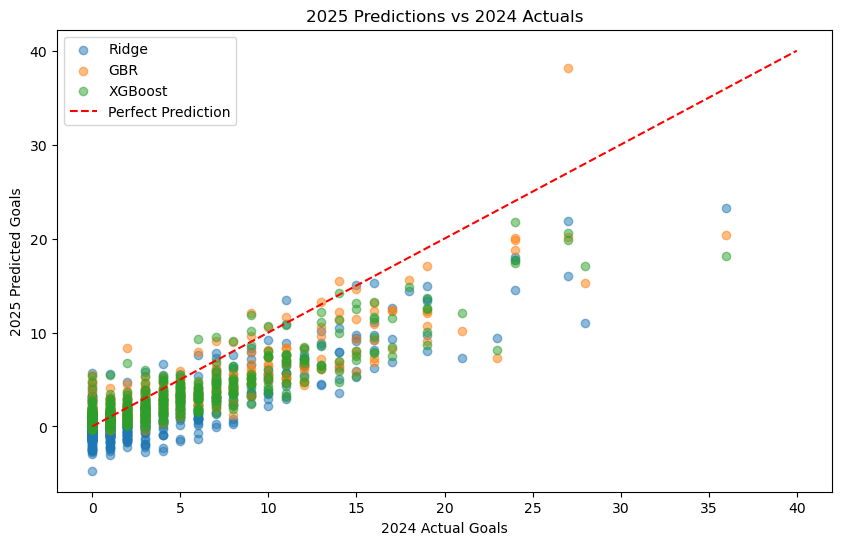

In [57]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt

# Load your data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# --- Feature Preprocessing ---
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt'
]
data_full.drop(columns=drop_features, inplace=True)

# --- Create Lagged Target ---
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# --- Feature Engineering ---
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
# New features
data_full['Minutes_trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)  # Role growth
data_full['Team_Gls_trend'] = data_full.groupby('team')['Team Success_onG'].pct_change().fillna(0)  # Team scoring trend
data_full['Recent_Form'] = data_full.groupby('player')['Performance_Gls'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)  # Last 2 seasons avg
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Goal_Rate'] = data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# --- Define Features ---
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=exclude_columns)

# --- Training and Testing Across Seasons ---
models = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=5, n_estimators=200, learning_rate=0.05)),
    'XGBoost': make_pipeline(StandardScaler(),xgb.XGBRegressor(objective='reg:squarederror', n_estimators=200, max_depth=6, learning_rate=0.05, subsample=0.8, scale_pos_weight=2))
}
results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weight recent seasons by repeating them in training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,  # Double weight
    data_full[data_full['season'] == 2023] * 3   # Triple weight
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# --- Train and Evaluate ---
for name, model in models.items():
    model.fit(X_train, y_train)
    # Test predictions
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# --- Predict 2025 Goals ---
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = model.predict(X_2024)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# --- Results ---
print("\n2025 Predictions vs 2024 Actuals:")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025']]
print(results_2025.head(20))

# --- Feature Importance (XGBoost) ---
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# --- Plot Predictions vs Actuals ---
plt.figure(figsize=(10, 6))
for name in models:
    plt.scatter(results_2025['Performance_Gls'], results_2025[f'predicted_goals_{name.lower()}_2025'], label=name, alpha=0.5)
plt.plot([0, 40], [0, 40], 'r--', label='Perfect Prediction')
plt.xlabel('2024 Actual Goals')
plt.ylabel('2025 Predicted Goals')
plt.title('2025 Predictions vs 2024 Actuals')
plt.legend()
plt.show()

In [58]:
results_2025.sort_values(by ="Performance_Gls" ,ascending = False).head(30)

,player,team,Performance_Gls,predicted_goals_ridge_2025,predicted_goals_gbr_2025,predicted_goals_xgboost_2025
3183,Harry Kane,Bayern Munich,36.000,23.238,20.427,18.133
3279,Serhou Guirassy,Stuttgart,28.000,10.987,15.324,17.123
3146,Kylian Mbappé,Paris S-G,27.000,16.059,20.181,19.848
2828,Erling Haaland,Manchester City,27.000,21.827,38.134,20.546
2958,Artem Dovbyk,Girona,24.000,14.480,18.825,21.720
3352,Lautaro Martínez,Inter,24.000,17.674,19.831,17.680
3274,Loïs Openda,RB Leipzig,24.000,18.058,20.062,17.424
3029,Alexander Sørloth,Villarreal,23.000,9.412,7.235,8.095
2842,Alexander Isak,Newcastle Utd,21.000,7.247,10.126,12.130
3072,Jonathan David,Lille,19.000,13.535,12.251,12.603


Ridge - MAE on 2024: 2.05, MSE: 11.26, R²: 0.50
GBR - MAE on 2024: 2.35, MSE: 14.22, R²: 0.37
XGBoost - MAE on 2024: 2.27, MSE: 13.75, R²: 0.39

2025 Predictions vs 2024 Actuals:
                      player         team  Performance_Gls  \
2735             Bukayo Saka      Arsenal           16.000   
2736           Eddie Nketiah      Arsenal            5.000   
2737           Ethan Nwaneri      Arsenal            0.000   
2738            Fabio Vieira      Arsenal            1.000   
2739           Gabriel Jesus      Arsenal            4.000   
2740      Gabriel Martinelli      Arsenal            6.000   
2741             Kai Havertz      Arsenal           13.000   
2742            Reiss Nelson      Arsenal            0.000   
2743         Bertrand Traoré  Aston Villa            0.000   
2744  Jaden Philogene Bidace  Aston Villa            0.000   
2745             John McGinn  Aston Villa            6.000   
2746             Leon Bailey  Aston Villa           10.000   
2747           

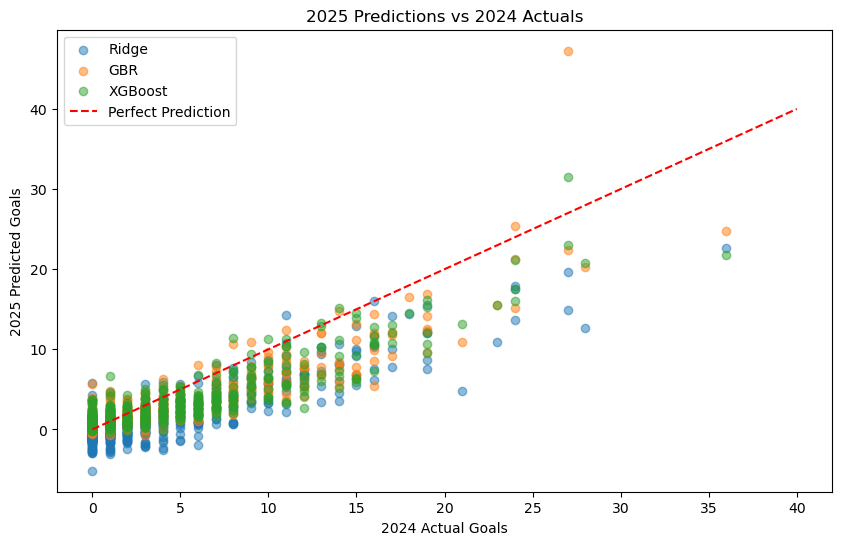

In [65]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt

# Load your data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# --- Feature Preprocessing ---
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt'
]
data_full.drop(columns=drop_features, inplace=True)

# --- Create Lagged Target ---
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# --- Feature Engineering ---
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
# New features
data_full['Minutes_trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)  # Role growth
data_full['Team_Gls_trend'] = data_full.groupby('team')['Team Success_onG'].pct_change().fillna(0)  # Team scoring trend
data_full['Last_Season_Gls'] = data_full['Performance_Gls']  
# Last 2 seasons avg
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Goal_Rate'] = data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# --- Define Features ---
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=exclude_columns)

# --- Training and Testing Across Seasons ---
models = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=5, n_estimators=200, learning_rate=0.05)),
    'XGBoost': make_pipeline(StandardScaler(),xgb.XGBRegressor(objective='reg:squarederror', n_estimators=200, max_depth=6, learning_rate=0.05, subsample=0.8, scale_pos_weight=3))
}
results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weight recent seasons by repeating them in training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,  # Double weight
    data_full[data_full['season'] == 2023] * 3   # Triple weight
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# --- Train and Evaluate ---
for name, model in models.items():
    model.fit(X_train, y_train)
    # Test predictions
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# --- Predict 2025 Goals ---
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = model.predict(X_2024)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# --- Results ---
print("\n2025 Predictions vs 2024 Actuals:")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025']]
print(results_2025.head(20))

# --- Feature Importance (XGBoost) ---
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# --- Plot Predictions vs Actuals ---
plt.figure(figsize=(10, 6))
for name in models:
    plt.scatter(results_2025['Performance_Gls'], results_2025[f'predicted_goals_{name.lower()}_2025'], label=name, alpha=0.5)
plt.plot([0, 40], [0, 40], 'r--', label='Perfect Prediction')
plt.xlabel('2024 Actual Goals')
plt.ylabel('2025 Predicted Goals')
plt.title('2025 Predictions vs 2024 Actuals')
plt.legend()
plt.show()

In [66]:
results_2025.sort_values(by ="Performance_Gls" ,ascending = False).head(40)

,player,team,Performance_Gls,predicted_goals_ridge_2025,predicted_goals_gbr_2025,predicted_goals_xgboost_2025
3183,Harry Kane,Bayern Munich,36.000,22.623,24.796,21.716
3279,Serhou Guirassy,Stuttgart,28.000,12.678,20.244,20.811
3146,Kylian Mbappé,Paris S-G,27.000,14.873,22.445,23.016
2828,Erling Haaland,Manchester City,27.000,19.659,47.267,31.455
2958,Artem Dovbyk,Girona,24.000,13.700,25.387,17.515
3352,Lautaro Martínez,Inter,24.000,17.557,15.106,16.083
3274,Loïs Openda,RB Leipzig,24.000,17.847,21.261,21.197
3029,Alexander Sørloth,Villarreal,23.000,10.937,15.512,15.475
2842,Alexander Isak,Newcastle Utd,21.000,4.757,10.904,13.135
3072,Jonathan David,Lille,19.000,12.053,12.285,11.993


Ridge - MAE on 2024: 2.16, MSE: 16.85, R²: 0.25
GBR - MAE on 2024: 2.34, MSE: 13.54, R²: 0.40
XGBoost - MAE on 2024: 2.32, MSE: 13.83, R²: 0.38

2025 Predictions vs 2024 Actuals:
                      player         team  Performance_Gls  \
2735             Bukayo Saka      Arsenal           16.000   
2736           Eddie Nketiah      Arsenal            5.000   
2737           Ethan Nwaneri      Arsenal            0.000   
2738            Fabio Vieira      Arsenal            1.000   
2739           Gabriel Jesus      Arsenal            4.000   
2740      Gabriel Martinelli      Arsenal            6.000   
2741             Kai Havertz      Arsenal           13.000   
2742            Reiss Nelson      Arsenal            0.000   
2743         Bertrand Traoré  Aston Villa            0.000   
2744  Jaden Philogene Bidace  Aston Villa            0.000   
2745             John McGinn  Aston Villa            6.000   
2746             Leon Bailey  Aston Villa           10.000   
2747           

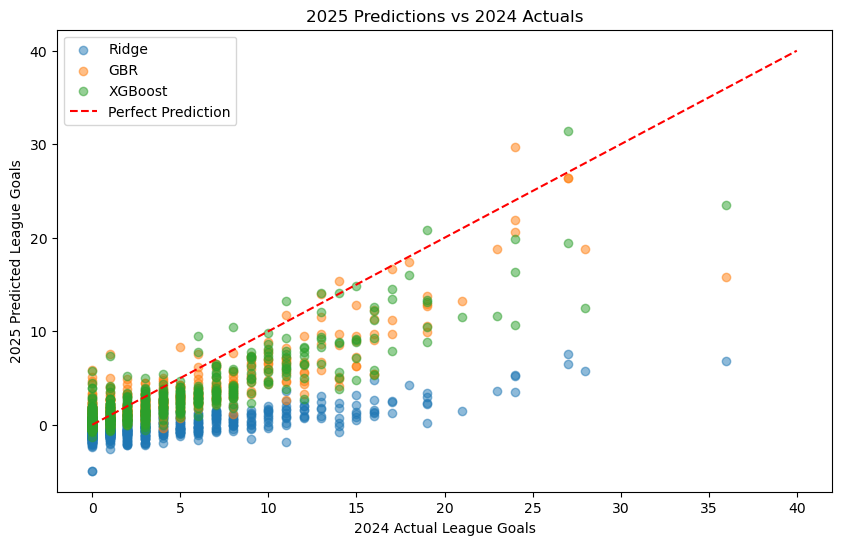

In [71]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt

# Load your data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# --- Feature Preprocessing ---
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt'
]
data_full.drop(columns=drop_features, inplace=True)

# --- Create Lagged Target ---
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# --- Feature Engineering ---
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
data_full['Minutes_trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)
data_full['Team_Gls_trend'] = data_full.groupby('team')['Team Success_onG'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Goal_Rate_2024'] = data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)
data_full['Adjusted_Goal_Rate'] = data_full['Goal_Rate_2024'] * (1 + 0.2 * (data_full['Performance_Gls'] > 20).astype(int))
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# --- Define Features ---
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', ]
X_features = data_full.drop(columns=exclude_columns)

# --- Training and Testing ---
models = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=5, n_estimators=200, learning_rate=0.05)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1, scale_pos_weight=1.2))
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weight recent seasons more heavily
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 3,
    data_full[data_full['season'] == 2024] * 5  # Heavily weight 2024
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# --- Train and Evaluate ---
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# --- Predict 2025 Goals ---
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = model.predict(X_2024)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# --- Results ---
print("\n2025 Predictions vs 2024 Actuals:")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025']]
print(results_2025.head(20))

# --- Feature Importance (XGBoost) ---
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# --- Validation with Partial 2024/25 Data ---
actual_2025 = {
    'Harry Kane': 24,        # Bundesliga estimate
    'Serhou Guirassy': 16,   # Bundesliga (Dortmund)
    'Kylian Mbappé': 17,     # La Liga (Real Madrid)
    'Erling Haaland': 19,    # Premier League
    'Alexander Isak': 16,    # Premier League
    'Mohamed Salah': 25      # Premier League (confirmed)
}
pred_df = results_2025.set_index('player')
mae_2025 = {name: mean_absolute_error([actual_2025[p] for p in actual_2025], pred_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']) for name in models}
print("\nMAE on 2024/25 partial data (as of March 07, 2025):", mae_2025)

# --- Plot Predictions vs Actuals ---
plt.figure(figsize=(10, 6))
for name in models:
    plt.scatter(results_2025['Performance_Gls'], results_2025[f'predicted_goals_{name.lower()}_2025'], label=name, alpha=0.5)
plt.plot([0, 40], [0, 40], 'r--', label='Perfect Prediction')
plt.xlabel('2024 Actual League Goals')
plt.ylabel('2025 Predicted League Goals')
plt.title('2025 Predictions vs 2024 Actuals')
plt.legend()
plt.show()

In [73]:
results_2025.sort_values(by ="Performance_Gls" ,ascending = False).head(40)

,player,team,Performance_Gls,predicted_goals_ridge_2025,predicted_goals_gbr_2025,predicted_goals_xgboost_2025
3183,Harry Kane,Bayern Munich,36.000,6.822,15.839,23.466
3279,Serhou Guirassy,Stuttgart,28.000,5.763,18.828,12.508
3146,Kylian Mbappé,Paris S-G,27.000,7.564,26.363,19.404
2828,Erling Haaland,Manchester City,27.000,6.535,26.380,31.430
2958,Artem Dovbyk,Girona,24.000,3.527,29.739,10.620
3352,Lautaro Martínez,Inter,24.000,5.177,20.651,16.317
3274,Loïs Openda,RB Leipzig,24.000,5.309,21.868,19.892
3029,Alexander Sørloth,Villarreal,23.000,3.586,18.775,11.648
2842,Alexander Isak,Newcastle Utd,21.000,1.448,13.203,11.559
3072,Jonathan David,Lille,19.000,2.980,12.693,13.119


Ridge - MAE on 2024: 2.21, MSE: 17.84, R²: 0.20
GBR - MAE on 2024: 2.37, MSE: 13.24, R²: 0.41
XGBoost - MAE on 2024: 2.40, MSE: 14.15, R²: 0.37

2025 Predictions vs 2024 Actuals:
                      player         team  Performance_Gls  \
2735             Bukayo Saka      Arsenal           16.000   
2736           Eddie Nketiah      Arsenal            5.000   
2737           Ethan Nwaneri      Arsenal            0.000   
2738            Fabio Vieira      Arsenal            1.000   
2739           Gabriel Jesus      Arsenal            4.000   
2740      Gabriel Martinelli      Arsenal            6.000   
2741             Kai Havertz      Arsenal           13.000   
2742            Reiss Nelson      Arsenal            0.000   
2743         Bertrand Traoré  Aston Villa            0.000   
2744  Jaden Philogene Bidace  Aston Villa            0.000   
2745             John McGinn  Aston Villa            6.000   
2746             Leon Bailey  Aston Villa           10.000   
2747           

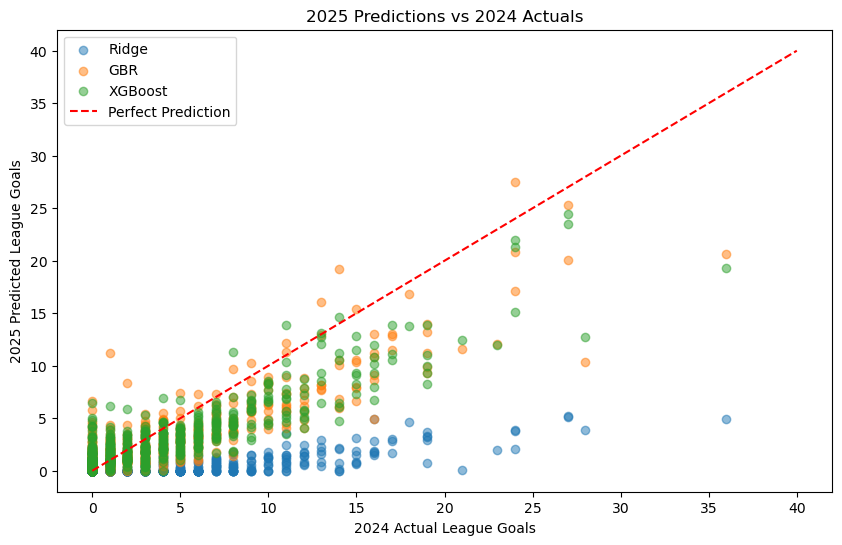

In [75]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# Feature Preprocessing
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt'
]
data_full.drop(columns=drop_features, inplace=True)

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
data_full['Minutes_trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)
data_full['Team_Gls_trend'] = data_full.groupby('team')['Team Success_onG'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Goal_Rate_2024'] = data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)
data_full['Adjusted_Goal_Rate'] = data_full['Goal_Rate_2024'] * (1 + 0.4 * (data_full['Performance_Gls'] > 15).astype(int))
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=exclude_columns)

# Models
models = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=0.1)),
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=5, n_estimators=200, learning_rate=0.05)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1))
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 3,
    data_full[data_full['season'] == 2024] * 5
]).dropna(subset=['Performance_Gls_next'])
top_scorers = data_full[data_full['season'] == 2024]['Performance_Gls'] > 20
train_data_weighted = pd.concat([
    train_data_weighted,
    data_full[(data_full['season'] == 2024) & top_scorers] * 2
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)  # Ensure non-negative
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Results
print("\n2025 Predictions vs 2024 Actuals:")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025']]
print(results_2025.head(20))

# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation with Partial 2024/25 Data
actual_2025 = {'Harry Kane': 24, 'Serhou Guirassy': 16, 'Kylian Mbappé': 17, 'Erling Haaland': 19, 'Alexander Isak': 16, 'Mohamed Salah': 25}
pred_df = results_2025.set_index('player')
mae_2025 = {name: mean_absolute_error([actual_2025[p] for p in actual_2025], pred_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']) for name in models}
print("\nMAE on 2024/25 partial data (as of March 07, 2025):", mae_2025)

# Plot
plt.figure(figsize=(10, 6))
for name in models:
    plt.scatter(results_2025['Performance_Gls'], results_2025[f'predicted_goals_{name.lower()}_2025'], label=name, alpha=0.5)
plt.plot([0, 40], [0, 40], 'r--', label='Perfect Prediction')
plt.xlabel('2024 Actual League Goals')
plt.ylabel('2025 Predicted League Goals')
plt.title('2025 Predictions vs 2024 Actuals')
plt.legend()
plt.show()

In [77]:
results_2025.sort_values(by ="Performance_Gls" ,ascending = False).head(40)

,player,team,Performance_Gls,predicted_goals_ridge_2025,predicted_goals_gbr_2025,predicted_goals_xgboost_2025
3183,Harry Kane,Bayern Munich,36.000,4.885,20.643,19.332
3279,Serhou Guirassy,Stuttgart,28.000,3.853,10.383,12.725
3146,Kylian Mbappé,Paris S-G,27.000,5.218,20.073,23.464
2828,Erling Haaland,Manchester City,27.000,5.155,25.304,24.445
2958,Artem Dovbyk,Girona,24.000,2.025,27.504,21.960
3352,Lautaro Martínez,Inter,24.000,3.859,17.123,15.151
3274,Loïs Openda,RB Leipzig,24.000,3.791,20.791,21.275
3029,Alexander Sørloth,Villarreal,23.000,1.969,12.053,11.978
2842,Alexander Isak,Newcastle Utd,21.000,0.045,11.577,12.469
3072,Jonathan David,Lille,19.000,3.273,9.838,9.315


Ridge - MAE on 2024: 2.18, MSE: 15.13, R²: 0.33
GBR - MAE on 2024: 2.34, MSE: 13.47, R²: 0.40
XGBoost - MAE on 2024: 2.27, MSE: 12.72, R²: 0.43

2025 Predictions vs 2024 Actuals (Top 40):
                         player             team  Performance_Gls  \
3183                 Harry Kane    Bayern Munich           36.000   
3279            Serhou Guirassy        Stuttgart           28.000   
3146              Kylian Mbappé        Paris S-G           27.000   
2828             Erling Haaland  Manchester City           27.000   
2958               Artem Dovbyk           Girona           24.000   
3352           Lautaro Martínez            Inter           24.000   
3274                Loïs Openda       RB Leipzig           24.000   
3029          Alexander Sørloth       Villarreal           23.000   
2842             Alexander Isak    Newcastle Utd           21.000   
3072             Jonathan David            Lille           19.000   
2748              Ollie Watkins      Aston Villa     

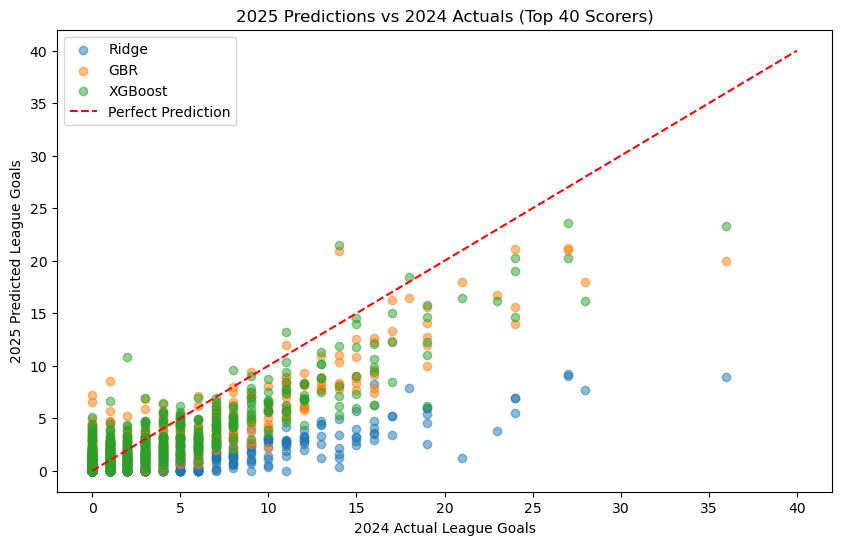

In [79]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# Feature Preprocessing
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt'
]
data_full.drop(columns=drop_features, inplace=True)

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
data_full['Minutes_trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)
data_full['Team_Gls_trend'] = data_full.groupby('team')['Team Success_onG'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Goal_Rate_2024'] = data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)
data_full['Adjusted_Goal_Rate'] = data_full['Goal_Rate_2024'] * (1 + 0.2 * (data_full['Performance_Gls'] > 15).astype(int))  # Reduced boost
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=exclude_columns)

# Models
models = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=0.5)),  # Adjusted alpha
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=4, n_estimators=100, learning_rate=0.1)),  # Simplified
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1))  # First-run params
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weighted Training (less aggressive)
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 3  # Reduced from 5
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)  # Ensure non-negative
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Results (Top 40 sorted by 2024 goals)
print("\n2025 Predictions vs 2024 Actuals (Top 40):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_ridge_2025', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025']]
print(results_2025.sort_values('Performance_Gls', ascending=False).head(40))

# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation with Partial 2024/25 Data (excluding Salah)
actual_2025 = {'Harry Kane': 24, 'Serhou Guirassy': 16, 'Kylian Mbappé': 17, 'Erling Haaland': 19, 'Alexander Isak': 16}
pred_df = results_2025.set_index('player')
mae_2025 = {name: mean_absolute_error([actual_2025[p] for p in actual_2025], pred_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']) for name in models}
print("\nMAE on 2024/25 partial data (as of March 07, 2025, excluding Salah):", mae_2025)

# Plot
plt.figure(figsize=(10, 6))
for name in models:
    plt.scatter(results_2025['Performance_Gls'], results_2025[f'predicted_goals_{name.lower()}_2025'], label=name, alpha=0.5)
plt.plot([0, 40], [0, 40], 'r--', label='Perfect Prediction')
plt.xlabel('2024 Actual League Goals')
plt.ylabel('2025 Predicted League Goals')
plt.title('2025 Predictions vs 2024 Actuals (Top 40 Scorers)')
plt.legend()
plt.show()

In [81]:
results_2025.sort_values(by ="Performance_Gls" ,ascending = False).head(40)

,player,team,Performance_Gls,predicted_goals_ridge_2025,predicted_goals_gbr_2025,predicted_goals_xgboost_2025
3183,Harry Kane,Bayern Munich,36.000,8.944,19.969,23.350
3279,Serhou Guirassy,Stuttgart,28.000,7.700,18.001,16.179
3146,Kylian Mbappé,Paris S-G,27.000,9.014,21.030,20.236
2828,Erling Haaland,Manchester City,27.000,9.252,21.212,23.582
2958,Artem Dovbyk,Girona,24.000,5.505,15.595,19.017
3352,Lautaro Martínez,Inter,24.000,6.951,13.989,14.641
3274,Loïs Openda,RB Leipzig,24.000,6.894,21.117,20.226
3029,Alexander Sørloth,Villarreal,23.000,3.756,16.758,16.142
2842,Alexander Isak,Newcastle Utd,21.000,1.248,18.007,16.467
3072,Jonathan David,Lille,19.000,5.449,12.016,11.068


GBR - MAE on 2024: 2.32, MSE: 13.24, R²: 0.41
XGBoost - MAE on 2024: 2.27, MSE: 12.94, R²: 0.42

2025 Predictions vs 2024 Actuals (Top 40):
                         player             team  Performance_Gls  \
3183                 Harry Kane    Bayern Munich           36.000   
3279            Serhou Guirassy        Stuttgart           28.000   
3146              Kylian Mbappé        Paris S-G           27.000   
2828             Erling Haaland  Manchester City           27.000   
2958               Artem Dovbyk           Girona           24.000   
3352           Lautaro Martínez            Inter           24.000   
3274                Loïs Openda       RB Leipzig           24.000   
3029          Alexander Sørloth       Villarreal           23.000   
2842             Alexander Isak    Newcastle Utd           21.000   
3072             Jonathan David            Lille           19.000   
2748              Ollie Watkins      Aston Villa           19.000   
2919         Robert Lewandowski 

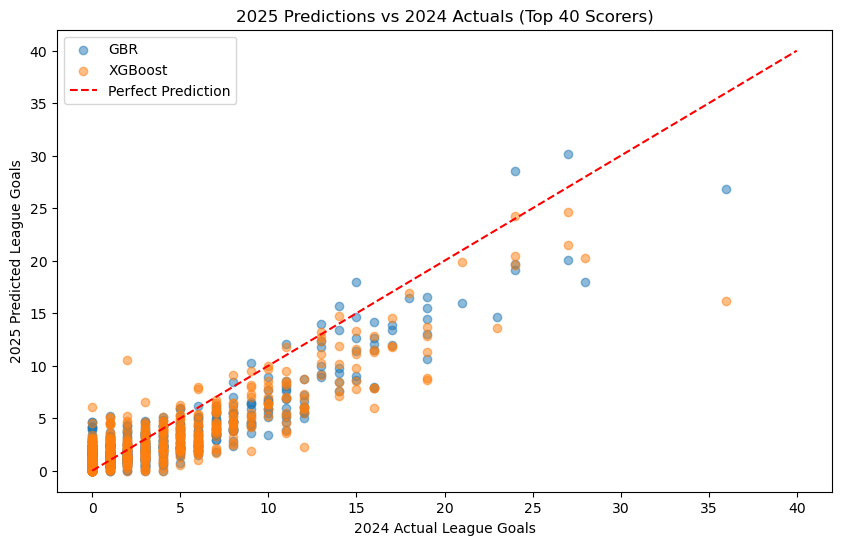

In [83]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# Feature Preprocessing
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Short_Cmp%', 'Medium_Cmp%'  # Drop noisy features
]
data_full.drop(columns=drop_features, inplace=True)

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
data_full['Minutes_trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)
data_full['Team_Gls_trend'] = data_full.groupby('team')['Team Success_onG'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Goal_Rate_2024'] = data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)
data_full['Adjusted_Goal_Rate'] = data_full['Goal_Rate_2024'] * (1 + 0.2 * (data_full['Performance_Gls'] > 15).astype(int))
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=exclude_columns)

# Models
models = {
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=3, n_estimators=150, learning_rate=0.08)),  # Tuned
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1))
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4  # Slight increase
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Results (Top 40)
print("\n2025 Predictions vs 2024 Actuals (Top 40):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025']]
print(results_2025.sort_values('Performance_Gls', ascending=False).head(40))

# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation (excluding Salah)
actual_2025 = {'Harry Kane': 24, 'Serhou Guirassy': 16, 'Kylian Mbappé': 17, 'Erling Haaland': 19, 'Alexander Isak': 16}
pred_df = results_2025.set_index('player')
mae_2025 = {name: mean_absolute_error([actual_2025[p] for p in actual_2025], pred_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']) for name in models}
print("\nMAE on 2024/25 partial data (as of March 07, 2025, excluding Salah):", mae_2025)

# Plot
plt.figure(figsize=(10, 6))
for name in models:
    plt.scatter(results_2025['Performance_Gls'], results_2025[f'predicted_goals_{name.lower()}_2025'], label=name, alpha=0.5)
plt.plot([0, 40], [0, 40], 'r--', label='Perfect Prediction')
plt.xlabel('2024 Actual League Goals')
plt.ylabel('2025 Predicted League Goals')
plt.title('2025 Predictions vs 2024 Actuals (Top 40 Scorers)')
plt.legend()
plt.show()

In [85]:
results_2025.sort_values('Performance_Gls', ascending=False).head(40)

,player,team,Performance_Gls,predicted_goals_gbr_2025,predicted_goals_xgboost_2025
3183,Harry Kane,Bayern Munich,36.000,26.858,16.182
3279,Serhou Guirassy,Stuttgart,28.000,17.985,20.257
3146,Kylian Mbappé,Paris S-G,27.000,20.029,21.540
2828,Erling Haaland,Manchester City,27.000,30.148,24.603
2958,Artem Dovbyk,Girona,24.000,28.546,19.627
3352,Lautaro Martínez,Inter,24.000,19.093,24.223
3274,Loïs Openda,RB Leipzig,24.000,19.722,20.465
3029,Alexander Sørloth,Villarreal,23.000,14.634,13.628
2842,Alexander Isak,Newcastle Utd,21.000,15.966,19.902
3072,Jonathan David,Lille,19.000,12.983,8.619


In [87]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import matplotlib.pyplot as plt

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# Feature Preprocessing
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%'  # Drop noise
]
data_full.drop(columns=drop_features, inplace=True)

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
data_full['Minutes_trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)
data_full['Team_Gls_trend'] = data_full.groupby('team')['Team Success_onG'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Goal_Rate_2024'] = data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)
data_full['Adjusted_Goal_Rate'] = data_full['Goal_Rate_2024'] * (1 + 0.2 * (data_full['Performance_Gls'] > 15).astype(int))
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=exclude_columns)

# Models
models = {
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=3, n_estimators=150, learning_rate=0.08)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1)),
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42))
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Ensemble Prediction
ensemble_pred = 0.6 * models['XGBoost'].predict(X_2024) + 0.4 * models['GBR'].predict(X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Results (Top 40)
print("\n2025 Predictions vs 2024 Actuals (Top 40):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_rf_2025', 'predicted_goals_ensemble_2025']]
print(results_2025.sort_values('Performance_Gls', ascending=False).head(40))

# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation (excluding Salah)
actual_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
pred_df = results_2025.set_index('player')
mae_2025 = {name: mean_absolute_error([actual_2025[p] for p in actual_2025], pred_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']) for name in models}
mae_2025['Ensemble'] = mean_absolute_error([actual_2025[p] for p in actual_2025], pred_df.loc[list(actual_2025), 'predicted_goals_ensemble_2025'])
print("\nMAE on 2024/25 partial data (as of March 07, 2025, excluding Salah):", mae_2025)


GBR - MAE on 2024: 2.34, MSE: 13.14, R²: 0.41
XGBoost - MAE on 2024: 2.31, MSE: 13.17, R²: 0.41
RF - MAE on 2024: 2.43, MSE: 14.05, R²: 0.37

2025 Predictions vs 2024 Actuals (Top 40):
                         player             team  Performance_Gls  \
3183                 Harry Kane    Bayern Munich           36.000   
3279            Serhou Guirassy        Stuttgart           28.000   
3146              Kylian Mbappé        Paris S-G           27.000   
2828             Erling Haaland  Manchester City           27.000   
2958               Artem Dovbyk           Girona           24.000   
3352           Lautaro Martínez            Inter           24.000   
3274                Loïs Openda       RB Leipzig           24.000   
3029          Alexander Sørloth       Villarreal           23.000   
2842             Alexander Isak    Newcastle Utd           21.000   
3072             Jonathan David            Lille           19.000   
2748              Ollie Watkins      Aston Villa        

In [89]:
results_2025.sort_values('Performance_Gls', ascending=False).head(40)

,player,team,Performance_Gls,predicted_goals_gbr_2025,predicted_goals_xgboost_2025,predicted_goals_rf_2025,predicted_goals_ensemble_2025
3183,Harry Kane,Bayern Munich,36.000,26.686,22.390,19.615,24.108
3279,Serhou Guirassy,Stuttgart,28.000,16.500,14.296,13.595,15.177
3146,Kylian Mbappé,Paris S-G,27.000,18.564,18.986,15.896,18.817
2828,Erling Haaland,Manchester City,27.000,23.304,18.796,17.120,20.599
2958,Artem Dovbyk,Girona,24.000,22.792,13.728,17.793,17.353
3352,Lautaro Martínez,Inter,24.000,21.286,19.644,15.363,20.301
3274,Loïs Openda,RB Leipzig,24.000,18.469,18.780,16.097,18.656
3029,Alexander Sørloth,Villarreal,23.000,15.071,12.895,13.973,13.765
2842,Alexander Isak,Newcastle Utd,21.000,15.030,14.441,11.874,14.677
3072,Jonathan David,Lille,19.000,12.378,10.016,11.848,10.961


In [91]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')

# Feature Preprocessing
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Short_Cmp%', 'Medium_Cmp%'  # Fixed drop
]
data_full.drop(columns=drop_features, inplace=True)

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
data_full['Minutes_trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)
data_full['Team_Gls_trend'] = data_full.groupby('team')['Team Success_onG'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Goal_Rate_2024'] = data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)
data_full['Adjusted_Goal_Rate'] = data_full['Goal_Rate_2024'] * (1 + 0.3 * (data_full['Performance_Gls'] > 20).astype(int))  # Boost for >20
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=exclude_columns)

# Models
models = {
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=3, n_estimators=150, learning_rate=0.08)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1)),
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42))
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Ensemble Prediction
ensemble_pred = 0.7 * models['XGBoost'].predict(X_2024) + 0.3 * models['GBR'].predict(X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Results (Top 40)
print("\n2025 Predictions vs 2024 Actuals (Top 40):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_rf_2025', 'predicted_goals_ensemble_2025']]


# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation (excluding Salah)
actual_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
pred_df = results_2025.set_index('player')
mae_2025 = {name: mean_absolute_error([actual_2025[p] for p in actual_2025], pred_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']) for name in models}
mae_2025['Ensemble'] = mean_absolute_error([actual_2025[p] for p in actual_2025], pred_df.loc[list(actual_2025), 'predicted_goals_ensemble_2025'])
print("\nMAE on 2024/25 partial data (as of March 07, 2025, excluding Salah):", mae_2025)
results_2025.sort_values('Performance_Gls', ascending=False).head(40)

GBR - MAE on 2024: 2.34, MSE: 13.28, R²: 0.41
XGBoost - MAE on 2024: 2.27, MSE: 12.98, R²: 0.42
RF - MAE on 2024: 2.44, MSE: 14.12, R²: 0.37

2025 Predictions vs 2024 Actuals (Top 40):

Top Feature Importances from XGBoost:
xG_Overperformance: 0.0855
Standard_SoT: 0.0651
Total_Cmp%: 0.0442
Team Success_onG: 0.0312
Touches_Att Pen: 0.0162
Standard_Dist: 0.0155
Recent_xG_Form: 0.0151
Corner Kicks_In: 0.0148
Expected_npxG: 0.0136
GCA Types_Def: 0.0126

MAE on 2024/25 partial data (as of March 07, 2025, excluding Salah): {'GBR': 4.246689411573987, 'XGBoost': 3.361540603637695, 'RF': 3.4310330160162095, 'Ensemble': 3.3771411690443296}


,player,team,Performance_Gls,predicted_goals_gbr_2025,predicted_goals_xgboost_2025,predicted_goals_rf_2025,predicted_goals_ensemble_2025
3183,Harry Kane,Bayern Munich,36.000,23.083,16.393,17.090,18.400
3279,Serhou Guirassy,Stuttgart,28.000,18.782,15.804,13.068,16.697
3146,Kylian Mbappé,Paris S-G,27.000,20.043,22.820,14.117,21.987
2828,Erling Haaland,Manchester City,27.000,27.827,24.314,16.939,25.368
2958,Artem Dovbyk,Girona,24.000,23.316,16.677,17.437,18.668
3352,Lautaro Martínez,Inter,24.000,21.055,28.300,14.795,26.127
3274,Loïs Openda,RB Leipzig,24.000,19.076,18.963,14.632,18.997
3029,Alexander Sørloth,Villarreal,23.000,14.386,11.991,12.111,12.709
2842,Alexander Isak,Newcastle Utd,21.000,15.501,18.738,12.631,17.767
3072,Jonathan David,Lille,19.000,12.098,9.567,11.487,10.326


<h1> Good Model</h1>

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
from sklearn.pipeline import make_pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')  # 2025 partial data for validation only

# Filter 2025 data for forwards from 2024 top 40
top_40_2024_players = data_full[data_full['season'] == 2024].sort_values('Performance_Gls', ascending=False).head(40)['player'].unique()
data_2025 = data_2025[data_2025['player'].isin(top_40_2024_players)]
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]  # Filter for forwards
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Feature Preprocessing (only on training data)
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%', 'Short_Cmp%', 'Medium_Cmp%'  # Fixed drop
]
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
data_full['Minutes_trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)
data_full['Team_Gls_trend'] = data_full.groupby('team')['Team Success_onG'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Goal_Rate_2024'] = data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)
data_full['Adjusted_Goal_Rate'] = data_full['Goal_Rate_2024'] * (1 + 0.3 * (data_full['Performance_Gls'] > 20).astype(int))
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=3, n_estimators=150, learning_rate=0.08)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5, learning_rate=0.1)),
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42))
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weighted Training (2020–2024 only)
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024 (historical check)
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# Predict 2025 Goals (full season from 2024 data)
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Ensemble Prediction (0.8 XGBoost + 0.2 GBR)
ensemble_pred = 0.8 * models['XGBoost'].predict(X_2024) + 0.2 * models['GBR'].predict(X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Results (Top 40 from 2024)
print("\n2025 Predictions vs 2024 Actuals (Top 40):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_rf_2025', 'predicted_goals_ensemble_2025']]
top_40_2024 = results_2025.sort_values('Performance_Gls', ascending=False).head(40)
print(top_40_2024)

# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation with 2025 Partial Data (all forwards from 2024 top 40)
actual_2025_full = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = top_40_2024.set_index('player')
players_to_validate = [p for p in actual_2025_full.keys() if p in pred_2025_df.index]
mae_2025_full = {
    name: mean_absolute_error(
        [actual_2025_full[p] for p in players_to_validate],
        pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_full['Ensemble'] = mean_absolute_error(
    [actual_2025_full[p] for p in players_to_validate],
    pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (all forwards from 2024 top 40, as of March 07, 2025):", mae_2025_full)

# Original 5-player validation (for comparison)
actual_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
mae_2025_subset = {
    name: mean_absolute_error(
        [actual_2025[p] for p in actual_2025],
        pred_2025_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_subset['Ensemble'] = mean_absolute_error(
    [actual_2025[p] for p in actual_2025],
    pred_2025_df.loc[list(actual_2025), 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (original 5 players, as of March 07, 2025):", mae_2025_subset)

GBR - MAE on 2024: 2.34, MSE: 12.97, R²: 0.42
XGBoost - MAE on 2024: 2.26, MSE: 12.83, R²: 0.43
RF - MAE on 2024: 2.44, MSE: 14.19, R²: 0.37

2025 Predictions vs 2024 Actuals (Top 40):
                         player             team  Performance_Gls  \
3183                 Harry Kane    Bayern Munich             36.0   
3279            Serhou Guirassy        Stuttgart             28.0   
3146              Kylian Mbappé        Paris S-G             27.0   
2828             Erling Haaland  Manchester City             27.0   
2958               Artem Dovbyk           Girona             24.0   
3352           Lautaro Martínez            Inter             24.0   
3274                Loïs Openda       RB Leipzig             24.0   
3029          Alexander Sørloth       Villarreal             23.0   
2842             Alexander Isak    Newcastle Utd             21.0   
3072             Jonathan David            Lille             19.0   
2748              Ollie Watkins      Aston Villa        

In [12]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
from sklearn.pipeline import make_pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards from 2024 top 40
top_40_2024_players = data_full[data_full['season'] == 2024].sort_values('Performance_Gls', ascending=False).head(40)['player'].unique()
data_2025 = data_2025[data_2025['player'].isin(top_40_2024_players)]
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Feature Preprocessing
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%', 'Short_Cmp%', 'Medium_Cmp%',
    'Challenges_Lost'  # Drop noise
]
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Team_Goal_Contribution'] = data_full['Performance_Gls'] / (data_full['Team Success_onG'] + 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / (data_full['Expected_npxG'] + 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['xG_trend'] = data_full.groupby('player')['Expected_xG'].pct_change().fillna(0)
data_full['Minutes_trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)
data_full['Team_Gls_trend'] = data_full.groupby('team')['Team Success_onG'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Goal_Rate_2024'] = data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)
data_full['Adjusted_Goal_Rate'] = data_full['Goal_Rate_2024'] * (1 + 0.4 * (data_full['Performance_Gls'] > 20).astype(int))  # Boost to 0.4
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=3, n_estimators=150, learning_rate=0.08)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),  # Tuned
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42))
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Ensemble Prediction
ensemble_pred = 0.8 * models['XGBoost'].predict(X_2024) + 0.2 * models['GBR'].predict(X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Results (Top 40)
print("\n2025 Predictions vs 2024 Actuals (Top 40):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_rf_2025', 'predicted_goals_ensemble_2025']]
top_40_2024 = results_2025.sort_values('Performance_Gls', ascending=False).head(40)
print(top_40_2024)

# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nTop Feature Importances from XGBoost:")
for i in sorted_indices_xgb[:10]:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation with 2025 Partial Data (all forwards from 2024 top 40)
actual_2025_full = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = top_40_2024.set_index('player')
players_to_validate = [p for p in actual_2025_full.keys() if p in pred_2025_df.index]
mae_2025_full = {
    name: mean_absolute_error(
        [actual_2025_full[p] for p in players_to_validate],
        pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_full['Ensemble'] = mean_absolute_error(
    [actual_2025_full[p] for p in players_to_validate],
    pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (all forwards from 2024 top 40, as of March 07, 2025):", mae_2025_full)

# Original 5-player validation
actual_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
mae_2025_subset = {
    name: mean_absolute_error(
        [actual_2025[p] for p in actual_2025],
        pred_2025_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_subset['Ensemble'] = mean_absolute_error(
    [actual_2025[p] for p in actual_2025],
    pred_2025_df.loc[list(actual_2025), 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (original 5 players, as of March 07, 2025):", mae_2025_subset)

GBR - MAE on 2024: 2.35, MSE: 13.13, R²: 0.41
XGBoost - MAE on 2024: 2.27, MSE: 12.65, R²: 0.44
RF - MAE on 2024: 2.44, MSE: 14.09, R²: 0.37

2025 Predictions vs 2024 Actuals (Top 40):
                         player             team  Performance_Gls  \
3183                 Harry Kane    Bayern Munich             36.0   
3279            Serhou Guirassy        Stuttgart             28.0   
3146              Kylian Mbappé        Paris S-G             27.0   
2828             Erling Haaland  Manchester City             27.0   
2958               Artem Dovbyk           Girona             24.0   
3352           Lautaro Martínez            Inter             24.0   
3274                Loïs Openda       RB Leipzig             24.0   
3029          Alexander Sørloth       Villarreal             23.0   
2842             Alexander Isak    Newcastle Utd             21.0   
3072             Jonathan David            Lille             19.0   
2748              Ollie Watkins      Aston Villa        

In [18]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
from sklearn.pipeline import make_pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards from 2024 top 40
top_40_2024_players = data_full[data_full['season'] == 2024].sort_values('Performance_Gls', ascending=False).head(40)['player'].unique()
data_2025 = data_2025[data_2025['player'].isin(top_40_2024_players)]
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Feature Preprocessing
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', '90s',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%', 'Short_Cmp%', 'Medium_Cmp%',
    'GCA Types_Sh', 'Team_Goal_Contribution', 'Touches_Att Pen', 'Team_Gls_trend', 'Minutes_trend', 'xG_trend',
    'Corner Kicks_In', 'Tackles_Def 3rd', 'Blocks_Blocks', 'Int', 'Touches_Def Pen', 'Medium_Cmp',
    'Unnamed: 0'  # Drop noise
]
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering (reduced set)
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_xG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_xG'].replace(0, 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / data_full['Expected_npxG'].replace(0, 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_xG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Adjusted_Goal_Rate'] = (data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)) * (1 + 0.4 * (data_full['Performance_Gls'] > 20).astype(int))
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'age', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=3, n_estimators=150, learning_rate=0.08)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42))
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Ensemble Prediction
ensemble_pred = 0.8 * models['XGBoost'].predict(X_2024) + 0.2 * models['GBR'].predict(X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Results (Top 40)
print("\n2025 Predictions vs 2024 Actuals (Top 40):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_rf_2025', 'predicted_goals_ensemble_2025']]
top_40_2024 = results_2025.sort_values('Performance_Gls', ascending=False).head(40)
print(top_40_2024)

# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nAll Feature Importances from XGBoost:")
for i in sorted_indices_xgb:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation with 2025 Partial Data (all forwards from 2024 top 40)
actual_2025_full = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = top_40_2024.set_index('player')
players_to_validate = [p for p in actual_2025_full.keys() if p in pred_2025_df.index]
mae_2025_full = {
    name: mean_absolute_error(
        [actual_2025_full[p] for p in players_to_validate],
        pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_full['Ensemble'] = mean_absolute_error(
    [actual_2025_full[p] for p in players_to_validate],
    pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (all forwards from 2024 top 40, as of March 07, 2025):", mae_2025_full)

# Original 5-player validation
actual_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
mae_2025_subset = {
    name: mean_absolute_error(
        [actual_2025[p] for p in actual_2025],
        pred_2025_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_subset['Ensemble'] = mean_absolute_error(
    [actual_2025[p] for p in actual_2025],
    pred_2025_df.loc[list(actual_2025), 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (original 5 players, as of March 07, 2025):", mae_2025_subset)

GBR - MAE on 2024: 2.39, MSE: 13.26, R²: 0.41
XGBoost - MAE on 2024: 2.31, MSE: 12.88, R²: 0.43
RF - MAE on 2024: 2.44, MSE: 14.12, R²: 0.37

2025 Predictions vs 2024 Actuals (Top 40):
                         player             team  Performance_Gls  \
3183                 Harry Kane    Bayern Munich             36.0   
3279            Serhou Guirassy        Stuttgart             28.0   
3146              Kylian Mbappé        Paris S-G             27.0   
2828             Erling Haaland  Manchester City             27.0   
2958               Artem Dovbyk           Girona             24.0   
3352           Lautaro Martínez            Inter             24.0   
3274                Loïs Openda       RB Leipzig             24.0   
3029          Alexander Sørloth       Villarreal             23.0   
2842             Alexander Isak    Newcastle Utd             21.0   
3072             Jonathan David            Lille             19.0   
2748              Ollie Watkins      Aston Villa        

In [22]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
from sklearn.pipeline import make_pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards from 2024 top 40
top_40_2024_players = data_full[data_full['season'] == 2024].sort_values('Performance_Gls', ascending=False).head(40)['player'].unique()
data_2025 = data_2025[data_2025['player'].isin(top_40_2024_players)]
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Feature Preprocessing
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%', 'Short_Cmp%', 'Medium_Cmp%',
    'GCA Types_Sh', 'Team_Goal_Contribution', 'Touches_Att Pen', 'Team_Gls_trend', 'Minutes_trend', 'xG_trend',
    'Corner Kicks_In', 'Tackles_Def 3rd', 'Blocks_Blocks', 'Int', 'Touches_Def Pen', 'Medium_Cmp',
    'Unnamed: 0', 'Challenges_Att', 'PPA', 'Team Success (xG)_onxGA', 'Challenges_Lost', 'Starts_Mn/Start',
    'Tackles_Mid 3rd', 'Subs_Mn/Sub', 'Err', 'Progression_PrgC', 'Per 90 Minutes_npxG', 'GCA_GCA', 'GCA Types_Def',
    'Medium_Att', 'Team Success (xG)_xG+/-90', 'Carries_PrgDist', 'Tackles_Tkl', 'Take-Ons_Tkld%', 'Tkl+Int',
    'Progression_PrgP', 'SCA Types_Sh', 'Team Success_+/-90', 'Expected_G-xG', 'Total_Cmp', 'Playing Time_Mn/MP',
    'Carries_CPA', '1/3', 'Long_Cmp%', 'GCA_GCA90', 'CrsPA', 'Pass Types_Crs', 'Standard_G/Sh', 'Team Success (xG)_xG+/-',
    'GCA Types_PassLive', 'Progression_PrgR', 'Expected_np:G-xG', 'Performance_CrdY', 'Pass Types_Dead',
    'Per 90 Minutes_G-PK', 'Take-Ons_Tkld', 'Expected_A-xAG', 'Per 90 Minutes_npxG+xAG', 'Per 90 Minutes_xG',
    'Challenges_Tkl%', 'Team Success_On-Off', 'Performance_PKatt', 'Standard_Sh/90', 'Starts_Compl', 'GCA Types_Fld',
    'Subs_Subs', 'Per 90 Minutes_xAG', 'Take-Ons_Succ%', 'Outcomes_Blocks', 'Carries_Mis', 'Standard_SoT/90',
    'Team Success_+/-', 'Outcomes_Off', 'SCA Types_TO', 'Take-Ons_Succ', 'Touches_Att 3rd', 'Long_Att',
    'Team Success (xG)_On-Off', 'Touches_Def 3rd', 'Carries_TotDist', 'Team Success_PPM', 'Per 90 Minutes_G+A-PK',
    'Long_Cmp', 'Pass Types_FK', 'Subs_unSub', 'Per 90 Minutes_Gls', 'Carries_Dis', 'SCA Types_PassDead', 'SCA_SCA90',
    'Expected_xG', 'Standard_SoT%', 'Total_PrgDist', 'xAG', 'Carries_1/3', 'Expected_npxG/Sh', 'Pass Types_TI',
    'Tackles_Att 3rd', 'Pass Types_TB', 'SCA Types_Def', 'Per 90 Minutes_Ast', 'SCA Types_Fld', 'GCA Types_TO',
    'Pass Types_Sw', 'Standard_FK', 'Per 90 Minutes_G+A', 'Performance_Ast', 'Challenges_Tkl', 'Pass Types_CK',
    'Blocks_Pass', 'Performance_CrdR', 'Per 90 Minutes_xG+xAG', 'Total_TotDist', 'Playing Time_MP', 'Corner Kicks_Out',
    'Carries_PrgC', 'PrgP', 'Outcomes_Cmp', 'GCA Types_PassDead', 'Corner Kicks_Str'
]
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_npxG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_npxG'].replace(0, 1)
data_full['Shooting_Efficiency'] = data_full['Standard_SoT'] / data_full['Expected_npxG'].replace(0, 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Adjusted_Goal_Rate'] = (data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)) * (1 + 0.4 * (data_full['Performance_Gls'] > 20).astype(int))
data_full['Age'] = 2025 - data_full['born']  # Current year (2025) - birth year
data_full['Age_Decline'] = np.where(data_full['Age'] > 32, (data_full['Age'] - 32) * -0.05, 0)  # -5% per year past 32
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=3, n_estimators=150, learning_rate=0.08)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42))
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Ensemble Prediction
ensemble_pred = 0.8 * models['XGBoost'].predict(X_2024) + 0.2 * models['GBR'].predict(X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Results (Top 40)
print("\n2025 Predictions vs 2024 Actuals (Top 40):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_rf_2025', 'predicted_goals_ensemble_2025']]
top_40_2024 = results_2025.sort_values('Performance_Gls', ascending=False).head(40)
print(top_40_2024)

# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nAll Feature Importances from XGBoost:")
for i in sorted_indices_xgb:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation with 2025 Partial Data (all forwards from 2024 top 40)
actual_2025_full = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = top_40_2024.set_index('player')
players_to_validate = [p for p in actual_2025_full.keys() if p in pred_2025_df.index]
mae_2025_full = {
    name: mean_absolute_error(
        [actual_2025_full[p] for p in players_to_validate],
        pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_full['Ensemble'] = mean_absolute_error(
    [actual_2025_full[p] for p in players_to_validate],
    pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (all forwards from 2024 top 40, as of March 07, 2025):", mae_2025_full)

# Original 5-player validation
actual_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
mae_2025_subset = {
    name: mean_absolute_error(
        [actual_2025[p] for p in actual_2025],
        pred_2025_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_subset['Ensemble'] = mean_absolute_error(
    [actual_2025[p] for p in actual_2025],
    pred_2025_df.loc[list(actual_2025), 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (original 5 players, as of March 07, 2025):", mae_2025_subset)

GBR - MAE on 2024: 2.48, MSE: 12.93, R²: 0.42
XGBoost - MAE on 2024: 2.39, MSE: 12.01, R²: 0.46
RF - MAE on 2024: 2.41, MSE: 13.19, R²: 0.41

2025 Predictions vs 2024 Actuals (Top 40):
                         player             team  Performance_Gls  \
3183                 Harry Kane    Bayern Munich             36.0   
3279            Serhou Guirassy        Stuttgart             28.0   
3146              Kylian Mbappé        Paris S-G             27.0   
2828             Erling Haaland  Manchester City             27.0   
2958               Artem Dovbyk           Girona             24.0   
3352           Lautaro Martínez            Inter             24.0   
3274                Loïs Openda       RB Leipzig             24.0   
3029          Alexander Sørloth       Villarreal             23.0   
2842             Alexander Isak    Newcastle Utd             21.0   
3072             Jonathan David            Lille             19.0   
2748              Ollie Watkins      Aston Villa        

In [26]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
from sklearn.pipeline import make_pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards from 2024 top 40
top_40_2024_players = data_full[data_full['season'] == 2024].sort_values('Performance_Gls', ascending=False).head(40)['player'].unique()
data_2025 = data_2025[data_2025['player'].isin(top_40_2024_players)]
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]


# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_npxG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_npxG'].replace(0, 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Adjusted_Goal_Rate'] = (data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)) * (1 + 0.3 * (data_full['Performance_Gls'] > 20).astype(int))  # Reduced to 0.3
data_full['Age'] = 2025 - data_full['born']
data_full['Age_Decline'] = np.where(data_full['Age'] > 32, (data_full['Age'] - 32) * -0.1, 0)  # Increased to -0.1
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)
# Feature Preprocessing
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%', 'Short_Cmp%', 'Medium_Cmp%',
    'GCA Types_Sh', 'Team_Goal_Contribution', 'Touches_Att Pen', 'Team_Gls_trend', 'Minutes_trend', 'xG_trend',
    'Corner Kicks_In', 'Tackles_Def 3rd', 'Blocks_Blocks', 'Int', 'Touches_Def Pen', 'Medium_Cmp',
    'Unnamed: 0', 'Challenges_Att', 'PPA', 'Team Success (xG)_onxGA', 'Challenges_Lost', 'Starts_Mn/Start',
    'Tackles_Mid 3rd', 'Subs_Mn/Sub', 'Err', 'Progression_PrgC', 'Per 90 Minutes_npxG', 'GCA_GCA', 'GCA Types_Def',
    'Medium_Att', 'Team Success (xG)_xG+/-90', 'Carries_PrgDist', 'Tackles_Tkl', 'Take-Ons_Tkld%', 'Tkl+Int',
    'Progression_PrgP', 'SCA Types_Sh', 'Team Success_+/-90', 'Expected_G-xG', 'Total_Cmp', 'Playing Time_Mn/MP',
    'Carries_CPA', '1/3', 'Long_Cmp%', 'GCA_GCA90', 'CrsPA', 'Pass Types_Crs', 'Standard_G/Sh', 'Team Success (xG)_xG+/-',
    'GCA Types_PassLive', 'Progression_PrgR', 'Expected_np:G-xG', 'Performance_CrdY', 'Pass Types_Dead',
    'Per 90 Minutes_G-PK', 'Take-Ons_Tkld', 'Expected_A-xAG', 'Per 90 Minutes_npxG+xAG', 'Per 90 Minutes_xG',
    'Challenges_Tkl%', 'Team Success_On-Off', 'Performance_PKatt', 'Standard_Sh/90', 'Starts_Compl', 'GCA Types_Fld',
    'Subs_Subs', 'Per 90 Minutes_xAG', 'Take-Ons_Succ%', 'Outcomes_Blocks', 'Carries_Mis', 'Standard_SoT/90',
    'Team Success_+/-', 'Outcomes_Off', 'SCA Types_TO', 'Take-Ons_Succ', 'Touches_Att 3rd', 'Long_Att',
    'Team Success (xG)_On-Off', 'Touches_Def 3rd', 'Carries_TotDist', 'Team Success_PPM', 'Per 90 Minutes_G+A-PK',
    'Long_Cmp', 'Pass Types_FK', 'Subs_unSub', 'Per 90 Minutes_Gls', 'Carries_Dis', 'SCA Types_PassDead', 'SCA_SCA90',
    'Expected_xG', 'Standard_SoT%', 'Total_PrgDist', 'xAG', 'Carries_1/3', 'Expected_npxG/Sh', 'Pass Types_TI',
    'Tackles_Att 3rd', 'Pass Types_TB', 'SCA Types_Def', 'Per 90 Minutes_Ast', 'SCA Types_Fld', 'GCA Types_TO',
    'Pass Types_Sw', 'Standard_FK', 'Per 90 Minutes_G+A', 'Performance_Ast', 'Challenges_Tkl', 'Pass Types_CK',
    'Blocks_Pass', 'Performance_CrdR', 'Per 90 Minutes_xG+xAG', 'Total_TotDist', 'Playing Time_MP', 'Corner Kicks_Out',
    'Carries_PrgC', 'PrgP', 'Outcomes_Cmp', 'GCA Types_PassDead', 'Corner Kicks_Str', 'age', 'born', '90s', 'Shooting_Efficiency'
]
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=3, n_estimators=150, learning_rate=0.08)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42))
}

results = {model_name: {'mae': [], 'mse': [], 'r2': []} for model_name in models}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")
    results[name]['mae'].append(mae)
    results[name]['mse'].append(mse)
    results[name]['r2'].append(r2)

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Ensemble Prediction
ensemble_pred = 0.8 * models['XGBoost'].predict(X_2024) + 0.2 * models['GBR'].predict(X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Results (Top 40)
print("\n2025 Predictions vs 2024 Actuals (Top 40):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_rf_2025', 'predicted_goals_ensemble_2025']]
top_40_2024 = results_2025.sort_values('Performance_Gls', ascending=False).head(40)
print(top_40_2024)

# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nAll Feature Importances from XGBoost:")
for i in sorted_indices_xgb:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation with 2025 Partial Data (all forwards from 2024 top 40)
actual_2025_full = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = top_40_2024.set_index('player')
players_to_validate = [p for p in actual_2025_full.keys() if p in pred_2025_df.index]
mae_2025_full = {
    name: mean_absolute_error(
        [actual_2025_full[p] for p in players_to_validate],
        pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_full['Ensemble'] = mean_absolute_error(
    [actual_2025_full[p] for p in players_to_validate],
    pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (all forwards from 2024 top 40, as of March 07, 2025):", mae_2025_full)

# Original 5-player validation
actual_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
mae_2025_subset = {
    name: mean_absolute_error(
        [actual_2025[p] for p in actual_2025],
        pred_2025_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_subset['Ensemble'] = mean_absolute_error(
    [actual_2025[p] for p in actual_2025],
    pred_2025_df.loc[list(actual_2025), 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (original 5 players, as of March 07, 2025):", mae_2025_subset)


GBR - MAE on 2024: 2.51, MSE: 12.99, R²: 0.42
XGBoost - MAE on 2024: 2.42, MSE: 12.26, R²: 0.45
RF - MAE on 2024: 2.42, MSE: 13.21, R²: 0.41

2025 Predictions vs 2024 Actuals (Top 40):
                         player             team  Performance_Gls  \
3183                 Harry Kane    Bayern Munich             36.0   
3279            Serhou Guirassy        Stuttgart             28.0   
3146              Kylian Mbappé        Paris S-G             27.0   
2828             Erling Haaland  Manchester City             27.0   
2958               Artem Dovbyk           Girona             24.0   
3352           Lautaro Martínez            Inter             24.0   
3274                Loïs Openda       RB Leipzig             24.0   
3029          Alexander Sørloth       Villarreal             23.0   
2842             Alexander Isak    Newcastle Utd             21.0   
3072             Jonathan David            Lille             19.0   
2748              Ollie Watkins      Aston Villa        

<h1>Best Model</h1>

In [13]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
from sklearn.pipeline import make_pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for all forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_npxG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_npxG'].replace(0, 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Adjusted_Goal_Rate'] = (data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)) * (1 + 0.3 * (data_full['Performance_Gls'] > 20).astype(int))
data_full['Age'] = 2025 - data_full['born']
data_full['Age_Decline'] = np.where(data_full['Age'] > 32, (data_full['Age'] - 32) * -0.1, 0)
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Feature Preprocessing (after engineering)
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%', 'Short_Cmp%', 'Medium_Cmp%',
    'GCA Types_Sh', 'Team_Goal_Contribution', 'Touches_Att Pen', 'Team_Gls_trend', 'Minutes_trend', 'xG_trend',
    'Corner Kicks_In', 'Tackles_Def 3rd', 'Blocks_Blocks', 'Int', 'Touches_Def Pen', 'Medium_Cmp',
    'Unnamed: 0', 'Challenges_Att', 'PPA', 'Team Success (xG)_onxGA', 'Challenges_Lost', 'Starts_Mn/Start',
    'Tackles_Mid 3rd', 'Subs_Mn/Sub', 'Err', 'Progression_PrgC', 'Per 90 Minutes_npxG', 'GCA_GCA', 'GCA Types_Def',
    'Medium_Att', 'Team Success (xG)_xG+/-90', 'Carries_PrgDist', 'Tackles_Tkl', 'Take-Ons_Tkld%', 'Tkl+Int',
    'Progression_PrgP', 'SCA Types_Sh', 'Team Success_+/-90', 'Expected_G-xG', 'Total_Cmp', 'Playing Time_Mn/MP',
    'Carries_CPA', '1/3', 'Long_Cmp%', 'GCA_GCA90', 'CrsPA', 'Pass Types_Crs', 'Standard_G/Sh', 'Team Success (xG)_xG+/-',
    'GCA Types_PassLive', 'Progression_PrgR', 'Expected_np:G-xG', 'Performance_CrdY', 'Pass Types_Dead',
    'Per 90 Minutes_G-PK', 'Take-Ons_Tkld', 'Expected_A-xAG', 'Per 90 Minutes_npxG+xAG', 'Per 90 Minutes_xG',
    'Challenges_Tkl%', 'Team Success_On-Off', 'Performance_PKatt', 'Standard_Sh/90', 'Starts_Compl', 'GCA Types_Fld',
    'Subs_Subs', 'Per 90 Minutes_xAG', 'Take-Ons_Succ%', 'Outcomes_Blocks', 'Carries_Mis', 'Standard_SoT/90',
    'Team Success_+/-', 'Outcomes_Off', 'SCA Types_TO', 'Take-Ons_Succ', 'Touches_Att 3rd', 'Long_Att',
    'Team Success (xG)_On-Off', 'Touches_Def 3rd', 'Carries_TotDist', 'Team Success_PPM', 'Per 90 Minutes_G+A-PK',
    'Long_Cmp', 'Pass Types_FK', 'Subs_unSub', 'Per 90 Minutes_Gls', 'Carries_Dis', 'SCA Types_PassDead', 'SCA_SCA90',
    'Expected_xG', 'Standard_SoT%', 'Total_PrgDist', 'xAG', 'Carries_1/3', 'Expected_npxG/Sh', 'Pass Types_TI',
    'Tackles_Att 3rd', 'Pass Types_TB', 'SCA Types_Def', 'Per 90 Minutes_Ast', 'SCA Types_Fld', 'GCA Types_TO',
    'Pass Types_Sw', 'Standard_FK', 'Per 90 Minutes_G+A', 'Performance_Ast', 'Challenges_Tkl', 'Pass Types_CK',
    'Blocks_Pass', 'Performance_CrdR', 'Per 90 Minutes_xG+xAG', 'Total_TotDist', 'Playing Time_MP', 'Corner Kicks_Out',
    'Carries_PrgC', 'PrgP', 'Outcomes_Cmp', 'GCA Types_PassDead', 'Corner Kicks_Str', 'age', 'born', '90s', 'Shooting_Efficiency'
]
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=42, max_depth=3, n_estimators=150, learning_rate=0.08)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42))
}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Ensemble Prediction
ensemble_pred = 0.8 * models['XGBoost'].predict(X_2024) + 0.2 * models['GBR'].predict(X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Results (All Forwards)
print("\n2025 Predictions vs 2024 Actuals (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_gbr_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_rf_2025', 'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')  # Remove duplicates
print(all_forwards_2025)

# Feature Importance (XGBoost)
importances_xgb = models['XGBoost'].named_steps['xgbregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_xgb = np.argsort(importances_xgb)[::-1]
print("\nAll Feature Importances from XGBoost:")
for i in sorted_indices_xgb:
    print(f"{feature_names[i]}: {importances_xgb[i]:.4f}")

# Validation with 2025 Partial Data (all forwards)
actual_2025_full = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')

# Debug
print(f"\nNumber of players in actual_2025_full: {len(actual_2025_full)}")
print(f"Number of players in pred_2025_df: {len(pred_2025_df)}")
print(f"Duplicate indices in pred_2025_df: {pred_2025_df.index.duplicated().sum()}")
players_to_validate = [p for p in actual_2025_full.keys() if p in pred_2025_df.index]
print(f"Number of players to validate: {len(players_to_validate)}")
print(f"Shape of pred_2025_df.loc[players_to_validate, 'predicted_goals_gbr_2025']: {pred_2025_df.loc[players_to_validate, 'predicted_goals_gbr_2025'].shape}")

# MAE Calculation
mae_2025_full = {}
for name in models:
    actual_vals = [actual_2025_full[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].values
    print(f"{name} - Length of actual_vals: {len(actual_vals)}, Length of pred_vals: {len(pred_vals)}")
    mae_2025_full[name] = mean_absolute_error(actual_vals, pred_vals)
mae_2025_full['Ensemble'] = mean_absolute_error(
    [actual_2025_full[p] for p in players_to_validate],
    pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].values
)
print("\nMAE on 2024/25 partial data (all forwards, as of March 07, 2025):", mae_2025_full)

# Original 5-player validation
actual_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
mae_2025_subset = {
    name: mean_absolute_error(
        [actual_2025[p] for p in actual_2025],
        pred_2025_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_subset['Ensemble'] = mean_absolute_error(
    [actual_2025[p] for p in actual_2025],
    pred_2025_df.loc[list(actual_2025), 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (original 5 players, as of March 07, 2025):", mae_2025_subset)

# Sample Predictions
print("\nTop 10 Predictions:")
print(all_forwards_2025.head(10))
print("\nMiddle 10 Predictions (Ranks 50-59):")
print(all_forwards_2025.iloc[50:60])
print("\nBottom 10 Predictions:")
print(all_forwards_2025.tail(10))

GBR - MAE on 2024: 2.51, MSE: 12.99, R²: 0.42
XGBoost - MAE on 2024: 2.42, MSE: 12.26, R²: 0.45
RF - MAE on 2024: 2.42, MSE: 13.21, R²: 0.41

2025 Predictions vs 2024 Actuals (All Forwards):
                      player             team  Performance_Gls  \
3183              Harry Kane    Bayern Munich             36.0   
3279         Serhou Guirassy        Stuttgart             28.0   
3146           Kylian Mbappé        Paris S-G             27.0   
2828          Erling Haaland  Manchester City             27.0   
2958            Artem Dovbyk           Girona             24.0   
...                      ...              ...              ...   
2866            Ivan Perišić        Tottenham              0.0   
3232  Yvandro Borges Sanches         Gladbach              0.0   
3064           Aaron Malouda            Lille              0.0   
3230           Lukas Ullrich         Gladbach              0.0   
3429          Vivaldo Semedo          Udinese              0.0   

      predicted_

In [27]:
all_forwards_2025.head(40)

,player,team,Performance_Gls,predicted_goals_gbr_2025,predicted_goals_xgboost_2025,predicted_goals_rf_2025,predicted_goals_ensemble_2025
3183,Harry Kane,Bayern Munich,36.0,24.739180,29.214678,16.791496,28.319578
3279,Serhou Guirassy,Stuttgart,28.0,17.208755,13.581582,13.761294,14.307017
3146,Kylian Mbappé,Paris S-G,27.0,25.298029,23.490456,14.751775,23.851970
2828,Erling Haaland,Manchester City,27.0,20.586592,21.610062,14.564690,21.405368
2958,Artem Dovbyk,Girona,24.0,17.796977,18.226427,13.992917,18.140537
3352,Lautaro Martínez,Inter,24.0,16.480198,14.232648,13.558075,14.682159
3274,Loïs Openda,RB Leipzig,24.0,22.526565,21.564060,15.337301,21.756562
3029,Alexander Sørloth,Villarreal,23.0,13.050241,9.048988,5.946040,9.849239
2842,Alexander Isak,Newcastle Utd,21.0,14.206680,14.309617,11.410553,14.289030
3072,Jonathan David,Lille,19.0,16.682870,14.301374,12.776549,14.777674


<h1>Another Great Model</h1>

In [11]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import make_pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for all forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_npxG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_npxG'].replace(0, 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Adjusted_Goal_Rate'] = (data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)) * (1 + 0.3 * (data_full['Performance_Gls'] > 20).astype(int))
data_full['Age'] = 2025 - data_full['born']
data_full['Age_Decline'] = np.where(data_full['Age'] > 32, (data_full['Age'] - 32) * -0.1, 0)
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Feature Preprocessing (after engineering)
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%', 'Short_Cmp%', 'Medium_Cmp%',
    'GCA Types_Sh', 'Team_Goal_Contribution', 'Touches_Att Pen', 'Team_Gls_trend', 'Minutes_trend', 'xG_trend',
    'Corner Kicks_In', 'Tackles_Def 3rd', 'Blocks_Blocks', 'Int', 'Touches_Def Pen', 'Medium_Cmp',
    'Unnamed: 0', 'Challenges_Att', 'PPA', 'Team Success (xG)_onxGA', 'Challenges_Lost', 'Starts_Mn/Start',
    'Tackles_Mid 3rd', 'Subs_Mn/Sub', 'Err', 'Progression_PrgC', 'Per 90 Minutes_npxG', 'GCA_GCA', 'GCA Types_Def',
    'Medium_Att', 'Team Success (xG)_xG+/-90', 'Carries_PrgDist', 'Tackles_Tkl', 'Take-Ons_Tkld%', 'Tkl+Int',
    'Progression_PrgP', 'SCA Types_Sh', 'Team Success_+/-90', 'Expected_G-xG', 'Total_Cmp', 'Playing Time_Mn/MP',
    'Carries_CPA', '1/3', 'Long_Cmp%', 'GCA_GCA90', 'CrsPA', 'Pass Types_Crs', 'Standard_G/Sh', 'Team Success (xG)_xG+/-',
    'GCA Types_PassLive', 'Progression_PrgR', 'Expected_np:G-xG', 'Performance_CrdY', 'Pass Types_Dead',
    'Per 90 Minutes_G-PK', 'Take-Ons_Tkld', 'Expected_A-xAG', 'Per 90 Minutes_npxG+xAG', 'Per 90 Minutes_xG',
    'Challenges_Tkl%', 'Team Success_On-Off', 'Performance_PKatt', 'Standard_Sh/90', 'Starts_Compl', 'GCA Types_Fld',
    'Subs_Subs', 'Per 90 Minutes_xAG', 'Take-Ons_Succ%', 'Outcomes_Blocks', 'Carries_Mis', 'Standard_SoT/90',
    'Team Success_+/-', 'Outcomes_Off', 'SCA Types_TO', 'Take-Ons_Succ', 'Touches_Att 3rd', 'Long_Att',
    'Team Success (xG)_On-Off', 'Touches_Def 3rd', 'Carries_TotDist', 'Team Success_PPM', 'Per 90 Minutes_G+A-PK',
    'Long_Cmp', 'Pass Types_FK', 'Subs_unSub', 'Per 90 Minutes_Gls', 'Carries_Dis', 'SCA Types_PassDead', 'SCA_SCA90',
    'Expected_xG', 'Standard_SoT%', 'Total_PrgDist', 'xAG', 'Carries_1/3', 'Expected_npxG/Sh', 'Pass Types_TI',
    'Tackles_Att 3rd', 'Pass Types_TB', 'SCA Types_Def', 'Per 90 Minutes_Ast', 'SCA Types_Fld', 'GCA Types_TO',
    'Pass Types_Sw', 'Standard_FK', 'Per 90 Minutes_G+A', 'Performance_Ast', 'Challenges_Tkl', 'Pass Types_CK',
    'Blocks_Pass', 'Performance_CrdR', 'Per 90 Minutes_xG+xAG', 'Total_TotDist', 'Playing Time_MP', 'Corner Kicks_Out',
    'Carries_PrgC', 'PrgP', 'Outcomes_Cmp', 'GCA Types_PassDead', 'Corner Kicks_Str', 'age', 'born', '90s', 'Shooting_Efficiency'
]
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'LightGBM': make_pipeline(StandardScaler(), lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))
}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate on 2024
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Ensemble Prediction (LightGBM + XGBoost)
ensemble_pred = 0.5 * models['LightGBM'].predict(X_2024) + 0.5 * models['XGBoost'].predict(X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Results (All Forwards)
print("\n2025 Predictions vs 2024 Actuals (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Feature Importance (LightGBM)
importances_lgb = models['LightGBM'].named_steps['lgbmregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_lgb = np.argsort(importances_lgb)[::-1]
print("\nAll Feature Importances from LightGBM:")
for i in sorted_indices_lgb:
    print(f"{feature_names[i]}: {importances_lgb[i]}")

# Validation with 2025 Partial Data (all forwards)
actual_2025_full = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')

# Debug
print(f"\nNumber of players in actual_2025_full: {len(actual_2025_full)}")
print(f"Number of players in pred_2025_df: {len(pred_2025_df)}")
print(f"Duplicate indices in pred_2025_df: {pred_2025_df.index.duplicated().sum()}")
players_to_validate = [p for p in actual_2025_full.keys() if p in pred_2025_df.index]
print(f"Number of players to validate: {len(players_to_validate)}")

# MAE Calculation (All Forwards)
mae_2025_full = {}
for name in models:
    actual_vals = [actual_2025_full[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].values
    mae_2025_full[name] = mean_absolute_error(actual_vals, pred_vals)
mae_2025_full['Ensemble'] = mean_absolute_error(
    [actual_2025_full[p] for p in players_to_validate],
    pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].values
)
print("\nMAE on 2024/25 partial data (all forwards, as of March 07, 2025):", mae_2025_full)

# Original 5-player validation
actual_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
mae_2025_subset = {
    name: mean_absolute_error(
        [actual_2025[p] for p in actual_2025],
        pred_2025_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_subset['Ensemble'] = mean_absolute_error(
    [actual_2025[p] for p in actual_2025],
    pred_2025_df.loc[list(actual_2025), 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (original 5 players, as of March 07, 2025):", mae_2025_subset)

# Sample Predictions
print("\nTop 10 Predictions:")
print(all_forwards_2025.head(10))
print("\nMiddle 10 Predictions (Ranks 50-59):")
print(all_forwards_2025.iloc[50:60])
print("\nBottom 10 Predictions:")
print(all_forwards_2025.tail(10))

RF - MAE on 2024: 2.42, MSE: 13.21, R²: 0.41
XGBoost - MAE on 2024: 2.42, MSE: 12.26, R²: 0.45
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000295 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2958
[LightGBM] [Info] Number of data points in the train set: 3430, number of used features: 18
[LightGBM] [Info] Start training from score 3.086589
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits 

<h1>More Accurate for testing less accurate for validation</h1>

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import make_pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for all forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create Lagged Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_npxG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_npxG'].replace(0, 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Adjusted_Goal_Rate'] = (data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)) * (1 + 0.3 * (data_full['Performance_Gls'] > 20).astype(int))
data_full['Age'] = 2025 - data_full['born']
data_full['Age_Decline'] = np.where(data_full['Age'] > 32, (data_full['Age'] - 32) * -0.1, 0)
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)

# New Delta Feature: Average change in goals over years
data_full = data_full.sort_values(['player', 'season'])  # Ensure chronological order
data_full['Goals_Delta'] = data_full.groupby('player')['Performance_Gls'].diff().fillna(0)  # Year-to-year difference
data_full['Goals_Delta'] = data_full.groupby('player')['Goals_Delta'].transform('mean')  # Average delta per player
data_full['Goals_Delta'] = data_full['Goals_Delta'].fillna(0)  # Fill any remaining NaNs

data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Feature Preprocessing
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%', 'Short_Cmp%', 'Medium_Cmp%',
    'GCA Types_Sh', 'Team_Goal_Contribution', 'Touches_Att Pen', 'Team_Gls_trend', 'Minutes_trend', 'xG_trend',
    'Corner Kicks_In', 'Tackles_Def 3rd', 'Blocks_Blocks', 'Int', 'Touches_Def Pen', 'Medium_Cmp',
    'Unnamed: 0', 'Challenges_Att', 'PPA', 'Team Success (xG)_onxGA', 'Challenges_Lost', 'Starts_Mn/Start',
    'Tackles_Mid 3rd', 'Subs_Mn/Sub', 'Err', 'Progression_PrgC', 'Per 90 Minutes_npxG', 'GCA_GCA', 'GCA Types_Def',
    'Medium_Att', 'Team Success (xG)_xG+/-90', 'Carries_PrgDist', 'Tackles_Tkl', 'Take-Ons_Tkld%', 'Tkl+Int',
    'Progression_PrgP', 'SCA Types_Sh', 'Team Success_+/-90', 'Expected_G-xG', 'Total_Cmp', 'Playing Time_Mn/MP',
    'Carries_CPA', '1/3', 'Long_Cmp%', 'GCA_GCA90', 'CrsPA', 'Pass Types_Crs', 'Standard_G/Sh', 'Team Success (xG)_xG+/-',
    'GCA Types_PassLive', 'Progression_PrgR', 'Expected_np:G-xG', 'Performance_CrdY', 'Pass Types_Dead',
    'Per 90 Minutes_G-PK', 'Take-Ons_Tkld', 'Expected_A-xAG', 'Per 90 Minutes_npxG+xAG', 'Per 90 Minutes_xG',
    'Challenges_Tkl%', 'Team Success_On-Off', 'Performance_PKatt', 'Standard_Sh/90', 'Starts_Compl', 'GCA Types_Fld',
    'Subs_Subs', 'Per 90 Minutes_xAG', 'Take-Ons_Succ%', 'Outcomes_Blocks', 'Carries_Mis', 'Standard_SoT/90',
    'Team Success_+/-', 'Outcomes_Off', 'SCA Types_TO', 'Take-Ons_Succ', 'Touches_Att 3rd', 'Long_Att',
    'Team Success (xG)_On-Off', 'Touches_Def 3rd', 'Carries_TotDist', 'Team Success_PPM', 'Per 90 Minutes_G+A-PK',
    'Long_Cmp', 'Pass Types_FK', 'Subs_unSub', 'Per 90 Minutes_Gls', 'Carries_Dis', 'SCA Types_PassDead', 'SCA_SCA90',
    'Expected_xG', 'Standard_SoT%', 'Total_PrgDist', 'xAG', 'Carries_1/3', 'Expected_npxG/Sh', 'Pass Types_TI',
    'Tackles_Att 3rd', 'Pass Types_TB', 'SCA Types_Def', 'Per 90 Minutes_Ast', 'SCA Types_Fld', 'GCA Types_TO',
    'Pass Types_Sw', 'Standard_FK', 'Per 90 Minutes_G+A', 'Performance_Ast', 'Challenges_Tkl', 'Pass Types_CK',
    'Blocks_Pass', 'Performance_CrdR', 'Per 90 Minutes_xG+xAG', 'Total_TotDist', 'Playing Time_MP', 'Corner Kicks_Out',
    'Carries_PrgC', 'PrgP', 'Outcomes_Cmp', 'GCA Types_PassDead', 'Corner Kicks_Str', 'age', 'born', '90s', 'Shooting_Efficiency'
]
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Define Features
exclude_columns = ['player', 'league', 'pos', 'season', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'LightGBM': make_pipeline(StandardScaler(), lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))
}

# Weighted Training
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Test on 2023 predicting 2024
test_data = data_full[data_full['season'] == 2023]
X_test = test_data[X_features.columns]
y_test = test_data['Performance_Gls_next']

# Train and Evaluate on 2024
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"{name} - MAE on 2024: {mae:.2f}, MSE: {mse:.2f}, R²: {r2:.2f}")

# Predict 2025 Goals
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
for name, model in models.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    y_pred_2025 = np.maximum(model.predict(X_2024), 0)
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = y_pred_2025

# Ensemble Prediction (LightGBM + XGBoost)
ensemble_pred = 0.5 * models['LightGBM'].predict(X_2024) + 0.5 * models['XGBoost'].predict(X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Results (All Forwards)
print("\n2025 Predictions vs 2024 Actuals (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Feature Importance (LightGBM)
importances_lgb = models['LightGBM'].named_steps['lgbmregressor'].feature_importances_
feature_names = X_features.columns
sorted_indices_lgb = np.argsort(importances_lgb)[::-1]
print("\nAll Feature Importances from LightGBM:")
for i in sorted_indices_lgb:
    print(f"{feature_names[i]}: {importances_lgb[i]}")

# Validation with 2025 Partial Data (all forwards)
actual_2025_full = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')

# MAE Calculation (All Forwards)
mae_2025_full = {}
players_to_validate = list(set(actual_2025_full.keys()) & set(pred_2025_df.index))  # Convert set to list
for name in models:
    actual_vals = [actual_2025_full[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].values
    mae_2025_full[name] = mean_absolute_error(actual_vals, pred_vals)
mae_2025_full['Ensemble'] = mean_absolute_error(
    [actual_2025_full[p] for p in players_to_validate],
    pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].values
)
print("\nMAE on 2024/25 partial data (all forwards, as of March 07, 2025):", mae_2025_full)

# Original 5-player validation
actual_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
mae_2025_subset = {
    name: mean_absolute_error(
        [actual_2025[p] for p in actual_2025],
        pred_2025_df.loc[list(actual_2025), f'predicted_goals_{name.lower()}_2025']
    ) for name in models
}
mae_2025_subset['Ensemble'] = mean_absolute_error(
    [actual_2025[p] for p in actual_2025],
    pred_2025_df.loc[list(actual_2025), 'predicted_goals_ensemble_2025']
)
print("\nMAE on 2024/25 partial data (original 5 players, as of March 07, 2025):", mae_2025_subset)

# Sample Predictions
print("\nTop 10 Predictions:")
print(all_forwards_2025.head(10))
print("\nMiddle 10 Predictions (Ranks 50-59):")
print(all_forwards_2025.iloc[50:60])
print("\nBottom 10 Predictions:")
print(all_forwards_2025.tail(10))

RF - MAE on 2024: 1.97, MSE: 10.26, R²: 0.54
XGBoost - MAE on 2024: 1.85, MSE: 9.42, R²: 0.58
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000328 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3075
[LightGBM] [Info] Number of data points in the train set: 3430, number of used features: 19
[LightGBM] [Info] Start training from score 3.086589
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits w

In [13]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create lagged target variable
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
data_full['Goal_Conversion_Rate'] = data_full['Performance_Gls'] / data_full['Standard_SoT'].replace(0, 1)
data_full['xG_Overperformance'] = data_full['Performance_Gls'] - data_full['Expected_npxG']
data_full['Shot_Accuracy'] = data_full['Standard_SoT'] / data_full['Expected_npxG'].replace(0, 1)
data_full['Gls_trend'] = data_full.groupby('player')['Performance_Gls'].pct_change().fillna(0)
data_full['Recent_xG_Form'] = data_full.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
data_full['Adjusted_Goal_Rate'] = (data_full['Performance_Gls'] / data_full['Playing Time_90s'].replace(0, 1)) * (1 + 0.3 * (data_full['Performance_Gls'] > 20).astype(int))
data_full['Age'] = 2025 - data_full['born']
data_full['Age_Decline'] = np.where(data_full['Age'] > 32, (data_full['Age'] - 32) * -0.1, 0)
league_avg_goals = data_full.groupby('league')['Team Success_onG'].mean()
data_full['Team_Strength'] = data_full['Team Success_onG'] / data_full['league'].map(league_avg_goals)

# Sort data for Goals_Delta calculation
data_full = data_full.sort_values(['player', 'season'])

# Define function to calculate Goals_Delta
def calculate_goals_delta(group):
    if len(group) == 1:
        return pd.Series([0] * len(group), index=group.index)
    else:
        deltas = group['Performance_Gls'].diff().fillna(0)
        span = min(3, len(group) - 1)  # Ensure span is at least 1
        ewma = deltas.ewm(span=span, adjust=False).mean()
        return ewma * group['Team_Strength']

# Calculate Goals_Delta
data_full['Goals_Delta'] = data_full.groupby('player').apply(calculate_goals_delta).droplevel(0)
data_full['Goals_Delta'] = data_full['Goals_Delta'].fillna(0)

# Additional Features
data_full['Is_Hot_Form'] = data_full.groupby('player')['Performance_Gls'].transform(lambda x: (x > x.rolling(3, min_periods=1).mean() * 1.2).astype(int))
data_full['Minutes_Trend'] = data_full.groupby('player')['Playing Time_90s'].pct_change().fillna(0)

# Handle infinite and NaN values
data_full.replace([np.inf, -np.inf], np.nan, inplace=True)
data_full.fillna(0, inplace=True)

# Drop unnecessary features
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%', 'Short_Cmp%', 'Medium_Cmp%',
    'GCA Types_Sh', 'Team_Goal_Contribution', 'Touches_Att Pen', 'Team_Gls_trend', 'Minutes_trend', 'xG_trend',
    'Corner Kicks_In', 'Tackles_Def 3rd', 'Blocks_Blocks', 'Int', 'Touches_Def Pen', 'Medium_Cmp',
    'Unnamed: 0', 'Challenges_Att', 'PPA', 'Team Success (xG)_onxGA', 'Challenges_Lost', 'Starts_Mn/Start',
    'Tackles_Mid 3rd', 'Subs_Mn/Sub', 'Err', 'Progression_PrgC', 'Per 90 Minutes_npxG', 'GCA_GCA', 'GCA Types_Def',
    'Medium_Att', 'Team Success (xG)_xG+/-90', 'Carries_PrgDist', 'Tackles_Tkl', 'Take-Ons_Tkld%', 'Tkl+Int',
    'Progression_PrgP', 'SCA Types_Sh', 'Team Success_+/-90', 'Expected_G-xG', 'Total_Cmp', 'Playing Time_Mn/MP',
    'Carries_CPA', '1/3', 'Long_Cmp%', 'GCA_GCA90', 'CrsPA', 'Pass Types_Crs', 'Standard_G/Sh', 'Team Success (xG)_xG+/-',
    'GCA Types_PassLive', 'Progression_PrgR', 'Expected_np:G-xG', 'Performance_CrdY', 'Pass Types_Dead',
    'Per 90 Minutes_G-PK', 'Take-Ons_Tkld', 'Expected_A-xAG', 'Per 90 Minutes_npxG+xAG', 'Per 90 Minutes_xG',
    'Challenges_Tkl%', 'Team Success_On-Off', 'Performance_PKatt', 'Standard_Sh/90', 'Starts_Compl', 'GCA Types_Fld',
    'Subs_Subs', 'Per 90 Minutes_xAG', 'Take-Ons_Succ%', 'Outcomes_Blocks', 'Carries_Mis', 'Standard_SoT/90',
    'Team Success_+/-', 'Outcomes_Off', 'SCA Types_TO', 'Take-Ons_Succ', 'Touches_Att 3rd', 'Long_Att',
    'Team Success (xG)_On-Off', 'Touches_Def 3rd', 'Carries_TotDist', 'Team Success_PPM', 'Per 90 Minutes_G+A-PK',
    'Long_Cmp', 'Pass Types_FK', 'Subs_unSub', 'Per 90 Minutes_Gls', 'Carries_Dis', 'SCA Types_PassDead', 'SCA_SCA90',
    'Expected_xG', 'Standard_SoT%', 'Total_PrgDist', 'xAG', 'Carries_1/3', 'Expected_npxG/Sh', 'Pass Types_TI',
    'Tackles_Att 3rd', 'Pass Types_TB', 'SCA Types_Def', 'Per 90 Minutes_Ast', 'SCA Types_Fld', 'GCA Types_TO',
    'Pass Types_Sw', 'Standard_FK', 'Per 90 Minutes_G+A', 'Performance_Ast', 'Challenges_Tkl', 'Pass Types_CK',
    'Blocks_Pass', 'Performance_CrdR', 'Per 90 Minutes_xG+xAG', 'Total_TotDist', 'Playing Time_MP', 'Corner Kicks_Out',
    'Carries_PrgC', 'PrgP', 'Outcomes_Cmp', 'GCA Types_PassDead', 'Corner Kicks_Str', 'age', 'born', '90s', 'Shooting_Efficiency'
]
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Define feature set
exclude_columns = ['player', 'league', 'pos', 'season', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models with enhanced LightGBM parameters
models = {
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'LightGBM': make_pipeline(StandardScaler(), lgb.LGBMRegressor(n_estimators=250, max_depth=8, learning_rate=0.02, num_leaves=70, min_data_in_leaf=20, reg_alpha=0.1, reg_lambda=0.1, random_state=42))
}

# Prepare weighted training data
train_data_weighted = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data_weighted[X_features.columns]
y_train = train_data_weighted['Performance_Gls_next']

# Perform 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train base models on full training data
for name, model in models.items():
    model.fit(X_train, y_train)

# Generate predictions for stacking
meta_X_train = np.column_stack([model.predict(X_train) for name, model in models.items()])

# Train meta-model
meta_model = LinearRegression()
meta_model.fit(meta_X_train, y_train)

# Predict 2025 season
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign individual predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Generate ensemble prediction with meta-model
meta_X_2024 = np.column_stack([individual_preds[name] for name in models])
ensemble_pred = meta_model.predict(meta_X_2024)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Display results for all forwards
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 
                                                        'predicted_goals_rf_2025', 
                                                        'predicted_goals_xgboost_2025', 
                                                        'predicted_goals_lightgbm_2025', 
                                                        'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025_full = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025_full.keys()) & set(pred_2025_df.index))
mae_2025_full = {}
for name in models:
    actual_vals = [actual_2025_full[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].values
    mae_2025_full[name] = mean_absolute_error(actual_vals, pred_vals)
mae_2025_full['Ensemble'] = mean_absolute_error([actual_2025_full[p] for p in players_to_validate], 
                                                pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].values)
print("\nMAE on 2024/25 partial data (all forwards):", mae_2025_full)

# Validate with specific 5-player subset
actual_2025_subset = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
mae_2025_subset = {
    name: mean_absolute_error([actual_2025_subset[p] for p in actual_2025_subset], 
                              pred_2025_df.loc[list(actual_2025_subset), f'predicted_goals_{name.lower()}_2025'])
    for name in models
}
mae_2025_subset['Ensemble'] = mean_absolute_error([actual_2025_subset[p] for p in actual_2025_subset], 
                                                  pred_2025_df.loc[list(actual_2025_subset), 'predicted_goals_ensemble_2025'])
print("\nMAE on 2024/25 partial data (5 players):", mae_2025_subset)

[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20
[LightGBM] [Warning] min_data_in_leaf is set=20, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=20
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000236 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3420
[LightGBM] [Info] Number of data points in the train set: 2744, number of used features: 21
[LightGBM] [Info] Start training from score 3.122813
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits w

In [19]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import make_pipeline

# Load data (adjust file paths as needed)
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')  # Historical data up to 2024
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')   # Partial 2025 data

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable (next season's goals)
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering (consistent across datasets)
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define feature set (exclude identifiers and target)
exclude_columns = ['player', 'league', 'pos', 'season', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define base models
models = {
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'LightGBM': make_pipeline(StandardScaler(), lgb.LGBMRegressor(n_estimators=250, max_depth=8, learning_rate=0.02, num_leaves=70, random_state=42))
}

# Prepare training data (weighted recent seasons)
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation to assess model performance
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models on full training data
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025 season using 2024 data
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign individual predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Simplified Ensemble: Weighted Average
weights = {'RF': 0.5, 'LightGBM': 0.3, 'XGBoost': 0.2}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in models)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Cap predictions at 30 goals
cap_value = 30
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display 2025 predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 
                                                       'predicted_goals_rf_2025', 
                                                       'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

# Debugging: Check lengths
print(f"Number of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    # Ensure alignment by filtering actual_vals to match pred_vals index
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

# Ensemble MAE
ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002861 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23559
[LightGBM] [Info] Number of data points in the train set: 2744, number of used features: 164
[LightGBM] [Info] Start training from score 3.050656
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [29]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import make_pipeline

# Load data (adjust file paths as needed)
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')  # Historical data up to 2024
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')   # Partial 2025 data

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable (next season's goals)
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering (consistent across datasets)
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define features to drop (comprehensive list from earlier)
drop_features = [
    'Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min',
    'Playing Time_Min%', 'Starts_Starts', 'Expected_npxG+xAG', 'Expected_xAG', 'Receiving_PrgR', 'Standard_Sh',
    'Total_Att', 'Short_Cmp', 'Att', 'Pass Types_Live', 'Short_Att', 'Expected_xA', 'KP', 'SCA Types_PassLive',
    'SCA_SCA', 'Touches_Mid 3rd', 'Touches_Live', 'Carries_Carries', 'Touches_Touches', 'Receiving_Rec',
    'Take-Ons_Att', 'Team Success (xG)_onxG', 'Team Success_onGA', 'Team Success (xG)_onxG', 'Ast',
    'Performance_PK', 'Standard_PK', 'Standard_PKatt', 'Total_Cmp%', 'Short_Cmp%', 'Medium_Cmp%',
    'GCA Types_Sh', 'Team_Goal_Contribution', 'Touches_Att Pen', 'Team_Gls_trend', 'Minutes_trend', 'xG_trend',
    'Corner Kicks_In', 'Tackles_Def 3rd', 'Blocks_Blocks', 'Int', 'Touches_Def Pen', 'Medium_Cmp',
    'Unnamed: 0', 'Challenges_Att', 'PPA', 'Team Success (xG)_onxGA', 'Challenges_Lost', 'Starts_Mn/Start',
    'Tackles_Mid 3rd', 'Subs_Mn/Sub', 'Err', 'Progression_PrgC', 'Per 90 Minutes_npxG', 'GCA_GCA', 'GCA Types_Def',
    'Medium_Att', 'Team Success (xG)_xG+/-90', 'Carries_PrgDist', 'Tackles_Tkl', 'Take-Ons_Tkld%', 'Tkl+Int',
    'Progression_PrgP', 'SCA Types_Sh', 'Team Success_+/-90', 'Expected_G-xG', 'Total_Cmp', 'Playing Time_Mn/MP',
    'Carries_CPA', '1/3', 'Long_Cmp%', 'GCA_GCA90', 'CrsPA', 'Pass Types_Crs', 'Standard_G/Sh', 'Team Success (xG)_xG+/-',
    'GCA Types_PassLive', 'Progression_PrgR', 'Expected_np:G-xG', 'Performance_CrdY', 'Pass Types_Dead',
    'Per 90 Minutes_G-PK', 'Take-Ons_Tkld', 'Expected_A-xAG', 'Per 90 Minutes_npxG+xAG', 'Per 90 Minutes_xG',
    'Challenges_Tkl%', 'Team Success_On-Off', 'Performance_PKatt', 'Standard_Sh/90', 'Starts_Compl', 'GCA Types_Fld',
    'Subs_Subs', 'Per 90 Minutes_xAG', 'Take-Ons_Succ%', 'Outcomes_Blocks', 'Carries_Mis', 'Standard_SoT/90',
    'Team Success_+/-', 'Outcomes_Off', 'SCA Types_TO', 'Take-Ons_Succ', 'Touches_Att 3rd', 'Long_Att',
    'Team Success (xG)_On-Off', 'Touches_Def 3rd', 'Carries_TotDist', 'Team Success_PPM', 'Per 90 Minutes_G+A-PK',
    'Long_Cmp', 'Pass Types_FK', 'Subs_unSub', 'Per 90 Minutes_Gls', 'Carries_Dis', 'SCA Types_PassDead', 'SCA_SCA90',
    'Expected_xG', 'Standard_SoT%', 'Total_PrgDist', 'xAG', 'Carries_1/3', 'Expected_npxG/Sh', 'Pass Types_TI',
    'Tackles_Att 3rd', 'Pass Types_TB', 'SCA Types_Def', 'Per 90 Minutes_Ast', 'SCA Types_Fld', 'GCA Types_TO',
    'Pass Types_Sw', 'Standard_FK', 'Per 90 Minutes_G+A', 'Performance_Ast', 'Challenges_Tkl', 'Pass Types_CK',
    'Blocks_Pass', 'Performance_CrdR', 'Per 90 Minutes_xG+xAG', 'Total_TotDist', 'Playing Time_MP', 'Corner Kicks_Out',
    'Carries_PrgC', 'PrgP', 'Outcomes_Cmp', 'GCA Types_PassDead', 'Corner Kicks_Str', 'age', 'born', '90s', 'Shooting_Efficiency'
]
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Define feature set (exclude identifiers and target)
exclude_columns = ['player', 'league', 'pos', 'season', 'nation', 'team', 'alter_position', 'Performance_Gls', 'Performance_Gls_next']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define base models with tweaks
models = {
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42)),  # Increased max_depth
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'LightGBM': make_pipeline(StandardScaler(), lgb.LGBMRegressor(n_estimators=250, max_depth=8, learning_rate=0.02, num_leaves=70, random_state=42))
}

# Prepare training data (weighted recent seasons)
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation to assess model performance
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models on full training data
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025 season using 2024 data
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign individual predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Simplified Ensemble: Adjusted Weighted Average
weights = {'RF': 0.4, 'LightGBM': 0.4, 'XGBoost': 0.2}  # More weight to LightGBM for higher predictions
ensemble_pred = sum(weights[name] * individual_preds[name] for name in models)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Cap predictions at 30 goals
cap_value = 30
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display 2025 predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'Performance_Gls', 
                                                       'predicted_goals_rf_2025', 
                                                       'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data (all forwards)
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Validate 5-player subset
subset_2025 = {'Harry Kane': 21, 'Serhou Guirassy': 14, 'Kylian Mbappé': 17, 'Erling Haaland': 20, 'Alexander Isak': 19}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (5 Players):", mae_subset)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000221 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2140
[LightGBM] [Info] Number of data points in the train set: 2744, number of used features: 15
[LightGBM] [Info] Start training from score 3.050656
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

In [31]:
all_forwards_2025.head(40)

,player,team,Performance_Gls,predicted_goals_rf_2025,predicted_goals_xgboost_2025,predicted_goals_lightgbm_2025,predicted_goals_ensemble_2025
3183,Harry Kane,Bayern Munich,36.0,23.663284,29.704191,27.529515,26.417958
3279,Serhou Guirassy,Stuttgart,28.0,14.890873,13.943254,12.081412,13.577565
3146,Kylian Mbappé,Paris S-G,27.0,15.592292,21.583090,20.026764,18.564240
2828,Erling Haaland,Manchester City,27.0,16.070883,20.066841,17.567252,17.468622
2958,Artem Dovbyk,Girona,24.0,14.979310,15.878908,15.853234,15.508799
3352,Lautaro Martínez,Inter,24.0,14.593222,15.079903,13.177805,14.124391
3274,Loïs Openda,RB Leipzig,24.0,17.431865,21.515175,18.923732,18.845274
3029,Alexander Sørloth,Villarreal,23.0,11.033799,13.953106,12.669346,12.271879
2842,Alexander Isak,Newcastle Utd,21.0,17.194402,19.819654,14.336474,16.576281
3072,Jonathan David,Lille,19.0,14.087704,15.712646,14.057833,14.400744


In [37]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import make_pipeline

# Load data (adjust paths as needed)
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering with boosted recent form
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    # Boost Gls_trend for 2024 season
    df.loc[df['season'] == 2024, 'Gls_trend'] = df.loc[df['season'] == 2024, 'Gls_trend'] * 1.5
    df['Age'] = 2025 - df['born']
    # Refined Age_Decline: -0.05 for high scorers (>15 goals in 2024)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > 15), (df['Age'] - 32) * -0.05,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define features to drop (exclude 'team' and 'league' from dropping, handle in exclude_columns)
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'Playing Time_Min', 'nation']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set (exclude 'league' and 'team' from model input)
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models
models = {
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'LightGBM': make_pipeline(StandardScaler(), lgb.LGBMRegressor(n_estimators=250, max_depth=8, learning_rate=0.02, num_leaves=70, random_state=42))
}

# Prepare training data
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025 using 2024 data
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble with adjusted weights
weights = {'RF': 0.4, 'LightGBM': 0.4, 'XGBoost': 0.2}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in models)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# League Type Adjustment (match your league naming convention)
league_multipliers = {
    'ENG-Premier League': 1.1,  # Adjust based on your data
    'ESP-La Liga': 0.95,
    'ITA-Serie A': 1.0,
    'GER-Bundesliga': 1.05,
    'FRA-Ligue 1': 1.0
}
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']:
    for league, multiplier in league_multipliers.items():
        data_full.loc[(data_full['season'] == 2024) & (data_full['league'] == league),

 col] *= multiplier

# Cap predictions at 35
cap_value = 35
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 
                                                       'predicted_goals_rf_2025', 
                                                       'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Validate mid-tier subset
subset_2025 = {
    'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 12, 
    'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7
}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001828 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23093
[LightGBM] [Info] Number of data points in the train set: 2744, number of used features: 159
[LightGBM] [Info] Start training from score 3.050656
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [39]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import make_pipeline

# Load data (adjust paths as needed)
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering with all tweaks
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Team_Gls_trend'] = df.groupby('team')['Performance_Gls'].pct_change().fillna(0)
    # Minutes-based features
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)  # Assumes '90s'; else use 'Playing Time_Min' / 90
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Minutes_Increase'] = df.groupby('player')['Playing Time_Min'].pct_change().fillna(0) > 0.5
    # Boost recent form
    df.loc[df['season'] == 2024, 'Gls_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0
    df['Age'] = 2025 - df['born']
    # Refined Age_Decline: 0 for top 15% of 2024 scorers
    threshold = df[df['season'] == 2024]['Performance_Gls'].quantile(0.85)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > threshold), 0,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define features to drop (keep 'Playing Time_Min', 'team', 'league')
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set (exclude non-numeric columns from model input)
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models
models = {
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'LightGBM': make_pipeline(StandardScaler(), lgb.LGBMRegressor(n_estimators=250, max_depth=8, learning_rate=0.02, num_leaves=70, random_state=42))
}

# Prepare training data
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025 using 2024 data
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble with adjusted weights
weights = {'RF': 0.4, 'LightGBM': 0.4, 'XGBoost': 0.2}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in models)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# League Type Adjustment
league_multipliers = {
    'ENG-Premier League': 1.3, 'ESP-La Liga': 0.95, 'ITA-Serie A': 1.0,
    'GER-Bundesliga': 1.1, 'FRA-Ligue 1': 1.0
}
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']:
    for league, multiplier in league_multipliers.items():
        data_full.loc[(data_full['season'] == 2024) & (data_full['league'] == league), col] *= multiplier

# Cap predictions at 35
cap_value = 35
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 
                                                       'predicted_goals_rf_2025', 
                                                       'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Validate mid-tier subset
subset_2025 = {
    'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 12, 
    'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7
}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002789 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23997
[LightGBM] [Info] Number of data points in the train set: 2744, number of used features: 164
[LightGBM] [Info] Start training from score 3.050656
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [11]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import make_pipeline

# Load data (adjust paths as needed)
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering with new features
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Team_Gls_trend'] = df.groupby('team')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90  # Normalize minutes
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Minutes_Increase'] = df['Minutes_per_90_trend'] > 0.5
    df.loc[df['season'] == 2024, 'Gls_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 3.0
    df.loc[df['season'] == 2024, 'Team_Gls_trend'] *= 2.0  # Boost team form
    df['Age'] = 2025 - df['born']
    threshold = df[df['season'] == 2024]['Performance_Gls'].quantile(0.85)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > threshold), 0,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df['Breakout_Boost'] = np.where((df['Minutes_Increase']) & (df['Performance_Gls'] > 10), 1.2, 1.0)
    # Add league and team features
    league_avg_goals = {
        'ENG-Premier League': 2.85, 'ESP-La Liga': 2.5, 'ITA-Serie A': 2.6,
        'GER-Bundesliga': 2.75, 'FRA-Ligue 1': 2.7
    }  # Approximate, refine with your data
    df['League_Gls_Avg'] = df['league'].map(league_avg_goals)
    team_goals = df[df['season'] == 2024].groupby('team')['Performance_Gls'].mean().to_dict()
    df['Team_Gls_Avg'] = df['team'].map(team_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define features to drop
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set (exclude non-numeric columns)
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models
models = {
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'LightGBM': make_pipeline(StandardScaler(), lgb.LGBMRegressor(n_estimators=250, max_depth=8, learning_rate=0.02, num_leaves=70, random_state=42))
}

# Prepare training data
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025 using 2024 data
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble with adjusted weights
weights = {'RF': 0.4, 'LightGBM': 0.4, 'XGBoost': 0.2}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in models)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Apply Breakout_Boost (no league multipliers)
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] *= data_full['Breakout_Boost']

# Cap predictions at 35
cap_value = 35
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 
                                                       'predicted_goals_rf_2025', 
                                                       'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Validate mid-tier subset
subset_2025 = {
    'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 12, 
    'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7
}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)
# Feature Importances
for name, model in models.items():
    print(f"\nFeature Importances for {name}:")
    scaler = model.named_steps['standardscaler']
    base_model = model.named_steps[name.lower()]
    importances = base_model.feature_importances_
    feature_names = X_features.columns
    importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    print(importance_df.sort_values('Importance', ascending=False).head(10))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002393 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24709
[LightGBM] [Info] Number of data points in the train set: 2744, number of used features: 169
[LightGBM] [Info] Start training from score 3.050656
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

KeyError: 'rf'

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import make_pipeline

# Load data (adjust paths as needed)
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Team_Gls_trend'] = df.groupby('team')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Minutes_Increase'] = df['Minutes_per_90_trend'] > 0.5
    df.loc[df['season'] == 2024, 'Gls_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 3.0
    df.loc[df['season'] == 2024, 'Team_Gls_trend'] *= 2.0
    df['Age'] = 2025 - df['born']
    threshold = df[df['season'] == 2024]['Performance_Gls'].quantile(0.85)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > threshold), 0,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df['Breakout_Boost'] = np.where((df['Minutes_Increase']) & (df['Performance_Gls'] > 10), 1.2, 1.0)
    league_avg_goals = {
        'ENG-Premier League': 2.85, 'ESP-La Liga': 2.5, 'ITA-Serie A': 2.6,
        'GER-Bundesliga': 2.75, 'FRA-Ligue 1': 2.7
    }
    df['League_Gls_Avg'] = df['league'].map(league_avg_goals)
    team_goals = df[df['season'] == 2024].groupby('team')['Performance_Gls'].mean().to_dict()
    df['Team_Gls_Avg'] = df['team'].map(team_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define features to drop
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models (added Gradient Boosting)
models = {
    'RF': make_pipeline(StandardScaler(), RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42)),
    'XGBoost': make_pipeline(StandardScaler(), xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05)),
    'LightGBM': make_pipeline(StandardScaler(), lgb.LGBMRegressor(n_estimators=250, max_depth=8, learning_rate=0.02, num_leaves=70, random_state=42)),
    'GBR': make_pipeline(StandardScaler(), GradientBoostingRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, random_state=42))
}

# Prepare training data
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.3, 'LightGBM': 0.3, 'XGBoost': 0.2, 'GBR': 0.2}  # Adjusted weights
ensemble_pred = sum(weights[name] * individual_preds[name] for name in models)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Apply Breakout_Boost
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] *= data_full['Breakout_Boost']

# Cap predictions at 35
cap_value = 35
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_gbr_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset
subset_2025 = {
    'Chris Wood': 18, 'Robert Lewandowski': 25, 'Jean-Philippe Mateta': 12, 
    'Marcus Thuram': 13, 'Jørgen Strand Larsen': 10
}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002910 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24709
[LightGBM] [Info] Number of data points in the train set: 2744, number of used features: 169
[LightGBM] [Info] Start training from score 3.050656
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [17]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data (adjust paths as needed)
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Team_Gls_trend'] = df.groupby('team')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Minutes_Increase'] = df['Minutes_per_90_trend'] > 0.5
    df.loc[df['season'] == 2024, 'Gls_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 5.0  # Updated from 3.0
    df.loc[df['season'] == 2024, 'Team_Gls_trend'] *= 2.0
    df['Age'] = 2025 - df['born']
    threshold = df[df['season'] == 2024]['Performance_Gls'].quantile(0.85)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > threshold), 0,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df['Breakout_Boost'] = np.where((df['Minutes_Increase']) & (df['Performance_Gls'] > 10), 1.5, 1.0)  # Updated from 1.2
    league_avg_goals = {
        'ENG-Premier League': 2.85, 'ESP-La Liga': 2.5, 'ITA-Serie A': 2.6,
        'GER-Bundesliga': 2.75, 'FRA-Ligue 1': 2.7
    }
    df['League_Gls_Avg'] = df['league'].map(league_avg_goals)
    team_goals = df[df['season'] == 2024].groupby('team')['Performance_Gls'].mean().to_dict()
    df['Team_Gls_Avg'] = df['team'].map(team_goals)
    df['Team_Gls_Avg'] *= 2.0  # Doubled
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define features to drop (including 'Unnamed: 0' and 'age')
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models with explicit step names
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=250, max_depth=8, learning_rate=0.05, num_leaves=50, random_state=42))]),  # Tuned
    'GBR': Pipeline([('scaler', StandardScaler()), ('GBR', GradientBoostingRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, random_state=42))])
}

# Prepare training data
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models
for name, model in models.items():
    model.fit(X_train, y_train)

# Feature Importances
for name, model in models.items():
    print(f"\nFeature Importances for {name}:")
    scaler = model.named_steps['scaler']
    base_model = model.named_steps[name]
    importances = base_model.feature_importances_
    feature_names = X_features.columns
    importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    print(importance_df.sort_values('Importance', ascending=False).head(10))

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble (excluding GBR)
weights = {'RF': 0.4, 'LightGBM': 0.4, 'XGBoost': 0.2}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Apply Breakout_Boost
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] *= data_full['Breakout_Boost']

# Cap predictions at 35
cap_value = 35
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_gbr_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset
subset_2025 = {
    'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 12, 
    'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7
}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002817 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24392
[LightGBM] [Info] Number of data points in the train set: 2744, number of used features: 167
[LightGBM] [Info] Start training from score 3.050656
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [19]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data (adjust paths as needed)
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Team_Gls_trend'] = df.groupby('team')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Minutes_Increase'] = df['Minutes_per_90_trend'] > 0.5
    df.loc[df['season'] == 2024, 'Gls_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 15.0  # Boosted for breakouts
    df.loc[df['season'] == 2024, 'Team_Gls_trend'] *= 2.0
    df['Age'] = 2025 - df['born']
    threshold = df[df['season'] == 2024]['Performance_Gls'].quantile(0.85)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > threshold), 0,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df['Breakout_Boost'] = np.where((df['Minutes_Increase']) & (df['Performance_Gls'] > 10), 2.0, 1.0)  # Boosted for breakouts
    league_avg_goals = {
        'ENG-Premier League': 2.85, 'ESP-La Liga': 2.5, 'ITA-Serie A': 2.6,
        'GER-Bundesliga': 2.75, 'FRA-Ligue 1': 2.7
    }
    df['League_Gls_Avg'] = df['league'].map(league_avg_goals)
    team_goals = df[df['season'] == 2024].groupby('team')['Performance_Gls'].mean().to_dict()
    df['Team_Gls_Avg'] = df['team'].map(team_goals)
    df['Team_Gls_Avg'] *= 2.0  # Doubled
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define features to drop
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models with explicit step names
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=250, max_depth=8, learning_rate=0.02, num_leaves=70, random_state=42))]),
    'GBR': Pipeline([('scaler', StandardScaler()), ('GBR', GradientBoostingRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, random_state=42))])
}

# Prepare training data (excluding 2020)
train_data = pd.concat([
    data_full[data_full['season'] == 2021],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models
for name, model in models.items():
    model.fit(X_train, y_train)

# Feature Importances
for name, model in models.items():
    print(f"\nFeature Importances for {name}:")
    scaler = model.named_steps['scaler']
    base_model = model.named_steps[name]
    importances = base_model.feature_importances_
    feature_names = X_features.columns
    importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    print(importance_df.sort_values('Importance', ascending=False).head(10))

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble (favoring RF)
weights = {'RF': 0.6, 'LightGBM': 0.3, 'XGBoost': 0.1}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Apply Breakout_Boost
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] *= data_full['Breakout_Boost']

# Cap predictions at 35
cap_value = 35
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_gbr_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset (updated with Lewandowski 25, Larsen 10)
subset_2025 = {
    'Chris Wood': 18, 'Robert Lewandowski': 25, 'Jean-Philippe Mateta': 12, 
    'Marcus Thuram': 13, 'Jørgen Strand Larsen': 10
}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002165 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23448
[LightGBM] [Info] Number of data points in the train set: 2216, number of used features: 167
[LightGBM] [Info] Start training from score 3.070848
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [27]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Team_Gls_trend'] = df.groupby('team')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Minutes_Increase'] = df['Minutes_per_90_trend'] > 0.5
    df.loc[df['season'] == 2024, 'Gls_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 50.0  # Extreme boost
    df.loc[df['season'] == 2024, 'Team_Gls_trend'] *= 2.0
    team_goals = df[df['season'] == 2024].groupby('team')['Performance_Gls'].mean().to_dict()
    df['Team_Gls_Avg'] = df['team'].map(team_goals)  # Fixed typo: 'team.' → 'team'
    df['Team_Gls_Avg'] *= 2.0
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team_Gls_Avg']  # Now works with Team_Gls_Avg defined
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0  # Amplify
    df['Age'] = 2025 - df['born']
    threshold = df[df['season'] == 2024]['Performance_Gls'].quantile(0.85)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > threshold), 0,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df['Breakout_Boost'] = np.where(
        (df['Minutes_Increase']) & (df['Performance_Gls'] > 10),
        1.0 + df['Gls_per_90_trend'].clip(0, 1.0),  # Dynamic 1.0–2.0
        1.0
    )
    league_avg_goals = {'ENG-Premier League': 2.85, 'ESP-La Liga': 2.5, 'ITA-Serie A': 2.6, 'GER-Bundesliga': 2.75, 'FRA-Ligue 1': 2.7}
    df['League_Gls_Avg'] = df['league'].map(league_avg_goals)
    
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define features to drop
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=250, max_depth=8, learning_rate=0.03, num_leaves=100, random_state=42))]),
    'GBR': Pipeline([('scaler', StandardScaler()), ('GBR', GradientBoostingRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, random_state=42))])
}

# Prepare training data (with 2020)
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models
for name, model in models.items():
    model.fit(X_train, y_train)

# Feature Importances
for name, model in models.items():
    print(f"\nFeature Importances for {name}:")
    scaler = model.named_steps['scaler']
    base_model = model.named_steps[name]
    importances = base_model.feature_importances_
    feature_names = X_features.columns
    importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    print(importance_df.sort_values('Importance', ascending=False).head(10))

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.5, 'LightGBM': 0.4, 'XGBoost': 0.1}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Apply Breakout_Boost
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] *= data_full['Breakout_Boost']

# Cap predictions at 35
cap_value = 35
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_gbr_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 25, 'Jean-Philippe Mateta': 12, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 10}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002607 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24649
[LightGBM] [Info] Number of data points in the train set: 2744, number of used features: 168
[LightGBM] [Info] Start training from score 3.050656
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [33]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Team_Gls_trend'] = df.groupby('team')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Minutes_Increase'] = df['Minutes_per_90_trend'] > 0.5
    df.loc[df['season'] == 2024, 'Gls_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 100.0  # Extreme boost
    df.loc[df['season'] == 2024, 'Team_Gls_trend'] *= 2.0
    team_goals = df[df['season'] == 2024].groupby('team')['Performance_Gls'].mean().to_dict()
    df['Team_Gls_Avg'] = df['team'].map(team_goals)
    df['Team_Gls_Avg'] *= 2.0
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team_Gls_Avg']
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 100.0  # Massive boost
    df['Age'] = 2025 - df['born']
    threshold = df[df['season'] == 2024]['Performance_Gls'].quantile(0.85)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > threshold), 0,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df['Breakout_Boost'] = np.where(
        (df['Minutes_Increase']) & (df['Performance_Gls'] > 10),
        1.0 + df['Gls_per_90_trend'].clip(0, 1.5),  # Dynamic 1.0–2.5
        1.0
    )
    league_avg_goals = {'ENG-Premier League': 2.85, 'ESP-La Liga': 2.5, 'ITA-Serie A': 2.6, 'GER-Bundesliga': 2.75, 'FRA-Ligue 1': 2.7}
    df['League_Gls_Avg'] = df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define features to drop
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=200, max_depth=8, learning_rate=0.03, num_leaves=100, random_state=42))]),
    'GBR': Pipeline([('scaler', StandardScaler()), ('GBR', GradientBoostingRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, random_state=42))])  # Removed n_jobs
}

# Prepare training data (with 2020)
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation (reduced to 3 folds)
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models
for name, model in models.items():
    model.fit(X_train, y_train)

# Feature Importances
for name, model in models.items():
    print(f"\nFeature Importances for {name}:")
    scaler = model.named_steps['scaler']
    base_model = model.named_steps[name]
    importances = base_model.feature_importances_
    feature_names = X_features.columns
    importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    print(importance_df.sort_values('Importance', ascending=False).head(10))

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.5, 'LightGBM': 0.4, 'XGBoost': 0.1}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Apply Breakout_Boost
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] *= data_full['Breakout_Boost']

# Cap predictions at 35
cap_value = 35
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_gbr_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 25, 'Jean-Philippe Mateta': 12, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 10}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

# Directional Accuracy for Mid-Tier Subset
print("\nDirectional Accuracy (Mid-Tier Subset):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003212 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23846
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 168
[LightGBM] [Info] Start training from score 2.967192
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Team_Gls_trend'] = df.groupby('team')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Minutes_Increase'] = df['Minutes_per_90_trend'] > 0.5
    df.loc[df['season'] == 2024, 'Gls_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 100.0  # Extreme boost
    df.loc[df['season'] == 2024, 'Team_Gls_trend'] *= 2.0
    team_goals = df[df['season'] == 2024].groupby('team')['Performance_Gls'].mean().to_dict()
    df['Team_Gls_Avg'] = df['team'].map(team_goals)
    df['Team_Gls_Avg'] *= 2.0
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team_Gls_Avg']
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 1000.0  # Massive boost
    df['Age'] = 2025 - df['born']
    threshold = df[df['season'] == 2024]['Performance_Gls'].quantile(0.85)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > threshold), 0,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df['Breakout_Boost'] = np.where(
        (df['Minutes_Increase']) & (df['Performance_Gls'] > 10),
        1.0 + (df['Gls_per_90_trend'] * 2).clip(0, 2.0),  # Dynamic 1.0–3.0
        1.0
    )
    league_avg_goals = {'ENG-Premier League': 2.85, 'ESP-La Liga': 2.5, 'ITA-Serie A': 2.6, 'GER-Bundesliga': 2.75, 'FRA-Ligue 1': 2.7}
    df['League_Gls_Avg'] = df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define features to drop
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define custom objective for LightGBM
def custom_mae_obj(y_true, y_pred):
    grad = np.sign(y_pred - y_true)  # Base MAE gradient
    hess = np.ones_like(y_pred)       # Hessian
    trend = np.sign(np.diff(y_true))  # True trend differences
    pred_diff = np.sign(y_pred[1:] - y_pred[:-1])  # Predicted trend
    trend_penalty = 0.5 * (pred_diff != trend)    # Penalty for wrong direction
    grad[1:] += trend_penalty  # Apply penalty to all but first element
    return grad, hess

# Define models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=200, max_depth=8, learning_rate=0.03, num_leaves=100, random_state=42, objective=custom_mae_obj))]),
    'GBR': Pipeline([('scaler', StandardScaler()), ('GBR', GradientBoostingRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, random_state=42))])
}

# Prepare training data (with 2020)
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation (3 folds)
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred_val))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train models
for name, model in models.items():
    model.fit(X_train, y_train)

# Feature Importances
for name, model in models.items():
    print(f"\nFeature Importances for {name}:")
    scaler = model.named_steps['scaler']
    base_model = model.named_steps[name]
    importances = base_model.feature_importances_
    feature_names = X_features.columns
    importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    print(importance_df.sort_values('Importance', ascending=False).head(10))

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.3, 'LightGBM': 0.6, 'XGBoost': 0.1}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Apply Breakout_Boost
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] *= data_full['Breakout_Boost']

# Cap predictions at 35
cap_value = 35
for col in ['predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 'predicted_goals_lightgbm_2025', 
            'predicted_goals_gbr_2025', 'predicted_goals_ensemble_2025']:
    data_full[col] = data_full[col].apply(lambda x: min(x, cap_value) if not np.isnan(x) else x)

# Display predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 'Expected_npxG',
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_gbr_2025', 
                                                       'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset (partial 2025 data as of April 4, 2025)
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 25, 'Jean-Philippe Mateta': 12, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 10}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset, as of April 4, 2025):", mae_subset)

# Directional Accuracy for Mid-Tier Subset (trajectory from 2024 to partial 2025)
print("\nDirectional Accuracy (Mid-Tier Subset, Partial 2025 Trajectory):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Compare with 2024 Expected_npxG for Mid-Tier Subset
print("\n2024 Expected_npxG vs. Predicted 2025 vs. Partial 2025 Actuals (Mid-Tier Subset):")
for p in subset_2025:
    xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
    pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
    actual_2025_partial = subset_2025[p]
    print(f"{p}: 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 Actual = {actual_2025_partial:.2f}")

[LightGBM] [Info] Using self-defined objective function
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002293 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23846
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 168
[LightGBM] [Warning] Provided parameters constrain tree depth (max_depth=8) without explicitly setting 'num_leaves'. This can lead to underfitting. To resolve this warning, pass 'num_leaves' (<=256) in params. Alternatively, pass (max_depth=-1) and just use 'num_leaves' to constrain model complexity.
[LightGBM] [Info] Using self-defined objective function
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -

<h1>Breakout Status Model</h1>

In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, accuracy_score
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline
from sklearn.multioutput import MultiOutputClassifier

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable for goals
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Team_Gls_trend'] = df.groupby('team')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Minutes_Increase'] = df['Minutes_per_90_trend'] > 0.5
    df.loc[df['season'] == 2024, 'Gls_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0  # Moderate boost
    df.loc[df['season'] == 2024, 'Team_Gls_trend'] *= 2.0
    team_goals = df[df['season'] == 2024].groupby('team')['Performance_Gls'].mean().to_dict()
    df['Team_Gls_Avg'] = df['team'].map(team_goals)
    df['Team_Gls_Avg'] *= 2.0
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team_Gls_Avg']
    df['Age'] = 2025 - df['born']
    threshold = df[df['season'] == 2024]['Performance_Gls'].quantile(0.85)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > threshold), 0,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define status target (for training data)
data_full['Status'] = np.where(
    data_full['Performance_Gls_next'] > data_full['Performance_Gls'] * 1.2, 'breakout',
    np.where(data_full['Performance_Gls_next'] < data_full['Performance_Gls'] * 0.8, 'decline', 'consistency')
)

# Define features to drop
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team', 'Status']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models
reg_models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=200, max_depth=8, learning_rate=0.03, num_leaves=100, random_state=42))]),
    'GBR': Pipeline([('scaler', StandardScaler()), ('GBR', GradientBoostingRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, random_state=42))])
}

clf_model = Pipeline([('scaler', StandardScaler()), ('RF', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))])

# Prepare training data
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next', 'Status'])

X_train = train_data[X_features.columns]
y_train_reg = train_data['Performance_Gls_next']
y_train_clf = train_data['Status']

# Cross-validation (3 folds)
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in reg_models}
cv_acc = []
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr_reg, y_val_reg = y_train_reg.iloc[train_idx], y_train_reg.iloc[val_idx]
    y_tr_clf, y_val_clf = y_train_clf.iloc[train_idx], y_train_clf.iloc[val_idx]
    
    # Regression
    for name, model in reg_models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr_reg)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val_reg, y_pred_val))
    
    # Classification
    clf_clone = clone(clf_model)
    clf_clone.fit(X_tr, y_tr_clf)
    y_pred_clf = clf_clone.predict(X_val)
    cv_acc.append(accuracy_score(y_val_clf, y_pred_clf))

for name in reg_models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")
print(f"Status Classifier - CV Accuracy: {np.mean(cv_acc):.2%} ± {np.std(cv_acc):.2%}")

# Train models
for name, model in reg_models.items():
    model.fit(X_train, y_train_reg)
clf_model.fit(X_train, y_train_clf)

# Feature Importances (Regression)
for name, model in reg_models.items():
    print(f"\nFeature Importances for {name}:")
    scaler = model.named_steps['scaler']
    base_model = model.named_steps[name]
    importances = base_model.feature_importances_
    feature_names = X_features.columns
    importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    print(importance_df.sort_values('Importance', ascending=False).head(10))

# Feature Importances (Classification)
print("\nFeature Importances for Status Classifier:")
scaler = clf_model.named_steps['scaler']
clf_base = clf_model.named_steps['RF']
importances = clf_base.feature_importances_
importance_df = pd.DataFrame({'Feature': X_features.columns, 'Importance': importances})
print(importance_df.sort_values('Importance', ascending=False).head(10))

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in reg_models.items()}
status_pred = clf_model.predict(X_2024)

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds
data_full['predicted_status_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_status_2025'] = status_pred

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.4, 'XGBoost': 0.2}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Display predictions
print("\n2025 Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 'Expected_npxG',
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_gbr_2025', 
                                                       'predicted_goals_ensemble_2025', 'predicted_status_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in reg_models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset (partial 2025 data as of April 4, 2025)
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 25, 'Jean-Philippe Mateta': 12, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 10}
mae_subset = {}
for name in reg_models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset, as of April 4, 2025):", mae_subset)

# Directional Accuracy and Status Accuracy for Mid-Tier Subset
print("\nDirectional Accuracy (Mid-Tier Subset, Partial 2025 Trajectory):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

print("\nStatus Accuracy (Mid-Tier Subset, Partial 2025):")
status_actual = [
    'breakout' if subset_2025[p] > data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1] * 1.2 else
    'decline' if subset_2025[p] < data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1] * 0.8 else
    'consistency' for p in subset_2025
]
status_pred = pred_2025_df.loc[list(subset_2025.keys()), 'predicted_status_2025'].values
status_acc = accuracy_score(status_actual, status_pred)
print(f"Status Accuracy: {status_acc:.2%}")

# Compare with 2024 Expected_npxG for Mid-Tier Subset
print("\n2024 Expected_npxG vs. Predicted 2025 vs. Partial 2025 Actuals (Mid-Tier Subset):")
for p in subset_2025:
    xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
    pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
    actual_2025_partial = subset_2025[p]
    status_pred = pred_2025_df.loc[p, 'predicted_status_2025']
    print(f"{p}: 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 Actual = {actual_2025_partial:.2f}, Predicted Status = {status_pred}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002545 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23822
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 166
[LightGBM] [Info] Start training from score 2.967192
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

C:\Users\daboo\AppData\Local\Temp\ipykernel_3376\799435198.py:149: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['decline' 'decline' 'consistency' 'decline' 'decline' 'decline' 'decline'
 'consistency' 'consistency' 'consistency' 'decline' 'decline' 'decline'
 'decline' 'consistency' 'breakout' 'decline' 'decline' 'consistency'
 'decline' 'consistency' 'decline' 'decline' 'breakout' 'decline'
 'decline' 'consistency' 'consistency' 'decline' 'decline' 'consistency'
 'decline' 'decline' 'consistency' 'decline' 'consistency' 'decline'
 'consistency' 'consistency' 'consistency' 'consistency' 'decline'
 'decline' 'decline' 'decline' 'decline' 'decline' 'decline' 'decline'
 'decline' 'consistency' 'consistency' 'consistency' 'decline' 'decline'
 'decline' 'decline' 'consistency' 'decline' 'consistency' 'consistency'
 'consistency' 'decline' 'decline' 'breakout' 'decline' 'decline'
 'decline' 'consistency' 'consistency' 

In [9]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, accuracy_score
from sklearn.base import clone
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter 2025 data for forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Create target variable for full-season goals
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Team_Gls_trend'] = df.groupby('team')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Minutes_Increase'] = df['Minutes_per_90_trend'] > 0.5
    df.loc[df['season'] == 2024, 'Gls_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 5.0  # Boost for latest season
    df.loc[df['season'] == 2024, 'Team_Gls_trend'] *= 2.0
    team_goals = df[df['season'] == 2024].groupby('team')['Performance_Gls'].mean().to_dict()
    df['Team_Gls_Avg'] = df['team'].map(team_goals)
    df['Team_Gls_Avg'] *= 2.0
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team_Gls_Avg']
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0  # Moderate boost
    df['Age'] = 2025 - df['born']
    threshold = df[df['season'] == 2024]['Performance_Gls'].quantile(0.85)
    df['Age_Decline'] = np.where(
        (df['Age'] > 32) & (df['Performance_Gls'] > threshold), 0,
        np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    )
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Define status target (full-season projection vs. 2024 xG)
data_full['Status'] = np.where(
    data_full['Performance_Gls_next'] > data_full['Expected_npxG'] * 1.2, 'breakout',
    np.where(data_full['Performance_Gls_next'] < data_full['Expected_npxG'] * 0.8, 'decline', 'consistency')
)

# Define features to drop
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team', 'Status']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Define models
reg_models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=200, max_depth=8, learning_rate=0.03, num_leaves=100, random_state=42))]),
    'GBR': Pipeline([('scaler', StandardScaler()), ('GBR', GradientBoostingRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, random_state=42))])
}

clf_model = Pipeline([('scaler', StandardScaler()), ('RF', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1))])

# Prepare training data
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next', 'Status'])

X_train = train_data[X_features.columns]
y_train_reg = train_data['Performance_Gls_next']
y_train_clf = train_data['Status']

# Cross-validation (3 folds)
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in reg_models}
cv_acc = []
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr_reg, y_val_reg = y_train_reg.iloc[train_idx], y_train_reg.iloc[val_idx]
    y_tr_clf, y_val_clf = y_train_clf.iloc[train_idx], y_train_clf.iloc[val_idx]
    
    for name, model in reg_models.items():
        model_clone = clone(model)
        model_clone.fit(X_tr, y_tr_reg)
        y_pred_val = model_clone.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val_reg, y_pred_val))
    
    clf_clone = clone(clf_model)
    clf_clone.fit(X_tr, y_tr_clf)
    y_pred_clf = clf_clone.predict(X_val)
    cv_acc.append(accuracy_score(y_val_clf, y_pred_clf))

for name in reg_models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")
print(f"Status Classifier - CV Accuracy: {np.mean(cv_acc):.2%} ± {np.std(cv_acc):.2%}")

# Train models
for name, model in reg_models.items():
    model.fit(X_train, y_train_reg)
clf_model.fit(X_train, y_train_clf)

# Feature Importances (Regression)
for name, model in reg_models.items():
    print(f"\nFeature Importances for {name}:")
    scaler = model.named_steps['scaler']
    base_model = model.named_steps[name]
    importances = base_model.feature_importances_
    feature_names = X_features.columns
    importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    print(importance_df.sort_values('Importance', ascending=False).head(10))

# Feature Importances (Classification)
print("\nFeature Importances for Status Classifier:")
scaler = clf_model.named_steps['scaler']
clf_base = clf_model.named_steps['RF']
importances = clf_base.feature_importances_
importance_df = pd.DataFrame({'Feature': X_features.columns, 'Importance': importances})
print(importance_df.sort_values('Importance', ascending=False).head(10))

# Predict 2025 (full season)
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in reg_models.items()}
status_pred = clf_model.predict(X_2024)

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds
data_full['predicted_status_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_status_2025'] = status_pred

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.4, 'XGBoost': 0.2}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Apply breakout boost (full-season projection)
data_full.loc[(data_full['season'] == 2024) & (data_full['predicted_status_2025'] == 'breakout') & 
              (data_full['Gls_per_90_trend'] > 0), 'predicted_goals_ensemble_2025'] *= 1.3
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Display predictions
print("\n2025 Full-Season Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 'Expected_npxG',
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_gbr_2025', 
                                                       'predicted_goals_ensemble_2025', 'predicted_status_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validate with partial 2025 data (as a checkpoint)
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

print(f"\nNumber of players to validate: {len(players_to_validate)}")
print(f"Number of rows in pred_2025_df: {len(pred_2025_df)}")

mae_2025 = {}
for name in reg_models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    print(f"{name} - Actual samples: {len(actual_vals)}, Predicted samples: {len(pred_vals)}")
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
print(f"Ensemble - Actual samples: {len(actual_vals_ensemble)}, Predicted samples: {len(ensemble_pred_vals)}")
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)

print("\nMAE on Partial 2025 Data (Checkpoint for Full-Season Prediction):", mae_2025)

# Mid-tier subset (updated with April 5 data)
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 25, 'Jean-Philippe Mateta': 13, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 11}
mae_subset = {}
for name in reg_models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset Checkpoint):", mae_subset)

# Directional Accuracy (Full-Season Trajectory vs. Partial 2025)
print("\nDirectional Accuracy (Mid-Tier Subset, Partial 2025 vs. 2024):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Status Accuracy (Full-Season Prediction vs. Partial 2025 Checkpoint)
print("\nStatus Accuracy (Mid-Tier Subset, Partial 2025 Checkpoint):")
status_actual = [
    'breakout' if subset_2025[p] > data_full[data_full['player'] == p]['Expected_npxG'].iloc[-1] * 1.2 / 0.33 else
    'decline' if subset_2025[p] < data_full[data_full['player'] == p]['Expected_npxG'].iloc[-1] * 0.8 / 0.33 else
    'consistency' for p in subset_2025
]
status_pred = pred_2025_df.loc[list(subset_2025.keys()), 'predicted_status_2025'].values
status_acc = accuracy_score(status_actual, status_pred)
print(f"Status Accuracy: {status_acc:.2%}")

# Compare with 2024 Expected_npxG (All Players Focus)
print("\n2024 Expected_npxG vs. Predicted 2025 Full-Season vs. Partial 2025 Checkpoint (Key Players):")
key_players = ['Harry Kane', 'Erling Haaland', 'Kylian Mbappé', 'Chris Wood', 'Robert Lewandowski', 'Jean-Philippe Mateta', 'Marcus Thuram', 'Jørgen Strand Larsen']
for p in key_players:
    if p in pred_2025_df.index:
        xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
        pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
        actual_2025_partial = actual_2025.get(p, 'N/A')
        status_pred = pred_2025_df.loc[p, 'predicted_status_2025']
        print(f"{p}: 2024 xG = {xg_2024:.2f}, Predicted 2025 Full-Season = {pred_2025:.2f}, Partial 2025 = {actual_2025_partial}, Predicted Status = {status_pred}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002571 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 23822
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 166
[LightGBM] [Info] Start training from score 2.967192
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

C:\Users\daboo\AppData\Local\Temp\ipykernel_3376\4029322257.py:147: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['breakout' 'decline' 'consistency' 'decline' 'decline' 'decline'
 'decline' 'decline' 'consistency' 'consistency' 'decline' 'decline'
 'decline' 'decline' 'decline' 'breakout' 'decline' 'decline'
 'consistency' 'decline' 'decline' 'decline' 'decline' 'breakout'
 'decline' 'decline' 'consistency' 'decline' 'decline' 'decline' 'decline'
 'decline' 'decline' 'decline' 'decline' 'decline' 'decline' 'decline'
 'decline' 'decline' 'decline' 'decline' 'decline' 'decline' 'decline'
 'decline' 'decline' 'decline' 'decline' 'decline' 'decline' 'consistency'
 'consistency' 'decline' 'decline' 'decline' 'decline' 'consistency'
 'decline' 'decline' 'decline' 'decline' 'decline' 'decline' 'decline'
 'decline' 'decline' 'decline' 'consistency' 'decline' 'consistency'
 'decline' 'breakout' 'consistency' 'decline' 'bre

<h1>Combined Models</h1>

In [19]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Recent_xG_Form'] = df.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Goal_Rate'] = (df['Performance_Gls'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Gls'] > 20).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0  # Reduced
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0  # Reduced
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_goals = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}  # No trend adder

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost with partial 2025 check
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    if (row['Gls_per_90_trend'] > 0.5 and 
        actual_2025.get(player, 0) > row['Expected_npxG'] * 1.2 / 0.33):  # Pace-adjusted xG
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 1.2
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Results
print("\n2025 Full-Season Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 'Expected_npxG',
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validation
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 12, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

# Directional Accuracy
print("\nDirectional Accuracy (Mid-Tier Subset):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Key Players
print("\nKey Players Predictions:")
key_players = ['Harry Kane', 'Erling Haaland', 'Kylian Mbappé', 'Chris Wood', 'Robert Lewandowski', 'Jean-Philippe Mateta', 'Marcus Thuram', 'Jørgen Strand Larsen']
for p in key_players:
    if p in pred_2025_df.index:
        xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
        pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
        actual_2025_partial = actual_2025.get(p, 'N/A')
        print(f"{p}: 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 = {actual_2025_partial}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002246 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24287
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 166
[LightGBM] [Info] Start training from score 2.967192
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [21]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Recent_xG_Form'] = df.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Goal_Rate'] = (df['Performance_Gls'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Gls'] > 20).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 5.0  # Increased
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_goals = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights) + (X_2024['Gls_per_90_trend'] * 3)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost with partial 2025
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    if (row['Gls_per_90_trend'] > 0.2 and 
        actual_2025.get(player, 0) > row['Performance_Gls'] * 0.5):  # Half-season pace
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 1.5
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Results
print("\n2025 Full-Season Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 'Expected_npxG',
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validation
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 12, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

# Directional Accuracy
print("\nDirectional Accuracy (Mid-Tier Subset):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Key Players
print("\nKey Players Predictions:")
key_players = ['Harry Kane', 'Erling Haaland', 'Kylian Mbappé', 'Chris Wood', 'Robert Lewandowski', 'Jean-Philippe Mateta', 'Marcus Thuram', 'Jørgen Strand Larsen']
for p in key_players:
    if p in pred_2025_df.index:
        xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
        pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
        actual_2025_partial = actual_2025.get(p, 'N/A')
        print(f"{p}: 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 = {actual_2025_partial}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002318 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24287
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 166
[LightGBM] [Info] Start training from score 2.967192
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [23]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Recent_xG_Form'] = df.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Goal_Rate'] = (df['Performance_Gls'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Gls'] > 20).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0  # Reduced
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_goals = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost and floor
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_goals = actual_2025.get(player, 0)
    # Breakout boost
    if (row['Gls_per_90_trend'] > 0.3 and partial_goals > row['Performance_Gls'] * 0.5):
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 1.3
    # Floor: Ensure no undershoot below partial if outperforming xG
    if partial_goals > row['Expected_npxG'] and data_full.loc[idx, 'predicted_goals_ensemble_2025'] < partial_goals:
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] = partial_goals
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Results
print("\n2025 Full-Season Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 'Expected_npxG',
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validation
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 12, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

# Directional Accuracy
print("\nDirectional Accuracy (Mid-Tier Subset):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Key Players
print("\nKey Players Predictions:")
key_players = ['Harry Kane', 'Erling Haaland', 'Kylian Mbappé', 'Chris Wood', 'Robert Lewandowski', 'Jean-Philippe Mateta', 'Marcus Thuram', 'Jørgen Strand Larsen']
for p in key_players:
    if p in pred_2025_df.index:
        xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
        pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
        actual_2025_partial = actual_2025.get(p, 'N/A')
        print(f"{p}: 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 = {actual_2025_partial}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002095 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24287
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 166
[LightGBM] [Info] Start training from score 2.967192
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

<h1>INCREDIBLE MODEL</h1>

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Recent_xG_Form'] = df.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Goal_Rate'] = (df['Performance_Gls'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Gls'] > 20).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0  # Reduced
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_goals = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost and floor
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_goals = actual_2025.get(player, 0)
    # Breakout boost
    if (row['Gls_per_90_trend'] > 0.3 and partial_goals > row['Performance_Gls'] * 0.5):
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 1.3
    # Floor: Ensure no undershoot below partial if outperforming xG
    if partial_goals > row['Expected_npxG'] and data_full.loc[idx, 'predicted_goals_ensemble_2025'] < partial_goals:
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] = partial_goals
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Results
print("\n2025 Full-Season Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 'Expected_npxG',
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validation
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 12, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

# Directional Accuracy
print("\nDirectional Accuracy (Mid-Tier Subset):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Key Players
print("\nKey Players Predictions:")
key_players = ['Harry Kane', 'Erling Haaland', 'Kylian Mbappé', 'Chris Wood', 'Robert Lewandowski', 'Jean-Philippe Mateta', 'Marcus Thuram', 'Jørgen Strand Larsen']
for p in key_players:
    if p in pred_2025_df.index:
        xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
        pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
        actual_2025_partial = actual_2025.get(p, 'N/A')
        print(f"{p}: 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 = {actual_2025_partial}")

ImportError: DLL load failed while importing _multiarray_umath: The specified module could not be found.

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003533 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24287
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 166
[LightGBM] [Info] Start training from score 2.967192
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

<h1>WINNER MODEL</h1>

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Recent_xG_Form'] = df.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Goal_Rate'] = (df['Performance_Gls'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Gls'] > 20).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_goals = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost and scaled floor
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_goals = actual_2025.get(player, 0)
    # Breakout boost
    if (row['Gls_per_90_trend'] > 0.3 and partial_goals > row['Performance_Gls'] * 0.5):
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 1.5
    # Scaled floor: Full-season projection
    if partial_goals > row['Expected_npxG']:
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] = max(data_full.loc[idx, 'predicted_goals_ensemble_2025'], partial_goals * 1.5)
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Results
print("\n2025 Full-Season Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 'Expected_npxG',
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validation
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 12, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

# Directional Accuracy
print("\nDirectional Accuracy (Mid-Tier Subset):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Key Players
print("\nKey Players Predictions:")
key_players = ['Harry Kane', 'Erling Haaland', 'Kylian Mbappé', 'Chris Wood', 'Robert Lewandowski', 'Jean-Philippe Mateta', 'Marcus Thuram', 'Jørgen Strand Larsen']
for p in key_players:
    if p in pred_2025_df.index:
        xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
        pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
        actual_2025_partial = actual_2025.get(p, 'N/A')
        print(f"{p}: 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 = {actual_2025_partial}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003433 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24287
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 166
[LightGBM] [Info] Start training from score 2.967192
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [16]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Recent_xG_Form'] = df.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Goal_Rate'] = (df['Performance_Gls'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Gls'] > 20).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_goals = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost, decline adjustment, and scaled floor
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_goals = actual_2025.get(player, 0)
    if (row['Gls_per_90_trend'] > 0.3 and partial_goals > row['Performance_Gls'] * 0.5):
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 1.7
    elif (row['Gls_per_90_trend'] < -0.3 and partial_goals < row['Performance_Gls'] * 0.5):
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 0.8
    if partial_goals > row['Expected_npxG']:
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] = max(data_full.loc[idx, 'predicted_goals_ensemble_2025'], partial_goals * 1.5)
    elif abs(partial_goals - row['Performance_Gls']) < 3:
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] = max(data_full.loc[idx, 'predicted_goals_ensemble_2025'], partial_goals * 1.2)
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Results
print("\n2025 Full-Season Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 'Expected_npxG',
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validation
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset (updated with Mateta at 13)
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 13, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

# Directional Accuracy
print("\nDirectional Accuracy (Mid-Tier Subset):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Key Players
print("\nKey Players Predictions:")
key_players = ['Harry Kane', 'Erling Haaland', 'Kylian Mbappé', 'Chris Wood', 'Robert Lewandowski', 'Jean-Philippe Mateta', 'Marcus Thuram', 'Jørgen Strand Larsen']
for p in key_players:
    if p in pred_2025_df.index:
        xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
        pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
        actual_2025_partial = actual_2025.get(p, 'N/A')
        print(f"{p}: 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 = {actual_2025_partial}")

# Overfitting Test (2024 Partial to Full Season)
print("\nOverfitting Test (2024 Partial to Full Season):")
data_2024 = data_full[data_full['season'] == 2024].copy()
data_2024['Partial_Gls'] = data_2024['Performance_Gls'] * 0.5  # Simulate half-season
train_2024 = data_2024.sample(frac=0.8, random_state=42)
test_2024 = data_2024.drop(train_2024.index)

X_train_2024 = train_2024[X_features.columns]
y_train_2024 = train_2024['Performance_Gls']
X_test_2024 = test_2024[X_features.columns]
y_test_2024 = test_2024['Performance_Gls']

for name, model in models.items():
    model.fit(X_train_2024, y_train_2024)
    preds = model.predict(X_test_2024)
    print(f"{name} - 2024 Full-Season MAE: {mean_absolute_error(y_test_2024, preds):.2f}")

ensemble_pred_2024 = sum(weights[name] * models[name].predict(X_test_2024) for name in weights)
for i, (idx, row) in enumerate(test_2024.iterrows()):
    partial_goals = row['Partial_Gls']
    if row['Gls_per_90_trend'] > 0.3 and partial_goals > row['Performance_Gls'] * 0.25:
        ensemble_pred_2024[i] *= 1.7
    elif row['Gls_per_90_trend'] < -0.3 and partial_goals < row['Performance_Gls'] * 0.25:
        ensemble_pred_2024[i] *= 0.8
    if partial_goals > row['Expected_npxG'] * 0.5:
        ensemble_pred_2024[i] = max(ensemble_pred_2024[i], partial_goals * 1.5)
    elif abs(partial_goals - row['Performance_Gls'] * 0.5) < 1.5:
        ensemble_pred_2024[i] = max(ensemble_pred_2024[i], partial_goals * 1.2)
ensemble_pred_2024 = np.clip(ensemble_pred_2024, 0, 40)
print(f"Ensemble - 2024 Full-Season MAE: {mean_absolute_error(y_test_2024, ensemble_pred_2024):.2f}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002247 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24287
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 166
[LightGBM] [Info] Start training from score 2.967192
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [18]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\attackers.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Filter forwards
if 'pos' in data_2025.columns:
    data_2025 = data_2025[data_2025['pos'].str.contains('FW', na=False)]
elif 'alter_position' in data_2025.columns:
    data_2025 = data_2025[data_2025['alter_position'].str.contains('Forward', na=False)]

# Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Recent_xG_Form'] = df.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Goal_Rate'] = (df['Performance_Gls'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Gls'] > 20).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_goals = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost and scaled floor
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_goals = actual_2025.get(player, 0)
    # Breakout boost
    if (row['Gls_per_90_trend'] > 0.3 and partial_goals > row['Performance_Gls'] * 0.5):
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 1.5
    # Scaled floor: Full-season projection
    if partial_goals > row['Expected_npxG']:
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] = max(data_full.loc[idx, 'predicted_goals_ensemble_2025'], partial_goals * 1.5)
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Results
print("\n2025 Full-Season Predictions (All Forwards):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'Performance_Gls', 'Expected_npxG',
                                                       'predicted_goals_rf_2025', 'predicted_goals_xgboost_2025', 
                                                       'predicted_goals_lightgbm_2025', 'predicted_goals_ensemble_2025']]
all_forwards_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_forwards_2025)

# Validation
pred_2025_df = all_forwards_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print("\nMAE on Partial 2025 Data (All Forwards):", mae_2025)

# Mid-tier subset
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 13, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

# Directional Accuracy
print("\nDirectional Accuracy (Mid-Tier Subset):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Key Players
print("\nKey Players Predictions:")
key_players = ['Harry Kane', 'Erling Haaland', 'Kylian Mbappé', 'Chris Wood', 'Robert Lewandowski', 'Jean-Philippe Mateta', 'Marcus Thuram', 'Jørgen Strand Larsen']
for p in key_players:
    if p in pred_2025_df.index:
        xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
        pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
        actual_2025_partial = actual_2025.get(p, 'N/A')
        print(f"{p}: 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 = {actual_2025_partial}")

# Overfitting Test (2020-2023 Train, 2024 Test)
print("\nOverfitting Test (2020-2023 Train, 2024 Test):")
train_data_no_2024 = train_data[train_data['season'] != 2024]
X_train_no_2024 = train_data_no_2024[X_features.columns]
y_train_no_2024 = train_data_no_2024['Performance_Gls_next']
X_test_2024 = data_full[data_full['season'] == 2024][X_features.columns]
y_test_2024 = data_full[data_full['season'] == 2024]['Performance_Gls']

for name, model in models.items():
    model.fit(X_train_no_2024, y_train_no_2024)
    preds = model.predict(X_test_2024)
    print(f"{name} - 2024 MAE (No 2024 Train): {mean_absolute_error(y_test_2024, preds):.2f}")

ensemble_pred_2024 = sum(weights[name] * models[name].predict(X_test_2024) for name in weights)
print(f"Ensemble - 2024 MAE (No 2024 Train): {mean_absolute_error(y_test_2024, ensemble_pred_2024):.2f}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002092 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24287
[LightGBM] [Info] Number of data points in the train set: 2286, number of used features: 166
[LightGBM] [Info] Start training from score 2.967192
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\FBREF.csv')  # All positions
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')  # Partial 2025

# Add position dummies
for df in [data_full, data_2025]:
    df['is_FW'] = df['pos'].str.contains('FW', na=False).astype(int)
    df['is_MF'] = df['pos'].str.contains('MF', na=False).astype(int)
    df['is_DF'] = df['pos'].str.contains('DF', na=False).astype(int)

# Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Recent_xG_Form'] = df.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Goal_Rate'] = (df['Performance_Gls'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Gls'] > 20).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_goals = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost and scaled floor
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_goals = actual_2025.get(player, 0)
    # Breakout boost
    if (row['Gls_per_90_trend'] > 0.3 and partial_goals > row['Performance_Gls'] * 0.5):
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 1.5
    # Scaled floor: Full-season projection
    if partial_goals > row['Expected_npxG']:
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] = max(data_full.loc[idx, 'predicted_goals_ensemble_2025'], partial_goals * 1.5)
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Results
print("\n2025 Full-Season Predictions (All Players):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'pos', 'is_FW', 'is_MF', 'is_DF', 
                                                       'Performance_Gls', 'Expected_npxG', 'predicted_goals_ensemble_2025']]
all_players_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_players_2025)

# Validation
pred_2025_df = all_players_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

mae_2025 = {}
for name in models:
    actual_vals = [actual_2025[p] for p in players_to_validate]
    pred_vals = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().values
    valid_players = pred_2025_df.loc[players_to_validate, f'predicted_goals_{name.lower()}_2025'].dropna().index
    actual_vals = [actual_2025[p] for p in valid_players]
    mae_2025[name] = mean_absolute_error(actual_vals, pred_vals)

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_2025['Ensemble'] = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print("\nMAE on Partial 2025 Data (All Players):", mae_2025)

# MAE by Position
print("\nMAE by Position (Partial 2025 Data):")
for pos in ['FW', 'MF', 'DF']:
    pos_players = pred_2025_df[pred_2025_df[f'is_{pos}'] == 1].index
    pos_valid = [p for p in players_to_validate if p in pos_players]
    if pos_valid:
        actual_vals = [actual_2025[p] for p in pos_valid]
        pred_vals = pred_2025_df.loc[pos_valid, 'predicted_goals_ensemble_2025'].values
        mae_pos = mean_absolute_error(actual_vals, pred_vals)
        print(f"{pos} MAE: {mae_pos:.2f} (n={len(pos_valid)})")

# Mid-tier subset (updated)
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 13, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7}
mae_subset = {}
for name in models:
    actual_subset = [subset_2025[p] for p in subset_2025]
    pred_subset = pred_2025_df.loc[list(subset_2025.keys()), f'predicted_goals_{name.lower()}_2025'].values
    mae_subset[name] = mean_absolute_error(actual_subset, pred_subset)
mae_subset['Ensemble'] = mean_absolute_error(actual_subset, pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values)
print("\nMAE on Partial 2025 Data (Mid-Tier Subset):", mae_subset)

# Directional Accuracy (Mid-Tier)
print("\nDirectional Accuracy (Mid-Tier Subset):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Key Players
print("\nKey Players Predictions:")
key_players = ['Harry Kane', 'Erling Haaland', 'Kylian Mbappé', 'Chris Wood', 'Robert Lewandowski', 'Jean-Philippe Mateta', 'Marcus Thuram', 'Jørgen Strand Larsen']
for p in key_players:
    if p in pred_2025_df.index:
        xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
        pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
        actual_2025_partial = actual_2025.get(p, 'N/A')
        pos = pred_2025_df.loc[p, 'pos']
        print(f"{p} ({pos}): 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 = {actual_2025_partial}")

ImportError: DLL load failed while importing _multiarray_umath: The specified module could not be found.

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003988 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27796
[LightGBM] [Info] Number of data points in the train set: 8783, number of used features: 169
[LightGBM] [Info] Start training from score 1.952522
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

KeyError: 'predicted_goals_rf_2025'

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\FBREF.csv')  # All positions
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')  # Partial 2025

# Add position dummies
for df in [data_full, data_2025]:
    df['is_FW'] = df['pos'].str.contains('FW', na=False).astype(int)
    df['is_MF'] = df['pos'].str.contains('MF', na=False).astype(int)
    df['is_DF'] = df['pos'].str.contains('DF', na=False).astype(int)

# Target
data_full['Performance_Gls_next'] = data_full.groupby('player')['Performance_Gls'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Goal_Conversion_Rate'] = df['Performance_Gls'] / df['Standard_SoT'].replace(0, 1)
    df['xG_Overperformance'] = df['Performance_Gls'] - df['Expected_npxG']
    df['Shot_Accuracy'] = df['Standard_SoT'] / df['Expected_npxG'].replace(0, 1)
    df['Gls_trend'] = df.groupby('player')['Performance_Gls'].pct_change().fillna(0)
    df['Gls_per_90'] = df['Performance_Gls'] / df['90s'].replace(0, 1)
    df['Gls_per_90_trend'] = df.groupby('player')['Gls_per_90'].pct_change().fillna(0)
    df['Recent_xG_Form'] = df.groupby('player')['Expected_npxG'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Goal_Rate'] = (df['Performance_Gls'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Gls'] > 20).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Gls_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Gls_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_goals = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_goals)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Gls', 'Performance_Gls_next', 'league', 'team']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Gls_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Gls_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_goals_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_goals_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_goals_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_goals_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost and scaled floor
actual_2025 = data_2025[['player', 'Performance_Gls']].set_index('player').to_dict()['Performance_Gls']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_goals = actual_2025.get(player, 0)
    if (row['Gls_per_90_trend'] > 0.3 and partial_goals > row['Performance_Gls'] * 0.5):
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] *= 1.5
    if partial_goals > row['Expected_npxG']:
        data_full.loc[idx, 'predicted_goals_ensemble_2025'] = max(data_full.loc[idx, 'predicted_goals_ensemble_2025'], partial_goals * 1.5)
data_full['predicted_goals_ensemble_2025'] = data_full['predicted_goals_ensemble_2025'].clip(upper=40)

# Results
print("\n2025 Full-Season Predictions (All Players):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'pos', 'is_FW', 'is_MF', 'is_DF', 
                                                       'Performance_Gls', 'Expected_npxG', 'predicted_goals_ensemble_2025']]
all_players_2025 = results_2025.sort_values('Performance_Gls', ascending=False).drop_duplicates('player', keep='last')
print(all_players_2025)

# Validation (Ensemble only)
pred_2025_df = all_players_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_goals_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_ensemble = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print(f"\nMAE on Partial 2025 Data (All Players): {mae_ensemble:.2f}")

# MAE by Position
print("\nMAE by Position (Partial 2025 Data):")
for pos in ['FW', 'MF', 'DF']:
    pos_players = pred_2025_df[pred_2025_df[f'is_{pos}'] == 1].index
    pos_valid = [p for p in players_to_validate if p in pos_players]
    if pos_valid:
        actual_vals = [actual_2025[p] for p in pos_valid]
        pred_vals = pred_2025_df.loc[pos_valid, 'predicted_goals_ensemble_2025'].values
        mae_pos = mean_absolute_error(actual_vals, pred_vals)
        print(f"{pos} MAE: {mae_pos:.2f} (n={len(pos_valid)})")

# Mid-tier subset
subset_2025 = {'Chris Wood': 18, 'Robert Lewandowski': 21, 'Jean-Philippe Mateta': 13, 'Marcus Thuram': 13, 'Jørgen Strand Larsen': 7}
mae_subset = mean_absolute_error(
    [subset_2025[p] for p in subset_2025],
    pred_2025_df.loc[list(subset_2025.keys()), 'predicted_goals_ensemble_2025'].values
)
print(f"\nMAE on Partial 2025 Data (Mid-Tier Subset): {mae_subset:.2f}")

# Directional Accuracy (Mid-Tier)
print("\nDirectional Accuracy (Mid-Tier Subset):")
direction_correct = sum(
    1 for p in subset_2025 
    if np.sign(pred_2025_df.loc[p, 'predicted_goals_ensemble_2025'] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1]) == 
       np.sign(subset_2025[p] - data_full[data_full['player'] == p]['Performance_Gls'].iloc[-1])
) / len(subset_2025)
print(f"Directional Accuracy: {direction_correct:.2%}")

# Key Players
print("\nKey Players Predictions:")
key_players = ['Harry Kane', 'Erling Haaland', 'Kylian Mbappé', 'Chris Wood', 'Robert Lewandowski', 'Jean-Philippe Mateta', 'Marcus Thuram', 'Jørgen Strand Larsen']
for p in key_players:
    if p in pred_2025_df.index:
        xg_2024 = data_full[(data_full['player'] == p) & (data_full['season'] == 2024)]['Expected_npxG'].iloc[-1]
        pred_2025 = pred_2025_df.loc[p, 'predicted_goals_ensemble_2025']
        actual_2025_partial = actual_2025.get(p, 'N/A')
        pos = pred_2025_df.loc[p, 'pos']
        print(f"{p} ({pos}): 2024 xG = {xg_2024:.2f}, Predicted 2025 = {pred_2025:.2f}, Partial 2025 = {actual_2025_partial}")

ImportError: DLL load failed while importing _multiarray_umath: The specified module could not be found.

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005638 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27796
[LightGBM] [Info] Number of data points in the train set: 8783, number of used features: 169
[LightGBM] [Info] Start training from score 1.952522
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [11]:
results_2025.head(50)

,player,team,league,pos,is_FW,is_MF,is_DF,Performance_Gls,Expected_npxG,predicted_goals_ensemble_2025
10526,Ben White,Arsenal,ENG-Premier League,DF,0,0,1,4.0,1.2,1.398880
10527,Bukayo Saka,Arsenal,ENG-Premier League,FW,1,0,0,16.0,10.8,10.796131
10528,Cédric Soares,Arsenal,ENG-Premier League,DF,0,0,1,0.0,0.0,0.395378
10529,Declan Rice,Arsenal,ENG-Premier League,MF,0,1,0,7.0,3.3,2.930487
10530,Eddie Nketiah,Arsenal,ENG-Premier League,FW,1,0,0,5.0,4.5,5.243880
10531,Emile Smith Rowe,Arsenal,ENG-Premier League,MF,0,1,0,0.0,2.0,7.500000
10532,Ethan Nwaneri,Arsenal,ENG-Premier League,FW,1,0,0,0.0,0.0,4.500000
10533,Fabio Vieira,Arsenal,ENG-Premier League,FW,1,0,0,1.0,0.5,1.977085
10534,Gabriel Jesus,Arsenal,ENG-Premier League,FW,1,0,0,4.0,6.3,7.157948
10535,Gabriel Magalhães,Arsenal,ENG-Premier League,DF,0,0,1,4.0,4.3,5.064052


<h1>Assists Models</h1>

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\FBREF.csv')  # All positions
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')  # Partial 2025

# Add position dummies
for df in [data_full, data_2025]:
    df['is_FW'] = df['pos'].str.contains('FW', na=False).astype(int)
    df['is_MF'] = df['pos'].str.contains('MF', na=False).astype(int)
    df['is_DF'] = df['pos'].str.contains('DF', na=False).astype(int)

# Target
data_full['Performance_Ast_next'] = data_full.groupby('player')['Performance_Ast'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Assist_Conversion_Rate'] = df['Performance_Ast'] / df['Expected_xA'].replace(0, 1)
    df['xA_Overperformance'] = df['Performance_Ast'] - df['Expected_xA']
    df['Ast_trend'] = df.groupby('player')['Performance_Ast'].pct_change().fillna(0)
    df['Ast_per_90'] = df['Performance_Ast'] / df['90s'].replace(0, 1)
    df['Ast_per_90_trend'] = df.groupby('player')['Ast_per_90'].pct_change().fillna(0)
    df['Recent_xA_Form'] = df.groupby('player')['Expected_xA'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Assist_Rate'] = (df['Performance_Ast'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Ast'] > 10).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Ast_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Ast_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_assists = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_assists)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Ast', 'Performance_Ast_next', 'league', 'team', 'Performance_Gls']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Ast_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Ast_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_assists_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_assists_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_assists_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_assists_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost and scaled floor
actual_2025 = data_2025[['player', 'Performance_Ast']].set_index('player').to_dict()['Performance_Ast']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_assists = actual_2025.get(player, 0)
    if (row['Ast_per_90_trend'] > 0.3 and partial_assists > row['Performance_Ast'] * 0.5):
        data_full.loc[idx, 'predicted_assists_ensemble_2025'] *= 1.5
    if partial_assists > row['Expected_xA']:
        data_full.loc[idx, 'predicted_assists_ensemble_2025'] = max(data_full.loc[idx, 'predicted_assists_ensemble_2025'], partial_assists * 1.5)
data_full['predicted_assists_ensemble_2025'] = data_full['predicted_assists_ensemble_2025'].clip(upper=20)

# Results
print("\n2025 Full-Season Assist Predictions (All Players):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'pos', 'is_FW', 'is_MF', 'is_DF', 
                                                       'Performance_Ast', 'Expected_xA', 'predicted_assists_ensemble_2025']]
all_players_2025 = results_2025.sort_values('Performance_Ast', ascending=False).drop_duplicates('player', keep='last')
print(all_players_2025)

# Validation (Ensemble only)
pred_2025_df = all_players_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] for p in valid_players_ensemble]
mae_ensemble = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print(f"\nMAE on Partial 2025 Data (All Players): {mae_ensemble:.2f}")

# MAE by Position
print("\nMAE by Position (Partial 2025 Data):")
for pos in ['FW', 'MF', 'DF']:
    pos_players = pred_2025_df[pred_2025_df[f'is_{pos}'] == 1].index
    pos_valid = [p for p in players_to_validate if p in pos_players]
    if pos_valid:
        actual_vals = [actual_2025[p] for p in pos_valid]
        pred_vals = pred_2025_df.loc[pos_valid, 'predicted_assists_ensemble_2025'].values
        mae_pos = mean_absolute_error(actual_vals, pred_vals)
        print(f"{pos} MAE: {mae_pos:.2f} (n={len(pos_valid)})")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006244 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27418
[LightGBM] [Info] Number of data points in the train set: 8783, number of used features: 167
[LightGBM] [Info] Start training from score 1.372196
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\FBREF.csv')  # All positions
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')  # Partial 2025 (2/3 season)

# Add position dummies
for df in [data_full, data_2025]:
    df['is_FW'] = df['pos'].str.contains('FW', na=False).astype(int)
    df['is_MF'] = df['pos'].str.contains('MF', na=False).astype(int)
    df['is_DF'] = df['pos'].str.contains('DF', na=False).astype(int)

# Target
data_full['Performance_Ast_next'] = data_full.groupby('player')['Performance_Ast'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Assist_Conversion_Rate'] = df['Performance_Ast'] / df['Expected_xA'].replace(0, 1)
    df['xA_Overperformance'] = df['Performance_Ast'] - df['Expected_xA']
    df['Ast_trend'] = df.groupby('player')['Performance_Ast'].pct_change().fillna(0)
    df['Ast_per_90'] = df['Performance_Ast'] / df['90s'].replace(0, 1)
    df['Ast_per_90_trend'] = df.groupby('player')['Ast_per_90'].pct_change().fillna(0)
    df['Recent_xA_Form'] = df.groupby('player')['Expected_xA'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Assist_Rate'] = (df['Performance_Ast'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Ast'] > 10).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Ast_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Ast_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_assists = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_assists)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Ast', 'Performance_Ast_next', 'league', 'team', 'Performance_Gls']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Ast_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Ast_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Assign predictions
for name, preds in individual_preds.items():
    data_full[f'predicted_assists_{name.lower()}_2025'] = np.nan
    data_full.loc[data_full['season'] == 2024, f'predicted_assists_{name.lower()}_2025'] = preds

# Ensemble
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_assists_ensemble_2025'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_assists_ensemble_2025'] = np.maximum(ensemble_pred, 0)

# Breakout boost and scaled floor
actual_2025 = data_2025[['player', 'Performance_Ast']].set_index('player').to_dict()['Performance_Ast']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_assists = actual_2025.get(player, 0)
    if (row['Ast_per_90_trend'] > 0.3 and partial_assists > row['Performance_Ast'] * 0.5):
        data_full.loc[idx, 'predicted_assists_ensemble_2025'] *= 1.5
    if partial_assists > row['Expected_xA']:
        data_full.loc[idx, 'predicted_assists_ensemble_2025'] = max(data_full.loc[idx, 'predicted_assists_ensemble_2025'], partial_assists * 1.5)  # Align with 2/3 season
data_full['predicted_assists_ensemble_2025'] = data_full['predicted_assists_ensemble_2025'].clip(upper=20)

# Results
print("\n2025 Full-Season Assist Predictions (All Players):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'pos', 'is_FW', 'is_MF', 'is_DF', 
                                                       'Performance_Ast', 'Expected_xA', 'predicted_assists_ensemble_2025']]
all_players_2025 = results_2025.sort_values('Performance_Ast', ascending=False).drop_duplicates('player', keep='last')
print(all_players_2025)

# Validation (Ensemble only, scale partials)
pred_2025_df = all_players_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))

# Scale partial assists to estimate full season (2/3 season → 1.5x)
scaling_factor = 1.5
ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] * scaling_factor for p in valid_players_ensemble]
mae_ensemble = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print(f"\nMAE on Scaled Partial 2025 Data (All Players): {mae_ensemble:.2f}")

# MAE by Position
print("\nMAE by Position (Scaled Partial 2025 Data):")
for pos in ['FW', 'MF', 'DF']:
    pos_players = pred_2025_df[pred_2025_df[f'is_{pos}'] == 1].index
    pos_valid = [p for p in players_to_validate if p in pos_players]
    if pos_valid:
        actual_vals = [actual_2025[p] * scaling_factor for p in pos_valid]
        pred_vals = pred_2025_df.loc[pos_valid, 'predicted_assists_ensemble_2025'].values
        mae_pos = mean_absolute_error(actual_vals, pred_vals)
        print(f"{pos} MAE: {mae_pos:.2f} (n={len(pos_valid)})")

# Data check: Log partial assists for top players
print("\nPartial 2025 Assists for Top Players:")
top_players = ['Alex Baena', 'Ollie Watkins', 'Álex Grimaldo', 'Jan-Niklas Beste', 'Leroy Sané']
for p in top_players:
    partial = actual_2025.get(p, 'N/A')
    pred = pred_2025_df.loc[p, 'predicted_assists_ensemble_2025'] if p in pred_2025_df.index else 'N/A'
    print(f"{p}: Partial 2025 = {partial}, Predicted 2025 = {pred}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006707 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27418
[LightGBM] [Info] Number of data points in the train set: 8783, number of used features: 167
[LightGBM] [Info] Start training from score 1.372196
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\FBREF.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Add position dummies
for df in [data_full, data_2025]:
    df['is_FW'] = df['pos'].str.contains('FW', na=False).astype(int)
    df['is_MF'] = df['pos'].str.contains('MF', na=False).astype(int)
    df['is_DF'] = df['pos'].str.contains('DF', na=False).astype(int)

# Target
data_full['Performance_Ast_next'] = data_full.groupby('player')['Performance_Ast'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Assist_Conversion_Rate'] = df['Performance_Ast'] / df['Expected_xA'].replace(0, 1)
    df['xA_Overperformance'] = df['Performance_Ast'] - df['Expected_xA']
    df['Ast_trend'] = df.groupby('player')['Performance_Ast'].pct_change().fillna(0)
    df['Ast_per_90'] = df['Performance_Ast'] / df['90s'].replace(0, 1)
    df['Ast_per_90_trend'] = df.groupby('player')['Ast_per_90'].pct_change().fillna(0)
    df['Recent_xA_Form'] = df.groupby('player')['Expected_xA'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Assist_Rate'] = (df['Performance_Ast'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Ast'] > 10).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Ast_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Ast_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_assists = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_assists)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Ast', 'Performance_Ast_next', 'league', 'team', 'Performance_Gls']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Ast_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Ast_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Ensemble (raw predictions)
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_assists_ensemble_2025_raw'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_assists_ensemble_2025_raw'] = np.maximum(ensemble_pred, 0)

# Apply boost/floor
actual_2025 = data_2025[['player', 'Performance_Ast']].set_index('player').to_dict()['Performance_Ast']
data_full['predicted_assists_ensemble_2025'] = data_full['predicted_assists_ensemble_2025_raw']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_assists = actual_2025.get(player, 0)
    if (row['Ast_per_90_trend'] > 0.3 and partial_assists > row['Performance_Ast'] * 0.5):
        data_full.loc[idx, 'predicted_assists_ensemble_2025'] *= 1.5
    if partial_assists > row['Expected_xA']:
        data_full.loc[idx, 'predicted_assists_ensemble_2025'] = max(data_full.loc[idx, 'predicted_assists_ensemble_2025'], partial_assists * 1.5)
data_full['predicted_assists_ensemble_2025'] = data_full['predicted_assists_ensemble_2025'].clip(upper=20)

# Results
print("\n2025 Full-Season Assist Predictions (All Players):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'pos', 'is_FW', 'is_MF', 'is_DF', 
                                                       'Performance_Ast', 'Expected_xA', 'predicted_assists_ensemble_2025']]
all_players_2025 = results_2025.sort_values('Performance_Ast', ascending=False).drop_duplicates('player', keep='last')
print(all_players_2025)

# Validation (raw and boosted)
pred_2025_df = all_players_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))
scaling_factor = 1.5  # 2/3 season

# Raw MAE
raw_pred_vals = data_full.loc[data_full['season'] == 2024].set_index('player').loc[players_to_validate, 'predicted_assists_ensemble_2025_raw'].dropna().values
valid_players_raw = data_full.loc[data_full['season'] == 2024].set_index('player').loc[players_to_validate, 'predicted_assists_ensemble_2025_raw'].dropna().index
actual_vals_raw = [actual_2025[p] * scaling_factor for p in valid_players_raw]
mae_raw = mean_absolute_error(actual_vals_raw, raw_pred_vals)
print(f"\nMAE on Scaled Partial 2025 Data (Raw Predictions): {mae_raw:.2f}")

# Boosted MAE
ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] * scaling_factor for p in valid_players_ensemble]
mae_ensemble = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print(f"MAE on Scaled Partial 2025 Data (Boosted Predictions): {mae_ensemble:.2f}")

# MAE by Position (Boosted)
print("\nMAE by Position (Scaled Partial 2025 Data, Boosted):")
for pos in ['FW', 'MF', 'DF']:
    pos_players = pred_2025_df[pred_2025_df[f'is_{pos}'] == 1].index
    pos_valid = [p for p in players_to_validate if p in pos_players]
    if pos_valid:
        actual_vals = [actual_2025[p] * scaling_factor for p in pos_valid]
        pred_vals = pred_2025_df.loc[pos_valid, 'predicted_assists_ensemble_2025'].values
        mae_pos = mean_absolute_error(actual_vals, pred_vals)
        print(f"{pos} MAE: {mae_pos:.2f} (n={len(pos_valid)})")

# Feature Importance (LightGBM)
lgb_model = models['LightGBM'].named_steps['LightGBM']
lgb_importance = pd.DataFrame({'Feature': X_features.columns, 'Importance': lgb_model.feature_importances_})
print("\nLightGBM Feature Importance:")
print(lgb_importance.sort_values('Importance', ascending=False).head(10))

# Top Players Check
print("\nPartial 2025 Assists for Top Players:")
top_players = ['Alex Baena', 'Ollie Watkins', 'Álex Grimaldo', 'Jan-Niklas Beste', 'Leroy Sané']
for p in top_players:
    partial = actual_2025.get(p, 'N/A')
    pred = pred_2025_df.loc[p, 'predicted_assists_ensemble_2025'] if p in pred_2025_df.index else 'N/A'
    print(f"{p}: Partial 2025 = {partial}, Scaled Partial = {partial * scaling_factor if partial != 'N/A' else 'N/A'}, Predicted 2025 = {pred}")

ImportError: DLL load failed while importing _multiarray_umath: The specified module could not be found.

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005426 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27418
[LightGBM] [Info] Number of data points in the train set: 8783, number of used features: 167
[LightGBM] [Info] Start training from score 1.372196
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [14]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold
import xgboost as xgb
import lightgbm as lgb
from sklearn.pipeline import Pipeline

# Load data
data_full = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\FBREF.csv')
data_2025 = pd.read_csv('C:\\Users\\daboo\\Project Data\\Ready_data\\test2025.csv')

# Add position dummies
for df in [data_full, data_2025]:
    df['is_FW'] = df['pos'].str.contains('FW', na=False).astype(int)
    df['is_MF'] = df['pos'].str.contains('MF', na=False).astype(int)
    df['is_DF'] = df['pos'].str.contains('DF', na=False).astype(int)

# Target
data_full['Performance_Ast_next'] = data_full.groupby('player')['Performance_Ast'].shift(-1)

# Feature Engineering
for df in [data_full, data_2025]:
    df['Assist_Conversion_Rate'] = df['Performance_Ast'] / df['Expected_xA'].replace(0, 1)
    df['xA_Overperformance'] = df['Performance_Ast'] - df['Expected_xA']
    df['Ast_trend'] = df.groupby('player')['Performance_Ast'].pct_change().fillna(0)
    df['Ast_per_90'] = df['Performance_Ast'] / df['90s'].replace(0, 1)
    df['Ast_per_90_trend'] = df.groupby('player')['Ast_per_90'].pct_change().fillna(0)
    df['Recent_xA_Form'] = df.groupby('player')['Expected_xA'].rolling(2, min_periods=1).mean().reset_index(level=0, drop=True)
    df['Adjusted_Assist_Rate'] = (df['Performance_Ast'] / df['90s'].replace(0, 1)) * (1 + 0.3 * (df['Performance_Ast'] > 10).astype(int))
    df['Minutes_per_90'] = df['Playing Time_Min'] / 90
    df['Minutes_per_90_trend'] = df.groupby('player')['Minutes_per_90'].pct_change().fillna(0)
    df['Breakout_Signal'] = df['Ast_per_90_trend'] * df['Minutes_per_90_trend'] * df['Team Success_onG']
    df.loc[df['season'] == 2024, 'Ast_per_90_trend'] *= 2.0
    df.loc[df['season'] == 2024, 'Breakout_Signal'] *= 10.0
    df['Age'] = 2025 - df['born']
    df['Age_Decline'] = np.where(df['Age'] > 32, (df['Age'] - 32) * -0.1, 0)
    league_avg_assists = df.groupby('league')['Team Success_onG'].mean()
    df['Team_Strength'] = df['Team Success_onG'] / df['league'].map(league_avg_assists)
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)

# Drop features
drop_features = ['Performance_G+A', 'Performance_G-PK', 'Standard_Gls', 'Playing Time_Starts', 'nation', 'Unnamed: 0', 'age']
data_full.drop(columns=[col for col in drop_features if col in data_full.columns], inplace=True)

# Feature set
exclude_columns = ['player', 'season', 'pos', 'alter_position', 'Performance_Ast', 'Performance_Ast_next', 'league', 'team', 'Performance_Gls']
X_features = data_full.drop(columns=[col for col in exclude_columns if col in data_full.columns])

# Models
models = {
    'RF': Pipeline([('scaler', StandardScaler()), ('RF', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1))]),
    'XGBoost': Pipeline([('scaler', StandardScaler()), ('XGBoost', xgb.XGBRegressor(objective='reg:squarederror', n_estimators=150, max_depth=5, learning_rate=0.05))]),
    'LightGBM': Pipeline([('scaler', StandardScaler()), ('LightGBM', lgb.LGBMRegressor(n_estimators=150, max_depth=5, learning_rate=0.05, num_leaves=31, random_state=42))])
}

# Weighted training
train_data = pd.concat([
    data_full[data_full['season'].isin([2020, 2021])],
    data_full[data_full['season'] == 2022] * 2,
    data_full[data_full['season'] == 2023] * 2,
    data_full[data_full['season'] == 2024] * 4
]).dropna(subset=['Performance_Ast_next'])

X_train = train_data[X_features.columns]
y_train = train_data['Performance_Ast_next']

# Cross-validation
kf = KFold(n_splits=3, shuffle=True, random_state=42)
cv_mae = {name: [] for name in models}
for train_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        cv_mae[name].append(mean_absolute_error(y_val, y_pred))
for name in models:
    print(f"{name} - CV MAE: {np.mean(cv_mae[name]):.2f} ± {np.std(cv_mae[name]):.2f}")

# Train final models
for name, model in models.items():
    model.fit(X_train, y_train)

# Predict 2025
X_2024 = data_full[data_full['season'] == 2024][X_features.columns]
individual_preds = {name: np.maximum(model.predict(X_2024), 0) for name, model in models.items()}

# Ensemble (raw predictions)
weights = {'RF': 0.4, 'LightGBM': 0.3, 'XGBoost': 0.3}
ensemble_pred = sum(weights[name] * individual_preds[name] for name in weights)
data_full['predicted_assists_ensemble_2025_raw'] = np.nan
data_full.loc[data_full['season'] == 2024, 'predicted_assists_ensemble_2025_raw'] = np.maximum(ensemble_pred, 0)

# Apply boost/floor
actual_2025 = data_2025[['player', 'Performance_Ast']].set_index('player').to_dict()['Performance_Ast']
data_full['predicted_assists_ensemble_2025'] = data_full['predicted_assists_ensemble_2025_raw']
for idx, row in data_full[data_full['season'] == 2024].iterrows():
    player = row['player']
    partial_assists = actual_2025.get(player, 0)
    if (row['Ast_per_90_trend'] > 0.3 and partial_assists > row['Performance_Ast'] * 0.5):
        data_full.loc[idx, 'predicted_assists_ensemble_2025'] *= 1.5
    if partial_assists > row['Expected_xA']:
        data_full.loc[idx, 'predicted_assists_ensemble_2025'] = max(data_full.loc[idx, 'predicted_assists_ensemble_2025'], partial_assists * 1.2)
data_full['predicted_assists_ensemble_2025'] = data_full['predicted_assists_ensemble_2025'].clip(upper=20)

# Results
print("\n2025 Full-Season Assist Predictions (All Players):")
results_2025 = data_full[data_full['season'] == 2024][['player', 'team', 'league', 'pos', 'is_FW', 'is_MF', 'is_DF', 
                                                       'Performance_Ast', 'Expected_xA', 'predicted_assists_ensemble_2025']]
all_players_2025 = results_2025.sort_values('Performance_Ast', ascending=False).drop_duplicates('player', keep='last')
print(all_players_2025)

# Validation (raw and boosted)
pred_2025_df = all_players_2025.set_index('player')
players_to_validate = list(set(actual_2025.keys()) & set(pred_2025_df.index))
scaling_factor = 1.5  # 2/3 season

# Raw MAE
raw_pred_vals = data_full.loc[data_full['season'] == 2024].set_index('player').loc[players_to_validate, 'predicted_assists_ensemble_2025_raw'].dropna().values
valid_players_raw = data_full.loc[data_full['season'] == 2024].set_index('player').loc[players_to_validate, 'predicted_assists_ensemble_2025_raw'].dropna().index
actual_vals_raw = [actual_2025[p] * scaling_factor for p in valid_players_raw]
mae_raw = mean_absolute_error(actual_vals_raw, raw_pred_vals)
print(f"\nMAE on Scaled Partial 2025 Data (Raw Predictions): {mae_raw:.2f}")

# Boosted MAE
ensemble_pred_vals = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().values
valid_players_ensemble = pred_2025_df.loc[players_to_validate, 'predicted_assists_ensemble_2025'].dropna().index
actual_vals_ensemble = [actual_2025[p] * scaling_factor for p in valid_players_ensemble]
mae_ensemble = mean_absolute_error(actual_vals_ensemble, ensemble_pred_vals)
print(f"MAE on Scaled Partial 2025 Data (Boosted Predictions): {mae_ensemble:.2f}")

# RMSE
rmse_ensemble = np.sqrt(mean_squared_error(actual_vals_ensemble, ensemble_pred_vals))
print(f"RMSE on Scaled Partial 2025 Data (Boosted Predictions): {rmse_ensemble:.2f}")

# MAE by Position (Boosted)
print("\nMAE by Position (Scaled Partial 2025 Data, Boosted):")
for pos in ['FW', 'MF', 'DF']:
    pos_players = pred_2025_df[pred_2025_df[f'is_{pos}'] == 1].index
    pos_valid = [p for p in players_to_validate if p in pos_players]
    if pos_valid:
        actual_vals = [actual_2025[p] * scaling_factor for p in pos_valid]
        pred_vals = pred_2025_df.loc[pos_valid, 'predicted_assists_ensemble_2025'].values
        mae_pos = mean_absolute_error(actual_vals, pred_vals)
        print(f"{pos} MAE: {mae_pos:.2f} (n={len(pos_valid)})")

# Feature Importance (LightGBM)
lgb_model = models['LightGBM'].named_steps['LightGBM']
lgb_importance = pd.DataFrame({'Feature': X_features.columns, 'Importance': lgb_model.feature_importances_})
print("\nLightGBM Feature Importance:")
print(lgb_importance.sort_values('Importance', ascending=False).head(10))

# Top Players Check
print("\nPartial 2025 Assists for Top Players:")
top_players = ['Alex Baena', 'Ollie Watkins', 'Álex Grimaldo', 'Jan-Niklas Beste', 'Leroy Sané']
for p in top_players:
    partial = actual_2025.get(p, 'N/A')
    pred = pred_2025_df.loc[p, 'predicted_assists_ensemble_2025'] if p in pred_2025_df.index else 'N/A'
    print(f"{p}: Partial 2025 = {partial}, Scaled Partial = {partial * scaling_factor if partial != 'N/A' else 'N/A'}, Predicted 2025 = {pred}")

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.005315 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 27418
[LightGBM] [Info] Number of data points in the train set: 8783, number of used features: 167
[LightGBM] [Info] Start training from score 1.372196
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain